# Explore an annotation run

Reads a prediction JSONL written by `annotate_openrouter.py`, flattens the relations
into tables, checks the evidence quotes against the source text, and writes an Excel
workbook with one sheet per view.

Set `RUN_PATH` in the next cell to the run you want to inspect.

In [1]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import pandas as pd

# Works whether the notebook is run from src/ or from the repository root.
REPO = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()

RUN_PATH = REPO / "runs" / "predictions_chr_sample25.jsonl"
CORPUS_PATH = REPO / "data" / "corpus_chr.jsonl"
#XLSX_PATH = REPO / "runs" / "gide_opus5_relations.xlsx"

CLOSED_FIELDS = [
    "relation_type", "structure",
    "status", "reciprocity", "exclusivity", "adultery",
    "explicitness", "explicitness_in_plot",
    "centrality", "framing", "outcome",
    "confidence",
]
REL_COLUMNS = ["novel_id","orientation", "model", "relation_id", "characters"] + CLOSED_FIELDS + ["n_evidence", "comment"]
EV_COLUMNS = ["novel_id", "relation_id", "evidence_index", "quote", "locator", "description"]

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

print("run    :", RUN_PATH, "| exists:", RUN_PATH.exists())
print("corpus :", CORPUS_PATH, "| exists:", CORPUS_PATH.exists())

run    : c:\Users\plathoon\Desktop\Aurelien\annotation_literature_relationships-main\runs\predictions_chr_sample25.jsonl | exists: True
corpus : c:\Users\plathoon\Desktop\Aurelien\annotation_literature_relationships-main\data\corpus_chr.jsonl | exists: True


## 1. Load the run and check it succeeded

A failed request still produces a record, with the reason in `runtime_error`,
`parse_error`, or `validation_error`. Check this before reading the tables below.

In [2]:
records = [
    json.loads(line)
    for line in RUN_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
print(f"{len(records)} record(s)\n")

n_failed = 0
for r in records:
    print(f"{r.get('novel_id')} | {r.get('model')} | ok={r.get('ok')}")
    for key in ("runtime_error", "parse_error", "validation_error"):
        if r.get(key):
            n_failed += 1
            print(f"    {key}: {str(r[key])[:800]}")
    usage = (r.get("raw_response") or {}).get("usage")
    if usage:
        print(f"    usage: {usage}")

if n_failed:
    print("\n>> This run has failures. The tables below will be empty until it is re-run.")

100 record(s)

alanic_roses | anthropic/claude-opus-5 | ok=True
    usage: {'prompt_tokens': 176532, 'completion_tokens': 15218, 'total_tokens': 191750, 'cost': 1.26311, 'is_byok': False, 'prompt_tokens_details': {'cached_tokens': 0, 'cache_write_tokens': 0, 'audio_tokens': 0, 'video_tokens': 0}, 'cost_details': {'upstream_inference_cost': 1.26311, 'upstream_inference_prompt_cost': 0.88266, 'upstream_inference_completions_cost': 0.38045}, 'completion_tokens_details': {'reasoning_tokens': 7889, 'image_tokens': 0, 'audio_tokens': 0}}
anjou_dieu | anthropic/claude-opus-5 | ok=True
    usage: {'prompt_tokens': 236744, 'completion_tokens': 7837, 'total_tokens': 244581, 'cost': 1.379645, 'is_byok': False, 'prompt_tokens_details': {'cached_tokens': 0, 'cache_write_tokens': 0, 'audio_tokens': 0, 'video_tokens': 0}, 'cost_details': {'upstream_inference_cost': 1.379645, 'upstream_inference_prompt_cost': 1.18372, 'upstream_inference_completions_cost': 0.195925}, 'completion_tokens_details': {'rea

## 2. Relations table

One row per annotated relationship, with the eleven closed variables grouped as in the codebook.

In [3]:
def relation_rows(records):
    for r in records:
        annotation = r.get("annotation") or {}
        for rel in annotation.get("relations") or []:
            row = {
                "novel_id": r.get("novel_id"),
                'orientation': r.get("orientation"),
                "model": r.get("model"),
                "relation_id": rel.get("relation_id"),
                "characters": " | ".join(str(c) for c in rel.get("characters") or []),
                "n_evidence": len(rel.get("evidence") or []),
                "comment": rel.get("comment"),
            }
            row.update({f: rel.get(f) for f in CLOSED_FIELDS})
            yield row


relations = pd.DataFrame(list(relation_rows(records)), columns=REL_COLUMNS)
print(f"{len(relations)} relation(s)")
relations

902 relation(s)


,novel_id,orientation,model,relation_id,characters,relation_type,structure,status,reciprocity,exclusivity,adultery,explicitness,explicitness_in_plot,centrality,framing,outcome,confidence,n_evidence,comment
0,alanic_roses,hetero,anthropic/claude-opus-5,R1,Estelle Gerfaux | Vincent Marcenat,female_male,dyadic,married,reciprocal,exclusive,loyal,explicit,explicit,main,positive,stable_or_open,high,7,"Relation centrale. Le bond initial est un mariage de dévouement, p..."
1,alanic_roses,hetero,anthropic/claude-opus-5,R2,Estelle Gerfaux | Renaud Jonchère,female_male,dyadic,engaged,asymmetrical,exclusive,adultery_one,explicit,hidden_except,main,neutral_ambivalent,separation_erasure,high,7,"Fiançailles secrètes, non officialisées mais nommées comme telles ..."
2,alanic_roses,hetero,anthropic/claude-opus-5,R3,Adrien Gerfaux | Monique Françon,female_male,dyadic,married,reciprocal,exclusive,loyal,explicit,explicit,secondary,positive,stable_or_open,high,4,"Sous-intrigue conjugale entièrement valorisée, contrepoint heureux..."
3,alanic_roses,hetero,anthropic/claude-opus-5,R4,Vincent Marcenat | Odette de Tintaniac (Mme Marcenat),female_male,dyadic,married,asymmetrical,exclusive,unclear,explicit,explicit,secondary,moralized_pathologized,fatal_ending,high,4,Mariage malheureux servant de préhistoire au roman. La règle affic...
4,alanic_roses,hetero,anthropic/claude-opus-5,R5,Renaud Jonchère | Mme de Leucate,female_male,dyadic,physical_relationship,unclear,adultery,external_adultery,rumor,explicit,secondary,eroticized_exoticized,separation_erasure,medium,3,"Relation connue seulement par lettre et chroniques (« sirène », « ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
897,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R10,Giovanna Montenari | le fils aîné du roi de France,female_male,dyadic,romantic_relationship,reciprocal,adultery,external_adultery,explicit,explicit_except,episode,decadent_sublime,fatal_ending,high,3,Explicit adulterous relation (exclusivity = adultery with adultery...
898,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R11,Angiola Montenari | le prétendant qui répudia Donna Fiamma,female_male,triangular,seduction,one_sided,uncommitted,none,explicit,explicit,episode,decadent_sublime,fatal_ending,medium,3,"Coded as triangular because the repudiated Donna Fiamma, of a 'lig..."
899,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R12,Andriana Montenari | l'auteur inconnu des lettres d'amour | Don Fe...,female_male,triangular,romantic_relationship,unclear,adultery,external_adultery,explicit,hidden,episode,decadent_sublime,fatal_ending,low,2,"Only two sentences of ancestral legend, but they name love letters..."
900,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R13,Dante Alighieri | Donna Béatrice,female_male,dyadic,romantic_relationship,one_sided,uncommitted,none,explicit,explicit,episode,decadent_sublime,separation_erasure,medium,2,"An embedded literary legend, retained because it is the explicit m..."


In [4]:
relations.novel_id.value_counts().index.nunique()

95

In [5]:
dft = relations.groupby("orientation", observed=True)["relation_type"].value_counts().unstack(fill_value=0)
dft.divide(dft.sum(axis=1), axis=0).round(3) * 100

relation_type,female_female,female_male,male_male,mixed_gender,queer,unclear,unknown_gender
orientation,,,,,,,
hetero,1.1,92.0,5.1,1.1,0.6,0.0,0.0
homhet,1.6,91.2,4.0,2.4,0.8,0.0,0.0
homosexuels,7.2,70.1,17.1,3.2,0.4,0.4,1.6
lesbiennes,29.5,58.6,2.2,3.5,5.7,0.0,0.4


In [104]:
dft = relations.groupby("orientation", observed=True)["relation_type"].value_counts().unstack(fill_value=0)
dft = dft.reindex(columns=[l for l in LEVELS["relation_type"] if l in dft.columns])
dft = dft.reindex(index=[o for o in ORIENTATION_ORDER if o in dft.index])
dft.index = [ORIENTATION_LABELS.get(o, o) for o in dft.index]

pct = dft.divide(dft.sum(axis=1), axis=0) * 100
pct.index.name = "author orientation"
pct.columns = [pretty(c) for c in pct.columns]
display(pct.style.format("{:.1f}%").background_gradient(cmap=SEQ, axis=1))
dft.divide(dft.sum(axis=1), axis=0).round(3) * 100

,female male,female female,male male,mixed gender,unknown gender,queer,unclear
author orientation,,,,,,,
Heterosexual women authors,92.0%,1.1%,5.1%,1.1%,0.0%,0.6%,0.0%
Gay men authors,68.6%,6.7%,18.8%,3.6%,1.3%,0.4%,0.4%
Heterosexual men authors,91.2%,1.6%,4.0%,2.4%,0.0%,0.8%,0.0%


relation_type,female_male,female_female,male_male,mixed_gender,unknown_gender,queer,unclear
author orientation,,,,,,,
Heterosexual women authors,92.0,1.1,5.1,1.1,0.0,0.6,0.0
Gay men authors,68.6,6.7,18.8,3.6,1.3,0.4,0.4
Heterosexual men authors,91.2,1.6,4.0,2.4,0.0,0.8,0.0


## 3. Read the relations one by one

The wide table is hard to read across eleven fields; this prints each relation as a block.

In [48]:
for _, row in relations.iterrows():
    print(f"=== {row['relation_id']}  {row['characters']}")
    print(f"    who    : {row['relation_type']} / {row['structure']}")
    print(f"    bond   : {row['status']} / {row['reciprocity']} / {row['exclusivity']} / {row['adultery']}")
    print(f"    shown  : {row['explicitness']}  (in plot: {row['explicitness_in_plot']})")
    print(f"    story  : {row['centrality']} / {row['framing']} / {row['outcome']}   [{row['confidence']}]")
    print(f"    comment: {row['comment']}")
    print()

if relations.empty:
    print("No relations in this run.")

=== R1  Estelle Gerfaux | Vincent Marcenat
    who    : female_male / dyadic
    bond   : married / reciprocal / exclusive / loyal
    shown  : explicit  (in plot: explicit)
    story  : main / positive / stable_or_open   [high]
    comment: Relation centrale. Le bond initial est un mariage de dévouement, presque contractuel (reciprocity plutôt asymétrique au départ : il l'aime en secret, elle l'admire et se donne par devoir), mais le dénouement du chapitre XXVI-XXVII établit un amour explicitement partagé, ce qui justifie reciprocal. Framing dominant positif (bond livable, reconnaissance mutuelle) avec forte coloration redemptive_spiritualized (le mot d'ordre « Servir ! », la cécité vaincue).

=== R2  Estelle Gerfaux | Renaud Jonchère
    who    : female_male / dyadic
    bond   : engaged / asymmetrical / exclusive / adultery_one
    shown  : explicit  (in plot: hidden_except)
    story  : main / neutral_ambivalent / separation_erasure   [high]
    comment: Fiançailles secrètes, non o

---

# Part II — Statistical analysis of the annotated corpus

Everything above loads one run and prints it. Everything below turns that run into a
corpus analysis: distributions, associations, effect sizes, multivariate structure,
quality control and cost.

**Read this first — what the corpus can and cannot support right now.**

The corpus is a *partial* first pass. Three properties of the current sample constrain
every number below, so they are stated once here rather than repeated in each section:

| Property | Current state | What it means for the statistics |
|---|---|---|
| Sample size | 18 novels, 85 relations | Most cross-tabs have expected cell counts below 5. Tests are reported, but flagged `underpowered` where they are. |
| Author orientation | every novel is `hetero` | The orientation contrast — the point of the corpus — cannot be computed yet. All orientation code is written and auto-skips (§K). |
| Clustering | relations are nested in novels, novels in authors (10/18 are Judith Gautier) | Relation-level *p*-values are anticonservative. Every headline association also gets a **within-novel permutation** *p* and a **cluster bootstrap** CI. |

Sections:

| § | Contents |
|---|---|
| **A** | Setup: house style, canonical label order from the schema, analysis frames, statistical toolkit |
| **B** | Corpus overview — what was annotated |
| **C** | Data-quality dashboard — validation errors, evidence coverage, quote verification |
| **D** | Univariate distributions of the twelve closed fields |
| **E** | Association matrix — every field against every other field |
| **F** | Targeted cross-tabs — the literary questions |
| **G** | Multivariate structure — MCA and relational archetypes |
| **H** | Novel- and author-level profiles |
| **I** | Evidence, characters and comment text |
| **J** | Cost and token analytics |
| **K** | Orientation module (dormant until the corpus grows) |
| **L** | Reproducibility footer |

## A. Setup

### A.1 Imports and house style

One visual system for every figure: a single validated categorical palette (hues assigned in
fixed order, never cycled), one sequential blue ramp for magnitude, one diverging blue–red ramp
for polarity, recessive grid and axes, and an explicitly painted light surface so the figures
render identically under a light or dark notebook theme.

In [49]:
import hashlib
import json
import math
import re
import textwrap
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

RNG = np.random.default_rng(20260813)   # fixed seed: every permutation/bootstrap is reproducible

# ---------------------------------------------------------------- palette
# Validated categorical palette. Slots are assigned in this order and never cycled;
# a chart needing more than 8 identities folds the tail into "Other" instead.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

SURFACE   = "#fcfcfb"   # chart surface, painted explicitly
INK       = "#0b0b0b"   # primary ink
INK_2     = "#52514e"   # secondary ink
MUTED     = "#898781"   # axis labels, annotations
GRID      = "#e1e0d9"   # hairline gridlines
AXIS      = "#c3c2b7"   # baseline
ZERO_GREY = "#d8d7d1"   # bars for categories with zero observations

# Sequential (magnitude) and diverging (polarity) ramps, built from the same blue ramp.
BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
         "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ  = LinearSegmentedColormap.from_list("seq_blue", BLUES)
DIV  = LinearSegmentedColormap.from_list("div_blue_red", ["#0d366b", "#3987e5", "#f0efec",
                                                          "#e34948", "#8f1f1f"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE,   "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,  "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 9.5,
    "text.color": INK,             "axes.labelcolor": INK_2,
    "xtick.color": MUTED,          "ytick.color": MUTED,
    "xtick.labelsize": 8.5,        "ytick.labelsize": 8.5,
    "axes.edgecolor": AXIS,        "axes.linewidth": 0.8,
    "axes.spines.top": False,      "axes.spines.right": False,
    "axes.grid": True,             "grid.color": GRID,
    "grid.linewidth": 0.7,         "axes.axisbelow": True,
    "legend.frameon": False,       "legend.fontsize": 8.5,
    "axes.titlesize": 11,          "axes.titleweight": "semibold",
    "axes.titlelocation": "left",  "axes.titlepad": 14,
})

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

print("style loaded | palette:", " ".join(SERIES))

style loaded | palette: #2a78d6 #eb6834 #1baf7a #eda100 #e87ba4 #008300 #4a3aa7 #e34948


### A.2 Canonical label order, taken from the schema — not from the data

Sorting bars by observed frequency hides the most interesting fact a categorical corpus has to
offer: **the labels the model never used**. `value_counts()` cannot show a zero.

So the notebook reads the label vocabulary straight out of
`schemas/novel_annotation_v2.schema.json`. Every ordering, every axis, every cross-tab uses
codebook order, and unused categories are drawn in grey at zero rather than dropped. The schema's
per-label `description` strings are also harvested into `GLOSS`, so any label can be explained
inline without retyping the codebook.

In [50]:
SCHEMA_PATH   = REPO / "schemas" / "novel_annotation_v2.schema.json"
METADATA_PATH = REPO / "data" / "corpus_chr_metadata.csv"

schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
_relprops = (schema["properties"]["relations"]["items"]["properties"])

# LEVELS[field] -> labels in codebook order ; GLOSS[field][label] -> the codebook definition
LEVELS, GLOSS = {}, {}
for _f in CLOSED_FIELDS:
    LEVELS[_f] = list(_relprops[_f]["enum"])
    _desc = _relprops[_f].get("description", "")
    GLOSS[_f] = {}
    for _lab in LEVELS[_f]:
        m = re.search(rf"(?:^|[;.]\s*){re.escape(_lab)}\s*[=:—-]\s*(.+?)(?=(?:;\s*\w+\s*[=:])|$)",
                      _desc, flags=re.S)
        GLOSS[_f][_lab] = re.sub(r"\s+", " ", m.group(1)).strip(" .;") if m else ""

# The codebook's three families of variables.
FIELD_FAMILIES = {
    "Participants and shape":        ["relation_type", "structure"],
    "Nature and rules of the bond":  ["status", "reciprocity", "exclusivity", "adultery"],
    "Representation and narrative role": ["explicitness", "explicitness_in_plot",
                                          "centrality", "framing", "outcome"],
    "Annotation metadata":           ["confidence"],
}
FAMILY_OF = {f: fam for fam, fs in FIELD_FAMILIES.items() for f in fs}

# Author-orientation groups, as recorded by the corpus directory structure.
ORIENTATION_LABELS = {
    "hetero":      "Heterosexual women authors",
    "lesbiennes":  "Lesbian authors",
    "homosexuels": "Gay men authors",
    "homhet":      "Heterosexual men authors",
}
ORIENTATION_ORDER = ["hetero", "lesbiennes", "homosexuels", "homhet"]

def pretty(label):
    """Machine label -> human label for axes and legends."""
    if label is None or (isinstance(label, float) and math.isnan(label)):
        return "(missing)"
    return str(label).replace("_", " ")

def pretty_field(field):
    return str(field).replace("_", " ")

print(f"{len(CLOSED_FIELDS)} closed fields, "
      f"{sum(len(v) for v in LEVELS.values())} labels in the schema vocabulary\n")
display(pd.DataFrame(
    [{"field": f, "family": FAMILY_OF[f], "n_labels": len(LEVELS[f]),
      "labels": ", ".join(LEVELS[f])} for f in CLOSED_FIELDS]
).set_index("field"))

12 closed fields, 73 labels in the schema vocabulary



,family,n_labels,labels
field,,,
relation_type,Participants and shape,7,"female_male, female_female, male_male, mixed_gender, unknown_gende..."
structure,Participants and shape,5,"dyadic, triangular, group_or_milieu, hierarchy_group, unclear"
status,Nature and rules of the bond,7,"married, engaged, romantic_relationship, physical_relationship, am..."
reciprocity,Nature and rules of the bond,4,"one_sided, reciprocal, asymmetrical, unclear"
exclusivity,Nature and rules of the bond,8,"exclusive, emotionally_exclusive, primary_relationship, secondary_..."
adultery,Nature and rules of the bond,6,"loyal, adultery_one, adultery_both, external_adultery, none, unclear"
explicitness,Representation and narrative role,5,"explicit, coded, rumor, weak_inference, unclear"
explicitness_in_plot,Representation and narrative role,5,"explicit, explicit_except, hidden_except, hidden, unclear"
centrality,Representation and narrative role,5,"main, secondary, episode, milieu, unclear"


### A.3 The three analysis frames

- **`novels`** — one row per annotated record: metadata, success flags, input size, and the
  token/cost figures pulled out of `raw_response.usage`.
- **`relations`** — the flat relation table from Part I, joined to novel metadata and extended
  with derived measures (evidence count, quote count, comment length, character count).
- **`evidence`** — one row per evidence item, ready for the quote check in §C.

Every closed field is stored as an ordered `Categorical` over the full schema vocabulary. That
one decision is what makes zero-count categories survive into `value_counts()`, `crosstab()` and
`groupby()` throughout the notebook.

Records with `ok=False` are **kept**. Four of them failed schema validation yet still carry 22
parsed relations — a quarter of the corpus — so they are retained and flagged (`ok`,
`has_error`) instead of dropped. §C quantifies what is wrong with them.

In [51]:
def _usage(rec):
    u = (rec.get("raw_response") or {}).get("usage") or {}
    ptd = u.get("prompt_tokens_details") or {}
    ctd = u.get("completion_tokens_details") or {}
    return {
        "prompt_tokens":     u.get("prompt_tokens"),
        "completion_tokens": u.get("completion_tokens"),
        "total_tokens":      u.get("total_tokens"),
        "reasoning_tokens":  ctd.get("reasoning_tokens"),
        "cached_tokens":     ptd.get("cached_tokens"),
        "cost_usd":          u.get("cost"),
    }

def novel_rows(records):
    for r in records:
        rels = (r.get("annotation") or {}).get("relations") or []
        errs = {k: r.get(k) for k in ("runtime_error", "parse_error", "validation_error")
                if r.get(k)}
        row = {
            "novel_id":   r.get("novel_id"),
            "title":      r.get("title"),
            "author":     r.get("author"),
            "year":       r.get("year"),
            "orientation": r.get("orientation"),
            "model":      r.get("model"),
            "n_chars":    r.get("input_num_chars"),
            "truncated":  bool(r.get("truncated")),
            "ok":         bool(r.get("ok")),
            "has_error":  bool(errs),
            "error_kind": ", ".join(errs) or "",
            "error_msg":  " | ".join(str(v)[:160] for v in errs.values()),
            "n_relations": len(rels),
        }
        row.update(_usage(r))
        yield row

novels = pd.DataFrame(list(novel_rows(records)))
novels["orientation"] = novels["orientation"].fillna("unknown")
novels["k_chars"]     = novels["n_chars"] / 1_000
novels["rel_per_100k"] = novels["n_relations"] / (novels["n_chars"] / 100_000)
novels["author"]      = novels["author"].fillna("(unknown)")
novels = novels.sort_values("novel_id").reset_index(drop=True)

# ---- relations: rebuild with evidence-derived columns, then join novel metadata
def relation_rows_ext(records):
    for r in records:
        for rel in ((r.get("annotation") or {}).get("relations") or []):
            ev = rel.get("evidence") or []
            chars = rel.get("characters") or []
            row = {
                "novel_id":    r.get("novel_id"),
                "relation_id": rel.get("relation_id"),
                "characters":  " | ".join(str(c) for c in chars),
                "n_characters": len(chars),
                "n_evidence":  len(ev),
                "n_quotes":    sum(1 for e in ev if e.get("quote")),
                "n_locators":  sum(1 for e in ev if e.get("locator")),
                "comment":     rel.get("comment"),
                "comment_len": len(rel.get("comment") or ""),
            }
            row.update({f: rel.get(f) for f in CLOSED_FIELDS})
            yield row

relations = pd.DataFrame(list(relation_rows_ext(records)))
relations = relations.merge(
    novels[["novel_id", "title", "author", "year", "orientation",
            "ok", "has_error", "n_chars", "n_relations"]],
    on="novel_id", how="left", validate="many_to_one",
)
relations["has_empty_characters"] = relations["n_characters"].eq(0)
relations["quote_coverage"] = np.where(relations["n_evidence"] > 0,
                                       relations["n_quotes"] / relations["n_evidence"], np.nan)
relations["uid"] = relations["novel_id"] + ":" + relations["relation_id"]

# Ordered categoricals over the FULL schema vocabulary -> zero counts stay visible.
for f in CLOSED_FIELDS:
    relations[f] = pd.Categorical(relations[f], categories=LEVELS[f], ordered=True)

# ---- evidence: one row per item
def evidence_rows_ext(records):
    for r in records:
        for rel in ((r.get("annotation") or {}).get("relations") or []):
            for i, ev in enumerate(rel.get("evidence") or [], start=1):
                yield {
                    "novel_id":    r.get("novel_id"),
                    "relation_id": rel.get("relation_id"),
                    "uid":         f"{r.get('novel_id')}:{rel.get('relation_id')}",
                    "evidence_index": i,
                    "quote":       ev.get("quote"),
                    "locator":     ev.get("locator"),
                    "description": ev.get("description"),
                }

evidence = pd.DataFrame(list(evidence_rows_ext(records)))
evidence["has_quote"]   = evidence["quote"].notna() & evidence["quote"].astype(str).str.strip().ne("")
evidence["has_locator"] = evidence["locator"].notna() & evidence["locator"].astype(str).str.strip().ne("")
evidence["quote_len"]   = evidence["quote"].fillna("").astype(str).str.len()
evidence["desc_len"]    = evidence["description"].fillna("").astype(str).str.len()

N_NOVELS, N_REL, N_EV = len(novels), len(relations), len(evidence)
print(f"novels    : {N_NOVELS:>4}   ({novels['ok'].sum()} ok, {(~novels['ok']).sum()} with errors)")
print(f"relations : {N_REL:>4}   ({relations['novel_id'].nunique()} novels contribute at least one)")
print(f"evidence  : {N_EV:>4}   ({int(evidence['has_quote'].sum())} carry a verbatim quote)")
print(f"orientation levels present: {sorted(novels['orientation'].unique())}")

novels    :   70   (62 ok, 8 with errors)
relations :  592   (65 novels contribute at least one)
evidence  : 2643   (2639 carry a verbatim quote)
orientation levels present: ['hetero', 'homhet', 'homosexuels']


### A.4 Statistical toolkit

The tests this corpus needs are not the textbook defaults, for two reasons.

**Sparse tables.** With 85 relations spread over fields with up to 9 labels, most cross-tabs
violate the χ² expected-count assumption. `assoc_test` therefore picks its test from the table:
Fisher's exact for 2×2, a **Monte-Carlo permutation χ²** when expected counts are small, and the
asymptotic χ² only when it is actually licensed. Whichever it uses, it reports which one and the
minimum expected count, and sets an `underpowered` flag.

**Clustering.** Relations are not independent: they come in batches from the same novel, and
novels come in batches from the same author. A χ² over 85 relations silently pretends there are
85 independent observations. Two corrections are provided and used side by side with the naive
figures throughout:

- `cluster_permutation_p` — shuffles one variable **within each novel**, so the null preserves
  each novel's own label mix. This tests whether an association exists *over and above* the fact
  that a single book tends to repeat itself. Novels contributing one relation cannot be shuffled
  and drop out of the test, which is the correct conditional behaviour.
- `cluster_bootstrap_ci` — resamples **novels**, not relations, so confidence intervals reflect
  the number of books rather than the number of rows.

Effect sizes are always reported next to *p*-values: Cramér's *V* with the Bergsma bias
correction (which matters a great deal at this *n*), and odds ratios with Haldane–Anscombe
continuity correction for 2×2 contrasts.

In [52]:
ALPHA = 0.05
MIN_EXPECTED = 5        # χ² licence threshold
N_PERM = 4000           # permutation replicates
N_BOOT = 2000           # bootstrap replicates

# ------------------------------------------------------------------ effect sizes
def cramers_v(ct, bias_correct=True):
    """Cramér's V. With bias_correct, applies the Bergsma (2013) correction."""
    a = np.asarray(ct, dtype=float)
    a = a[a.sum(1) > 0][:, a.sum(0) > 0]
    if a.ndim != 2 or min(a.shape) < 2 or a.sum() == 0:
        return np.nan
    n = a.sum()
    chi2 = stats.chi2_contingency(a, correction=False)[0]
    phi2 = chi2 / n
    r, k = a.shape
    if bias_correct:
        phi2 = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        r = r - (r - 1) ** 2 / (n - 1)
        k = k - (k - 1) ** 2 / (n - 1)
    denom = min(r - 1, k - 1)
    return float(np.sqrt(phi2 / denom)) if denom > 0 else np.nan

def v_magnitude(v):
    if not np.isfinite(v):
        return "n/a"
    return "negligible" if v < .10 else "small" if v < .20 else "moderate" if v < .35 else \
           "large" if v < .50 else "very large"

def odds_ratio_ci(a, b, c, d, alpha=ALPHA):
    """OR for [[a,b],[c,d]] with Haldane–Anscombe correction; returns (or, lo, hi)."""
    a, b, c, d = (float(x) + 0.5 for x in (a, b, c, d))
    orv = (a * d) / (b * c)
    se = math.sqrt(1/a + 1/b + 1/c + 1/d)
    z = stats.norm.ppf(1 - alpha / 2)
    return orv, math.exp(math.log(orv) - z * se), math.exp(math.log(orv) + z * se)

def norm_entropy(series, field=None):
    """Shannon entropy normalised by log(number of labels the schema offers)."""
    counts = pd.Series(series).value_counts()
    counts = counts[counts > 0]
    if len(counts) <= 1:
        return 0.0
    p = counts / counts.sum()
    k = len(LEVELS[field]) if field in LEVELS else len(counts)
    return float(-(p * np.log(p)).sum() / np.log(k)) if k > 1 else 0.0

# ------------------------------------------------------------------ interval estimates
def wilson_ci(k, n, alpha=ALPHA):
    if n == 0:
        return (np.nan, np.nan)
    z = stats.norm.ppf(1 - alpha / 2)
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return max(0.0, centre - half), min(1.0, centre + half)

def cluster_bootstrap_ci(df, field, label, cluster="novel_id", n_boot=N_BOOT, alpha=ALPHA):
    """Percentile CI for P(field == label), resampling clusters (novels) with replacement."""
    groups = [g for _, g in df.groupby(cluster, observed=True)]
    if not groups:
        return (np.nan, np.nan)
    hits = np.array([(g[field] == label).sum() for g in groups], dtype=float)
    size = np.array([len(g) for g in groups], dtype=float)
    idx = RNG.integers(0, len(groups), size=(n_boot, len(groups)))
    num, den = hits[idx].sum(1), size[idx].sum(1)
    props = np.divide(num, den, out=np.full(n_boot, np.nan), where=den > 0)
    return tuple(np.nanpercentile(props, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

# ------------------------------------------------------------------ tests
# The permutation tests below run thousands of replicates over 66 field pairs, so the
# contingency table and its χ² are built from integer codes with bincount rather than
# through pandas.crosstab — same numbers, roughly three orders of magnitude faster.
def _codes(v):
    c, u = pd.factorize(pd.Series(v), sort=True)
    return c.astype(np.int64), len(u)

def _table(xc, yc, nx, ny):
    return np.bincount(xc * ny + yc, minlength=nx * ny).reshape(nx, ny).astype(float)

def _chi2(tab):
    tab = tab[tab.sum(1) > 0][:, tab.sum(0) > 0]
    if min(tab.shape) < 2:
        return 0.0, np.full((1, 1), np.inf)
    n = tab.sum()
    exp = np.outer(tab.sum(1), tab.sum(0)) / n
    return float((((tab - exp) ** 2) / exp).sum()), exp

def _clean_pair(x, y):
    x, y = pd.Series(np.asarray(x, dtype=object)), pd.Series(np.asarray(y, dtype=object))
    m = x.notna() & y.notna()
    return x[m].reset_index(drop=True), y[m].reset_index(drop=True)

def assoc_test(x, y, n_perm=N_PERM):
    """Association between two categorical vectors. Picks its own test; always reports which."""
    x, y = _clean_pair(x, y)
    out = {"n": len(x), "test": "none", "stat": np.nan, "p": np.nan,
           "min_expected": np.nan, "v": np.nan, "underpowered": True}
    if len(x) < 3:
        return out
    xc, nx = _codes(x)
    yc, ny = _codes(y)
    tab = _table(xc, yc, nx, ny)
    chi2, exp = _chi2(tab)
    if min(tab[tab.sum(1) > 0][:, tab.sum(0) > 0].shape) < 2:
        out["test"] = "degenerate (one level)"
        return out
    dof = (np.sum(tab.sum(1) > 0) - 1) * (np.sum(tab.sum(0) > 0) - 1)
    out.update(stat=chi2, min_expected=float(exp.min()), v=cramers_v(tab),
               underpowered=bool(exp.min() < MIN_EXPECTED))
    shape = tab[tab.sum(1) > 0][:, tab.sum(0) > 0].shape
    if shape == (2, 2):
        out.update(test="Fisher exact",
                   p=float(stats.fisher_exact(tab[tab.sum(1) > 0][:, tab.sum(0) > 0])[1]))
    elif exp.min() < MIN_EXPECTED:
        ge = 0
        for _ in range(n_perm):
            ge += _chi2(_table(xc, RNG.permutation(yc), nx, ny))[0] >= chi2 - 1e-9
        out.update(test=f"permutation χ² ({n_perm:,})", p=float((ge + 1) / (n_perm + 1)))
    else:
        out.update(test="χ² asymptotic", p=float(stats.chi2.sf(chi2, dof)))
    return out

def cluster_permutation_p(df, a, b, cluster="novel_id", n_perm=N_PERM):
    """
    p for the association between `a` and `b` under a null that shuffles `b` WITHIN each novel.
    Each novel's own label mix is preserved, so an association produced merely by one book
    repeating itself does not register. Novels contributing a single relation cannot be
    shuffled and drop out — the correct conditional behaviour.

    Returns (p, n_used, n_informative_clusters).
    """
    d = df[[a, b, cluster]].dropna()
    if len(d) < 3:
        return np.nan, len(d), 0
    d = d.sort_values(cluster).reset_index(drop=True)
    gcodes = pd.factorize(d[cluster])[0].astype(float)
    informative = int((pd.Series(gcodes).value_counts() > 1).sum())
    if informative == 0:
        return np.nan, len(d), 0
    xc, nx = _codes(d[a])
    yc, ny = _codes(d[b])
    obs = _chi2(_table(xc, yc, nx, ny))[0]
    # within-block shuffle, vectorised: sorting by (block id + uniform key) keeps the
    # blocks contiguous while randomising the order inside each one.
    keys = RNG.random((n_perm, len(d)))
    orders = np.argsort(gcodes[None, :] + keys, axis=1)
    ge = sum(_chi2(_table(xc, yc[o], nx, ny))[0] >= obs - 1e-9 for o in orders)
    return float((ge + 1) / (n_perm + 1)), len(d), informative

# ------------------------------------------------------------------ multiplicity
def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    q, m = p[ok], ok.sum()
    order = np.argsort(q)
    adj = np.maximum.accumulate((m - np.arange(m)) * q[order])
    res = np.empty(m); res[order] = np.minimum(adj, 1.0)
    out[ok] = res
    return out

def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    q, m = p[ok], ok.sum()
    order = np.argsort(q)
    adj = np.minimum.accumulate((m / np.arange(m, 0, -1)) * q[order][::-1])[::-1]
    res = np.empty(m); res[order] = np.minimum(adj, 1.0)
    out[ok] = res
    return out

def stars(p):
    if not np.isfinite(p):
        return ""
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "." if p < .10 else "ns"

# ------------------------------------------------------------------ field hygiene
def observed_levels(field, df=None):
    d = relations if df is None else df
    c = d[field].value_counts()
    return [l for l in LEVELS.get(field, list(c.index)) if c.get(l, 0) > 0]

def is_degenerate(field, df=None, min_levels=2, min_minor=2):
    """
    True when a field cannot support analysis: fewer than 2 observed levels, or all but
    `min_minor` observations sitting in a single label. Such fields are reported as
    skipped rather than charted as a misleading 84-vs-1 bar.
    """
    d = relations if df is None else df
    c = d[field].value_counts()
    c = c[c > 0]
    if len(c) < min_levels:
        return True
    return int(c.sum() - c.max()) < min_minor

DEGENERATE = [f for f in CLOSED_FIELDS if is_degenerate(f)]
ANALYSABLE = [f for f in CLOSED_FIELDS if f not in DEGENERATE]

def _mix(field):
    c = relations[field].value_counts()
    return ", ".join(f"{k} {v}" for k, v in c[c > 0].items())

print(f"analysable fields ({len(ANALYSABLE)}): {', '.join(ANALYSABLE)}")
print(f"degenerate fields ({len(DEGENERATE)}), excluded from tests and charts:")
for f in DEGENERATE:
    print(f"    {f:<22} {_mix(f)}")
if not DEGENERATE:
    print("    none")
print(f"\nseed=20260813 | alpha={ALPHA} | permutations={N_PERM:,} | bootstrap={N_BOOT:,}")

analysable fields (12): relation_type, structure, status, reciprocity, exclusivity, adultery, explicitness, explicitness_in_plot, centrality, framing, outcome, confidence
degenerate fields (0), excluded from tests and charts:
    none

seed=20260813 | alpha=0.05 | permutations=4,000 | bootstrap=2,000


### A.5 Plotting helpers

Six functions carry every figure in the notebook, so the whole document keeps one visual grammar:
thin marks, a 2px surface gap between stacked segments, direct value labels instead of a value on
every tick, and a legend whenever more than one series is on screen.

In [53]:
def finish(ax, title=None, subtitle=None, xlabel=None, ylabel=None, source=None):
    """
    Uniform titling: bold title, grey subtitle underneath, optional source note.
    Offsets are in points, not axes fractions, so the gap between title and subtitle stays
    constant whether the axes is two inches tall or twelve.
    """
    if title:
        ax.set_title(title, color=INK, pad=22 if subtitle else 12)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", ha="left", va="bottom",
                    fontsize=8.5, color=MUTED, annotation_clip=False)
    ax.set_xlabel(xlabel or "", color=INK_2)
    ax.set_ylabel(ylabel or "", color=INK_2)
    if source:
        ax.annotate(source, xy=(0, 0), xycoords="axes fraction", xytext=(0, -38),
                    textcoords="offset points", ha="left", va="top",
                    fontsize=7.5, color=MUTED, annotation_clip=False)
    return ax

def collapse_rare(s, field=None, max_levels=8, other="other"):
    """
    Keep the most frequent labels, fold the tail into `other`.
    Enforces the palette rule: hues are never cycled, so a chart never shows >8 identities.
    """
    s = pd.Series(np.asarray(s, dtype=object))          # drop any Categorical dtype first
    counts = s.value_counts()
    counts = counts[counts > 0]
    if len(counts) <= max_levels:
        keep = [l for l in (LEVELS.get(field) or list(counts.index)) if counts.get(l, 0) > 0]
    else:
        head = set(counts.index[:max_levels - 1])
        keep = [l for l in (LEVELS.get(field) or list(counts.index)) if l in head]
    folded = ~s.isin(keep)
    mapped = s.where(~folded, other)
    return pd.Categorical(mapped, categories=keep + ([other] if folded.any() else []),
                          ordered=True)

def bar_counts(field, df=None, ax=None, color=SERIES[0], show_zero=True, pct=True):
    """Horizontal bars in codebook order; unused labels drawn grey at zero."""
    d = relations if df is None else df
    counts = d[field].value_counts().reindex(LEVELS[field]).fillna(0).astype(int)
    if not show_zero:
        counts = counts[counts > 0]
    total = counts.sum()
    ax = ax or plt.subplots(figsize=(7, 0.42 * len(counts) + 1.4))[1]
    y = np.arange(len(counts))[::-1]
    cols = [color if c > 0 else ZERO_GREY for c in counts]
    ax.barh(y, counts.values, height=0.62, color=cols, zorder=3)
    ax.set_yticks(y, [pretty(i) for i in counts.index])
    for yi, c in zip(y, counts.values):
        lab = f"{c}" + (f"  ({c/total:.0%})" if pct and total and c else "")
        ax.text(c + max(counts.max(), 1) * 0.015, yi, lab if c else "0",
                va="center", fontsize=8, color=INK_2 if c else MUTED)
    ax.set_xlim(0, max(counts.max(), 1) * 1.22)
    ax.grid(axis="y", visible=False)
    return ax

def stacked_pct(ct, ax=None, colors=None, legend=True, annotate_min=0.07,
                order_rows=None, ylab=True):
    """
    100% stacked horizontal bars with a 2px surface gap between segments.
    `ct` is a counts crosstab (rows = groups, cols = labels).
    """
    ct = ct.loc[:, (ct.sum(0) > 0)]
    if order_rows is not None:
        ct = ct.loc[[r for r in order_rows if r in ct.index]]
    pctdf = ct.div(ct.sum(1).replace(0, np.nan), axis=0).fillna(0)
    k = len(pctdf.columns)
    if colors is not None:
        cols = colors
    elif k <= len(SERIES):
        cols = SERIES[:k]          # fixed-order categorical slots, never cycled
    else:
        # More identities than the palette has slots. Rather than repeat a hue — which would
        # make two different labels the same colour — step a single ramp across the labels.
        cols = [SEQ(v) for v in np.linspace(0.15, 0.95, k)]
    ax = ax or plt.subplots(figsize=(9, 0.5 * len(pctdf) + 1.8))[1]
    y = np.arange(len(pctdf))[::-1]
    left = np.zeros(len(pctdf))
    for j, c in enumerate(pctdf.columns):
        w = pctdf[c].values
        ax.barh(y, w, left=left, height=0.6, color=cols[j], label=pretty(c),
                edgecolor=SURFACE, linewidth=1.6, zorder=3)
        for yi, wi, li in zip(y, w, left):
            if wi >= annotate_min:
                ax.text(li + wi / 2, yi, f"{wi:.0%}", ha="center", va="center",
                        fontsize=7.5, color="white", zorder=4)
        left += w
    labels = [f"{pretty(i)}  (n={int(ct.loc[i].sum())})" for i in pctdf.index]
    ax.set_yticks(y, labels if ylab else [""] * len(labels))
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    if legend:
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", handlelength=0.9,
                  handleheight=0.9, labelspacing=0.55)
    return ax

def heatmap(mat, ax=None, cmap=SEQ, vmin=None, vmax=None, fmt="{:.2f}", cbar_label=None,
            mask_upper=False, annot=True, textsize=7.5):
    """Annotated matrix. Values are inked light-on-dark past the ramp midpoint."""
    m = mat.astype(float)
    arr = m.values.copy()
    if mask_upper:
        arr[np.triu_indices_from(arr, k=0)] = np.nan
    ax = ax or plt.subplots(figsize=(0.62 * m.shape[1] + 3, 0.52 * m.shape[0] + 2.2))[1]
    vmin = np.nanmin(arr) if vmin is None else vmin
    vmax = np.nanmax(arr) if vmax is None else vmax
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(m.shape[1]), [pretty(c) for c in m.columns], rotation=40, ha="right")
    ax.set_yticks(range(m.shape[0]), [pretty(i) for i in m.index])
    ax.grid(False)
    ax.set_xticks(np.arange(-.5, m.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-.5, m.shape[0], 1), minor=True)
    ax.tick_params(which="minor", length=0)
    ax.grid(which="minor", color=SURFACE, linewidth=1.6, visible=True)
    if annot:
        span = (vmax - vmin) or 1
        for i in range(m.shape[0]):
            for j in range(m.shape[1]):
                v = arr[i, j]
                if np.isfinite(v):
                    ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=textsize,
                            color="white" if (v - vmin) / span > 0.55 else INK)
    cb = ax.figure.colorbar(im, ax=ax, fraction=0.024, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=7.5, color=MUTED)
    if cbar_label:
        cb.set_label(cbar_label, fontsize=8, color=INK_2)
    return ax

def note(md_text):
    display(Markdown(md_text))

def show_table(df, caption=None, precision=3):
    if caption:
        note(f"**{caption}**")
    display(df.style.format(precision=precision).set_properties(**{"font-size": "9pt"})
            if isinstance(df, pd.DataFrame) else df)

print("plot helpers ready")

plot helpers ready


## B. Corpus overview — what was actually annotated

Before any inference: how much text went in, how many relations came out, and how unevenly they
are distributed across novels and authors.

In [54]:
overview = novels[["novel_id", "title", "author", "year", "orientation", "k_chars",
                   "n_relations", "rel_per_100k", "ok", "error_kind"]].copy()
overview["year"] = overview["year"].astype("Int64")
overview = overview.rename(columns={"k_chars": "text (k chars)", "rel_per_100k": "rel / 100k chars"})

note(f"""
**{len(novels)} novels · {N_REL} relations · {novels['n_chars'].sum()/1e6:.2f} M characters of text**

- relations per novel: median **{novels['n_relations'].median():.0f}**,
  mean **{novels['n_relations'].mean():.2f}**, range **{novels['n_relations'].min()}–{novels['n_relations'].max()}**
- novels yielding zero relations: **{(novels['n_relations'] == 0).sum()}**
  ({', '.join(novels.loc[novels['n_relations'] == 0, 'novel_id']) or '—'})
- novel length: median **{novels['n_chars'].median()/1000:.0f}k** chars, range
  **{novels['n_chars'].min()/1000:.0f}k–{novels['n_chars'].max()/1000:.0f}k**
- `year` known for **{novels['year'].notna().sum()}/{len(novels)}** novels
""")
display(overview.style.format({"text (k chars)": "{:.0f}", "rel / 100k chars": "{:.2f}"},
                              na_rep="—").hide(axis="index"))


**70 novels · 592 relations · 24.53 M characters of text**

- relations per novel: median **7**,
  mean **8.46**, range **0–29**
- novels yielding zero relations: **5**
  (bazin_italiens, claretie_frontiere, cocteau_secret, louys_roigonzalve, proust_fillesfleur)
- novel length: median **295k** chars, range
  **13k–2888k**
- `year` known for **55/70** novels


novel_id,title,author,year,orientation,text (k chars),n_relations,rel / 100k chars,ok,error_kind
aicard_marinmaures,Maurin des Maures,Jean Aicard,1908,homhet,622,6,0.96,True,
alanic_roses,Roses,Alanic,—,hetero,381,9,2.37,True,
anjou_dieu,Dieu,Anjou,—,hetero,521,7,1.34,True,
bazin_italiens,Les Italiens d’aujourd’hui,René Bazin,1893,homhet,343,0,0.00,True,
claretie_frontiere,La Frontière,Jules Claretie,1894,homhet,96,0,0.00,False,"parse_error, validation_error"
cocteau_secret,Le Secret professionnel,JEAN COCTEAU,1922,homosexuels,89,0,0.00,True,
dadelswardfersen_feumer,Et le feu s’éteignit sur la mer…,Jacques d’Adelswärd-Fersen,1909,homosexuels,260,8,3.08,True,
dadelswardfersen_messes,Messes noires ; Lord Lyllian,Jacques d’Adelswärd-Fersen,1905,homosexuels,292,19,6.50,True,
dadelswardfersen_narcisse,Narcisse,Jacques d’Adelswärd-Fersen,—,homosexuels,117,6,5.13,True,
deregnier_romainemirmault,Romaine Mirmault : roman,Henri de Régnier,1914,homhet,481,10,2.08,True,


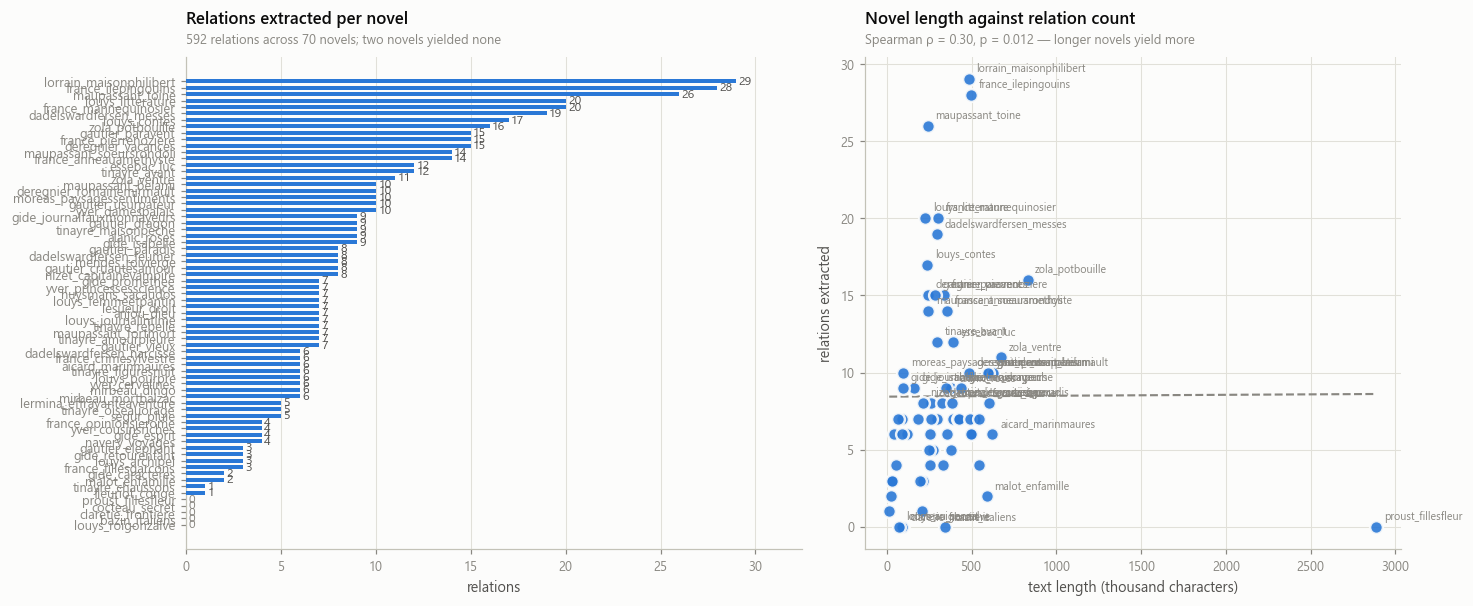


The regression line and ρ answer a question worth settling before anything else: is the
annotator simply finding more relations in longer books? Here ρ = **0.30** (p = 0.012),
so relation count is **partly a function of length**, which should be controlled for in per-novel comparisons.


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6),
                         gridspec_kw={"width_ratios": [1.15, 1]})

# --- left: relations per novel, ranked
d = novels.sort_values("n_relations")
y = np.arange(len(d))
ax = axes[0]
ax.barh(y, d["n_relations"], height=0.62, color=SERIES[0], zorder=3)
ax.set_yticks(y, [f"{r.novel_id}" for r in d.itertuples()])
for yi, v in zip(y, d["n_relations"]):
    ax.text(v + 0.12, yi, str(v), va="center", fontsize=8,
            color=INK_2 if v else MUTED)
ax.set_xlim(0, d["n_relations"].max() * 1.12)
ax.grid(axis="y", visible=False)
finish(ax, "Relations extracted per novel",
       f"{N_REL} relations across {len(novels)} novels; two novels yielded none",
       xlabel="relations")

# --- right: does a longer novel yield more relations?
ax = axes[1]
rho, p_rho = stats.spearmanr(novels["n_chars"], novels["n_relations"])
ax.scatter(novels["k_chars"], novels["n_relations"], s=70, color=SERIES[0],
           edgecolor=SURFACE, linewidth=1.6, zorder=3, alpha=0.9)
b, a = np.polyfit(novels["k_chars"], novels["n_relations"], 1)
xs = np.linspace(novels["k_chars"].min(), novels["k_chars"].max(), 50)
ax.plot(xs, a + b * xs, color=MUTED, linewidth=1.4, linestyle="--", zorder=2)
for r in novels.itertuples():
    if r.n_relations >= 8 or r.n_relations == 0 or r.k_chars > 550:
        ax.annotate(r.novel_id, (r.k_chars, r.n_relations), fontsize=7, color=MUTED,
                    xytext=(5, 5), textcoords="offset points")
finish(ax, "Novel length against relation count",
       f"Spearman ρ = {rho:.2f}, p = {p_rho:.3f} — "
       f"{'length does not drive the yield' if p_rho > .05 else 'longer novels yield more'}",
       xlabel="text length (thousand characters)", ylabel="relations extracted")
plt.tight_layout(); plt.show()

note(f"""
The regression line and ρ answer a question worth settling before anything else: is the
annotator simply finding more relations in longer books? Here ρ = **{rho:.2f}** (p = {p_rho:.3f}),
so relation count is {'**largely independent** of length — it reflects the novels, not their size'
if p_rho > .05 else '**partly a function of length**, which should be controlled for in per-novel comparisons'}.
""")

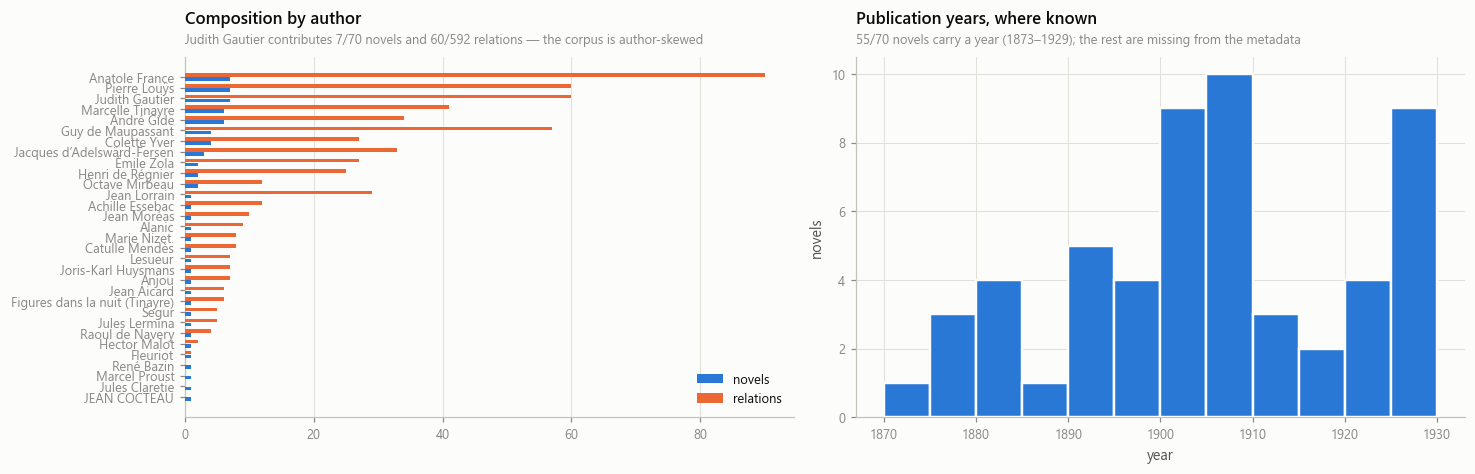


**Two structural caveats this figure makes concrete.** Judith Gautier accounts for
7/70 novels, so any corpus-level pattern may be one author's
habit; §H tests exactly that. And with only 55/70 years recorded, diachronic
claims are not yet available — the missingness is in the source metadata
(`metadata_source = filename`), not in the annotation.


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1, 1]})

# --- authors
ax = axes[0]
auth = (novels.groupby("author", observed=True)
        .agg(novels=("novel_id", "size"), relations=("n_relations", "sum"))
        .sort_values(["novels", "relations"]))
y = np.arange(len(auth))
ax.barh(y - 0.19, auth["novels"], height=0.34, color=SERIES[0], label="novels", zorder=3)
ax.barh(y + 0.19, auth["relations"], height=0.34, color=SERIES[1], label="relations", zorder=3)
ax.set_yticks(y, auth.index)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
top_a = auth["novels"].idxmax()
finish(ax, "Composition by author",
       f"{top_a} contributes {auth['novels'].max()}/{len(novels)} novels and "
       f"{auth.loc[top_a, 'relations']}/{N_REL} relations — the corpus is author-skewed")

# --- years
ax = axes[1]
yr = novels["year"].dropna().astype(int)
if len(yr):
    bins = np.arange((yr.min() // 5) * 5, (yr.max() // 5) * 5 + 10, 5)
    ax.hist(yr, bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=1.6, zorder=3)
    ax.set_xticks(bins[::2])
finish(ax, "Publication years, where known",
       f"{len(yr)}/{len(novels)} novels carry a year "
       f"({yr.min()}–{yr.max()}); the rest are missing from the metadata",
       xlabel="year", ylabel="novels")
plt.tight_layout(); plt.show()

note(f"""
**Two structural caveats this figure makes concrete.** {top_a} accounts for
{auth['novels'].max()}/{len(novels)} novels, so any corpus-level pattern may be one author's
habit; §H tests exactly that. And with only {len(yr)}/{len(novels)} years recorded, diachronic
claims are not yet available — the missingness is in the source metadata
(`metadata_source = filename`), not in the annotation.
""")

In [57]:
# Are relation counts per novel more variable than chance? (overdispersion)
cnt = novels["n_relations"].to_numpy()
mean, var = cnt.mean(), cnt.var(ddof=1)
disp = var / mean if mean else np.nan

# Poisson goodness-of-fit over binned counts, with a permutation p (expected counts are small)
kmax = int(cnt.max())
obs = np.bincount(cnt, minlength=kmax + 1).astype(float)
exp = stats.poisson.pmf(np.arange(kmax + 1), mean) * len(cnt)
# pool the tail so expected counts stay usable
cut = max(2, int(np.searchsorted(np.cumsum(exp) / exp.sum(), 0.9)))
obs_b = np.append(obs[:cut], obs[cut:].sum())
exp_b = np.append(exp[:cut], len(cnt) - exp[:cut].sum())
chi2_gof = float(((obs_b - exp_b) ** 2 / np.where(exp_b > 0, exp_b, np.nan)).sum())
null = np.array([
    ((np.bincount(np.clip(RNG.poisson(mean, len(cnt)), 0, cut), minlength=cut + 1).astype(float)
      - exp_b) ** 2 / np.where(exp_b > 0, exp_b, np.nan)).sum()
    for _ in range(N_PERM)])
p_gof = float((np.nansum(null >= chi2_gof) + 1) / (N_PERM + 1))

note(f"""
### B.1 Is the relation yield uniform across novels?

| statistic | value |
|---|---|
| mean relations / novel | {mean:.2f} |
| variance | {var:.2f} |
| dispersion index (var/mean) | **{disp:.2f}** |
| Poisson goodness-of-fit χ² (permutation p) | {chi2_gof:.2f} (p = {p_gof:.3f}) |

A dispersion index of 1 means relations arrive at a constant rate per novel; above 1 means the
yield clusters. Here it is **{disp:.2f}**, i.e. {'**overdispersed** — some novels are far richer in relations than a constant rate would predict, which is exactly why the clustered tests in this notebook are necessary' if disp > 1.5 else 'close to Poisson — relation yield is fairly uniform across novels' if disp < 1.3 else 'mildly overdispersed'}.
The permutation goodness-of-fit {'rejects' if p_gof < .05 else 'does not reject'} the Poisson model
(p = {p_gof:.3f}).
""")


### B.1 Is the relation yield uniform across novels?

| statistic | value |
|---|---|
| mean relations / novel | 8.46 |
| variance | 39.32 |
| dispersion index (var/mean) | **4.65** |
| Poisson goodness-of-fit χ² (permutation p) | 1720.65 (p = 0.000) |

A dispersion index of 1 means relations arrive at a constant rate per novel; above 1 means the
yield clusters. Here it is **4.65**, i.e. **overdispersed** — some novels are far richer in relations than a constant rate would predict, which is exactly why the clustered tests in this notebook are necessary.
The permutation goodness-of-fit rejects the Poisson model
(p = 0.000).


## C. Data-quality dashboard

An annotation corpus produced by a language model has failure modes a human corpus does not, and
they must be measured before the substantive analysis, not after. This section quantifies four of
them: schema violations, missing character names, thin evidence, and — the one that matters most
for a literary corpus — **invented quotations**.

In [32]:
bad = novels.loc[novels["has_error"], ["novel_id", "title", "error_kind", "error_msg",
                                       "n_relations"]]
note(f"""
### C.1 Records that failed validation

**{len(bad)} of {len(novels)} records** carry a schema error, yet between them they hold
**{int(bad['n_relations'].sum())} of {N_REL} relations ({bad['n_relations'].sum()/N_REL:.0%})**.
Dropping them on `ok` alone would silently delete a quarter of the corpus, so they are kept and
flagged. What follows identifies precisely what is wrong with them, so they can be re-run rather
than discarded.
""")
display(bad.style.hide(axis="index")) if len(bad) else note("No validation errors in this run.")


### C.1 Records that failed validation

**4 of 18 records** carry a schema error, yet between them they hold
**22 of 85 relations (26%)**.
Dropping them on `ok` alone would silently delete a quarter of the corpus, so they are kept and
flagged. What follows identifies precisely what is wrong with them, so they can be re-run rather
than discarded.


novel_id,title,error_kind,error_msg,n_relations
anjou_dieu,Dieu,validation_error,[] should be non-empty,4
gautier_cruautesamour,Les Cruautés de l’Amour,validation_error,[] should be non-empty,7
gautier_lucienne,Lucienne,validation_error,[] should be non-empty,6
gautier_usurpateur,L’Usurpateur,validation_error,None is not of type 'string',5


In [33]:
# --- empty character lists
empty = relations.loc[relations["has_empty_characters"],
                      ["novel_id", "relation_id", "status", "framing", "n_evidence", "ok"]]
n_novels_empty = empty["novel_id"].nunique()

note(f"""
### C.2 Relations with no character names

**{len(empty)} of {N_REL} relations ({len(empty)/N_REL:.0%})**, spread over
**{n_novels_empty} novels**, have an empty `characters` array — even though the schema requires
at least one entry. This is the concrete cause of the `[] should be non-empty` validation errors.

The relations themselves are otherwise fully coded, so they remain usable for every
label-distribution analysis below; what they cannot support is §I's character-level network.
""")
if len(empty):
    display(empty.groupby("novel_id", observed=True)
            .agg(relations_affected=("relation_id", "count"),
                 relation_ids=("relation_id", lambda s: ", ".join(s)),
                 record_ok=("ok", "first")))


### C.2 Relations with no character names

**17 of 85 relations (20%)**, spread over
**3 novels**, have an empty `characters` array — even though the schema requires
at least one entry. This is the concrete cause of the `[] should be non-empty` validation errors.

The relations themselves are otherwise fully coded, so they remain usable for every
label-distribution analysis below; what they cannot support is §I's character-level network.


,relations_affected,relation_ids,record_ok
novel_id,,,
anjou_dieu,4,"R1, R2, R3, R4",False
gautier_cruautesamour,7,"R1, R2, R3, R4, R5, R6, R7",False
gautier_lucienne,6,"R1, R2, R3, R4, R5, R6",False


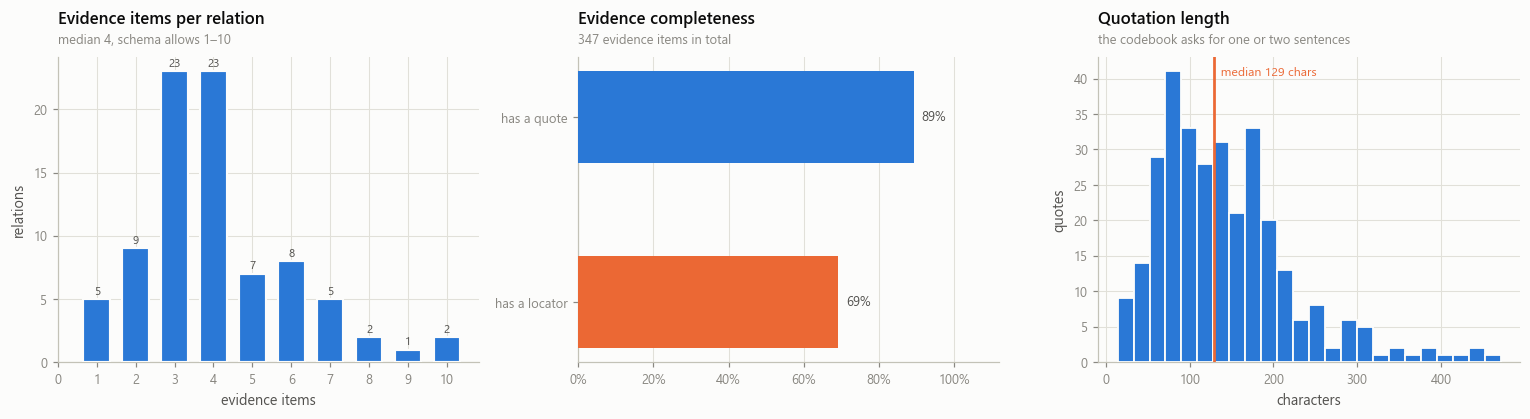

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

# --- evidence per relation
ax = axes[0]
vc = relations["n_evidence"].value_counts().sort_index()
ax.bar(vc.index, vc.values, color=SERIES[0], width=0.68, zorder=3,
       edgecolor=SURFACE, linewidth=1.4)
for x, v in vc.items():
    ax.text(x, v + 0.4, str(v), ha="center", fontsize=7.5, color=INK_2)
ax.set_xticks(range(0, int(relations["n_evidence"].max()) + 1))
finish(ax, "Evidence items per relation",
       f"median {relations['n_evidence'].median():.0f}, "
       f"schema allows 1–10", xlabel="evidence items", ylabel="relations")

# --- quote & locator coverage
ax = axes[1]
cov = pd.Series({
    "has a quote":   evidence["has_quote"].mean(),
    "has a locator": evidence["has_locator"].mean(),
})
y = np.arange(len(cov))[::-1]
ax.barh(y, cov.values, height=0.5, color=[SERIES[0], SERIES[1]], zorder=3)
ax.set_yticks(y, cov.index)
for yi, v in zip(y, cov.values):
    ax.text(v + .02, yi, f"{v:.0%}", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
finish(ax, "Evidence completeness",
       f"{N_EV} evidence items in total")

# --- quote length
ax = axes[2]
ql = evidence.loc[evidence["has_quote"], "quote_len"]
ax.hist(ql, bins=24, color=SERIES[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.axvline(ql.median(), color=SERIES[1], linewidth=1.8, zorder=4)
ax.text(ql.median(), ax.get_ylim()[1] * 0.94, f"  median {ql.median():.0f} chars",
        fontsize=8, color=SERIES[1])
finish(ax, "Quotation length",
       "the codebook asks for one or two sentences",
       xlabel="characters", ylabel="quotes")
plt.tight_layout(); plt.show()

### C.3 Are the quotations real? — verbatim verification against the source text

The codebook requires quotes to be copied exactly from the novel, and they are the evidential
backbone of the whole corpus: if the quotes are invented, the labels they justify are not
auditable. So every quote is looked up in the source text of its own novel, through five
escalating passes:

1. **exact** — after Unicode normalisation, unifying curly quotes, dashes and non-breaking
   spaces, rejoining words the source hyphenates across a line break, and collapsing whitespace;
2. **punctuation-insensitive** — same word sequence, punctuation ignored (catches a comma the
   model dropped);
3. **elided** — the quote contains `[...]` or `…` and *every* segment between the elisions is
   found in the novel, in order. This turned out to matter enormously: the annotator frequently
   stitches two separated passages into one quotation. That breaches the codebook's
   "quote exactly" rule, but it is emphatically **not** invention, and a checker that did not
   test for it would report those quotes as hallucinated;
4. **near-verbatim** — an anchor n-gram is located and a similarity ratio computed over the
   surrounding window; ≥ 0.85 counts as a match with minor transcription drift;
5. **partial** — at least 70 % of the quote's 5-word shingles occur in the novel, so the passage
   is demonstrably derived from the text even though no contiguous form of it appears.

Only what fails all five is genuinely **not traceable to the novel**. Two figures are therefore
reported and should not be conflated: the **verbatim rate** (passes 1–2, what the codebook asks
for) and the **hallucination rate** (the residue that fails every pass).

In [ ]:
from difflib import SequenceMatcher

def _normalise(text):
    """Strict normalisation: Unicode, typographic variants, line-break hyphenation, whitespace."""
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("­", "").replace("﻿", "")
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)        # re-join words split across lines
    for a, b in (("’", "'"), ("‘", "'"), ("«", '"'), ("»", '"'),
                 ("“", '"'), ("”", '"'), ("—", "-"), ("–", "-"),
                 ("…", "..."), (" ", " ")):
        text = text.replace(a, b)
    return re.sub(r"\s+", " ", text).strip().casefold()

def _normalise_loose(text):
    """Same word sequence, punctuation discarded."""
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", _normalise(text), flags=re.UNICODE)).strip()

def _novel_key(x):
    return re.sub(r"__p\d+$", "", str(x).strip().casefold())

# Stream the corpus and keep only the novels this run touched (the file is ~125 MB).
wanted = {_novel_key(n) for n in novels["novel_id"]}
raw_text = defaultdict(list)
if CORPUS_PATH.exists():
    with CORPUS_PATH.open(encoding="utf-8-sig") as fh:
        for line in fh:
            if not line.strip():
                continue
            rec = json.loads(line)
            key = _novel_key(rec.get("novel_id"))
            if key in wanted and rec.get("text"):
                raw_text[key].append(str(rec["text"]))

src_strict = {k: _normalise(" ".join(v)) for k, v in raw_text.items()}
src_loose  = {k: _normalise_loose(" ".join(v)) for k, v in raw_text.items()}
del raw_text

print(f"source text loaded for {len(src_strict)}/{len(wanted)} novels "
      f"({sum(len(v) for v in src_strict.values())/1e6:.1f} M normalised characters)")
missing_src = sorted(wanted - set(src_strict))
if missing_src:
    print("no source text for:", ", ".join(missing_src))

In [ ]:
FUZZY_THRESHOLD = 0.85      # similarity for "near-verbatim"
SHINGLE_COVERAGE = 0.70     # share of 5-word shingles present, for "partial"
ANCHOR_WORDS = 5
ELLIPSIS = re.compile(r"\[\s*\.\.\.\s*\]|\.\.\.+")

def _shingle_coverage(words, text, n=5):
    grams = [" ".join(words[i:i + n]) for i in range(len(words) - n + 1)]
    return sum(g in text for g in grams) / len(grams) if grams else 0.0

def verify_quote(quote, key):
    """Return (verdict, score). Verdicts, in order of fidelity, are defined in the cell above."""
    strict, loose = src_strict.get(key), src_loose.get(key)
    if strict is None:
        return "no-source", np.nan

    q_strict = _normalise(quote)
    if q_strict and q_strict in strict:
        return "exact", 1.0

    q_loose = _normalise_loose(quote)
    if q_loose and q_loose in loose:
        return "punctuation", 1.0

    # 3. elided: split on [...] / … and require every substantial segment, in order
    segs = [_normalise_loose(s) for s in ELLIPSIS.split(q_strict)]
    segs = [s for s in segs if len(s.split()) >= 3]
    if len(segs) >= 2:
        pos, ok = 0, True
        for s in segs:
            found = loose.find(s, pos)
            if found == -1:
                ok = False
                break
            pos = found + len(s)
        if ok:
            return "elided", 1.0

    words = q_loose.split()
    if len(words) < 3:
        return "not-found", 0.0

    # 4. near-verbatim: anchor, then score the surrounding window
    best = 0.0
    for start in range(0, max(1, len(words) - ANCHOR_WORDS + 1)):
        p = loose.find(" ".join(words[start:start + ANCHOR_WORDS]))
        if p == -1:
            continue
        lo_ = max(0, p - start * 8 - 40)
        best = max(best, SequenceMatcher(
            None, q_loose, loose[lo_: lo_ + int(len(q_loose) * 1.5) + 80]).ratio())
        if best >= FUZZY_THRESHOLD:
            return "near-verbatim", best

    # 5. partial: demonstrably derived from the text, but not contiguous anywhere
    cov = _shingle_coverage(words, loose)
    if cov >= SHINGLE_COVERAGE:
        return "partial", cov
    return "not-found", max(best, cov)

VERIFY_ORDER = ["exact", "punctuation", "elided", "near-verbatim", "partial",
                "not-found", "no-source"]
VERBATIM = ["exact", "punctuation"]
TRACEABLE = ["exact", "punctuation", "elided", "near-verbatim", "partial"]

ev_q = evidence["has_quote"]
evidence["verify"] = pd.NA
evidence["verify_score"] = np.nan
res = [verify_quote(q, _novel_key(n))
       for q, n in zip(evidence.loc[ev_q, "quote"], evidence.loc[ev_q, "novel_id"])]
evidence.loc[ev_q, "verify"] = [r[0] for r in res]
evidence.loc[ev_q, "verify_score"] = [r[1] for r in res]
evidence["verify"] = pd.Categorical(evidence["verify"], categories=VERIFY_ORDER, ordered=True)
evidence["verified"] = evidence["verify"].isin(TRACEABLE)     # traceable to the novel
evidence["verbatim"] = evidence["verify"].isin(VERBATIM)      # as the codebook requires

checked = int(ev_q.sum())
vc = evidence.loc[ev_q, "verify"].value_counts().reindex(VERIFY_ORDER).fillna(0).astype(int)
n_trace = int(evidence.loc[ev_q, "verified"].sum())
n_verb = int(evidence.loc[ev_q, "verbatim"].sum())
h_lo, h_hi = wilson_ci(checked - n_trace, checked)

summary = pd.DataFrame({
    "evidence items": vc,
    "share of checked quotes": vc / checked,
    "counts as": ["verbatim (codebook-compliant)", "verbatim (codebook-compliant)",
                  "traceable, not verbatim", "traceable, not verbatim",
                  "traceable, not verbatim", "NOT TRACEABLE", "—"],
}).rename_axis("verification")
display(summary.style.format({"share of checked quotes": "{:.1%}"}))

note(f"""
**Two rates, and they are very different.**

| | count | share of the {checked} quotations |
|---|---|---|
| **verbatim** — exact, or exact once punctuation is ignored | {n_verb} | **{n_verb/checked:.1%}** |
| **traceable** — verbatim, elided, near-verbatim or partial | {n_trace} | **{n_trace/checked:.1%}** |
| **not traceable to the novel at all** | {checked - n_trace} | **{1 - n_trace/checked:.1%}** (95% Wilson CI {h_lo:.1%}–{h_hi:.1%}) |

The **hallucination rate is {1 - n_trace/checked:.1%}** — the bottom row. The gap between the two
top rows is almost entirely the `elided` category ({vc['elided']} quotations,
{vc['elided']/checked:.1%}): passages the annotator stitched together across an ellipsis. Those
are real text from the real novel and the labels they support stand, but they are not verbatim,
so a reader checking a page reference would not find them as printed.

Reporting only the verbatim rate would overstate hallucination by roughly
{(n_trace - n_verb)/checked:.0%} of the corpus. The fix is a prompt instruction, not a re-run:
one quotation per evidence item, no elisions.
""")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})

# --- per-novel traceability, with the verbatim share shown inside it
per_novel = (evidence.loc[ev_q].groupby("novel_id", observed=True)
             .agg(quotes=("verified", "size"), verified=("verified", "sum"),
                  verbatim=("verbatim", "sum")))
per_novel["rate"] = per_novel["verified"] / per_novel["quotes"]
per_novel["verbatim_rate"] = per_novel["verbatim"] / per_novel["quotes"]
per_novel = per_novel.sort_values("rate")
ax = axes[0]
y = np.arange(len(per_novel))
colours = [SERIES[7] if r < .6 else SERIES[3] if r < .9 else SERIES[0] for r in per_novel["rate"]]
ax.barh(y, per_novel["rate"], height=0.62, color=colours, zorder=3,
        label="traceable to the novel")
ax.barh(y, per_novel["verbatim_rate"], height=0.30, color=INK_2, zorder=4,
        label="verbatim as printed")
ax.set_yticks(y, [f"{i}" for i in per_novel.index])
for yi, (r, q, v) in enumerate(zip(per_novel["rate"], per_novel["quotes"], per_novel["verified"])):
    ax.text(r + .012, yi, f"{r:.0%}  ({v}/{q})", va="center", fontsize=7.5, color=INK_2)
ax.set_xlim(0, 1.2)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
finish(ax, "Quote traceability by novel",
       "outer bar = found in the novel in some form · inner bar = verbatim · "
       "red < 60%, amber < 90% traceable",
       xlabel="share of the novel's quotations")

# --- verification against the model's own confidence
ax = axes[1]
conf_of_quote = (relations.set_index("uid")["confidence"]
                 .astype(str).reindex(evidence.loc[ev_q, "uid"].values).values)
conf_ver = (pd.crosstab(conf_of_quote, evidence.loc[ev_q, "verified"].values)
            .reindex(columns=[False, True]).fillna(0).astype(int))
conf_ver.columns = ["not found", "verified"]
conf_ver = conf_ver.reindex([c for c in LEVELS["confidence"] if c in conf_ver.index])
stacked_pct(conf_ver[["verified", "not found"]], ax=ax, colors=[SERIES[0], SERIES[7]])
t_cv = assoc_test(conf_of_quote, evidence.loc[ev_q, "verified"].values)
finish(ax, "Does the model know when it is inventing?",
       f"quote verification by stated confidence — {t_cv['test']}, "
       f"p = {t_cv['p']:.3f}, V = {t_cv['v']:.2f}")
plt.tight_layout(); plt.show()

worst = per_novel[per_novel["rate"] < 0.9]
note(f"""
{'**' + str(len(worst)) + ' novels fall below 90% traceability**: ' + ', '.join(f'`{i}` ({r:.0%})' for i, r in worst['rate'].items()) + '. These are the records to hand-check first.' if len(worst) else 'Every novel clears 90% traceability.'}

The gap between each pair of bars is the elision problem: a novel with a high outer bar and a low
inner one is being quoted accurately but not verbatim.

The right-hand panel asks whether the model's own `confidence` field is a usable signal here — if
untraceable quotes concentrated in `medium`/`low` relations, confidence could serve as a filter.
The association is {'**significant**' if t_cv['p'] < .05 else '**not significant**'}
(p = {t_cv['p']:.3f}, V = {t_cv['v']:.2f} — {v_magnitude(t_cv['v'])}), so confidence
{'can be used as a partial screen' if t_cv['p'] < .05 else 'is **not** a usable proxy for quote fidelity: quotes have to be checked directly, as they are here'}.
""")

In [ ]:
# A concrete look at the failures, so they can be judged by eye rather than by rate alone.
bad_q = (evidence.loc[ev_q & evidence["verify"].eq("not-found"),
                      ["novel_id", "relation_id", "quote", "locator", "verify_score"]]
         .sort_values("verify_score", ascending=False))
note(f"""
#### The {len(bad_q)} quotations that are not traceable to the novel

`verify_score` is the better of the best anchored-window similarity and the 5-word shingle
coverage. Values approaching {FUZZY_THRESHOLD}–{SHINGLE_COVERAGE} are near-misses that just fell
short of a pass; values near 0 mean nothing resembling the passage occurs in the text at all.
Sort by this column and start at the bottom — those are the clear fabrications.
""")
display(bad_q.head(30).style.format({"verify_score": "{:.2f}"}, na_rep="—").hide(axis="index"))
if len(bad_q) > 30:
    note(f"_… and {len(bad_q) - 30} more._")

In [ ]:
# --- how often does the codebook fail to resolve a case?
unclear = pd.DataFrame({
    "unclear": [(relations[f] == "unclear").sum() for f in CLOSED_FIELDS],
}, index=CLOSED_FIELDS)
unclear["share"] = unclear["unclear"] / N_REL
unclear["labels offered"] = [len(LEVELS[f]) for f in CLOSED_FIELDS]
unclear["labels used"] = [len(observed_levels(f)) for f in CLOSED_FIELDS]
unclear = unclear.sort_values("share", ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(unclear))
ax.barh(y, unclear["share"], height=0.6,
        color=[SERIES[3] if s > .15 else SERIES[0] for s in unclear["share"]], zorder=3)
ax.set_yticks(y, [pretty_field(i) for i in unclear.index])
for yi, (s, n) in enumerate(zip(unclear["share"], unclear["unclear"])):
    ax.text(s + .004, yi, f"{s:.0%}" + (f"  (n={n})" if n else ""), va="center",
            fontsize=8, color=INK_2 if n else MUTED)
ax.set_xlim(0, max(unclear["share"].max() * 1.35, 0.05))
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
finish(ax, "How often is a field left `unclear`?",
       "a high rate means the codebook does not let the annotator settle that question",
       xlabel="share of relations coded unclear")
plt.show()

top_unclear = unclear.sort_values("share", ascending=False).head(3)
note(f"""
### C.4 Where the codebook does not resolve

`unclear` is not missing data — it is a substantive label meaning *the text does not settle the
question*. Its rate per field is therefore a direct measure of how well each dimension of the
codebook can be applied to this material.

The three least decidable fields are
{', '.join(f'**{pretty_field(i)}** ({r.share:.0%})' for i, r in top_unclear.iterrows())}.
{'`exclusivity` standing out is expected and interpretable: the field asks what rules a couple operates under, and nineteenth-century narration very often simply does not say.' if 'exclusivity' in top_unclear.index else ''}
""")
display(unclear.sort_values("share", ascending=False)
        .style.format({"share": "{:.1%}"}))

## D. Univariate distributions

What the corpus contains, one field at a time. Three things are done differently from a routine
`value_counts()`:

- **Codebook order, with zeros shown.** Labels appear in the order the codebook defines them, and
  labels the model never used are drawn grey at zero rather than omitted — an unused label is a
  finding about the codebook, not an absence of data.
- **Two confidence intervals per proportion.** The Wilson interval treats the 85 relations as 85
  independent observations. The cluster bootstrap resamples *novels*. The gap between them is the
  price of clustering, and it is not small.
- **Entropy per field**, to answer which dimensions actually discriminate between relations and
  which are effectively constant.

In [58]:
rows = []
for f in CLOSED_FIELDS:
    counts = relations[f].value_counts().reindex(LEVELS[f]).fillna(0).astype(int)
    for lab, k in counts.items():
        w_lo, w_hi = wilson_ci(k, N_REL)
        c_lo, c_hi = cluster_bootstrap_ci(relations, f, lab) if k else (0.0, 0.0)
        rows.append({
            "family": FAMILY_OF[f], "field": f, "label": lab, "n": k, "share": k / N_REL,
            "wilson_lo": w_lo, "wilson_hi": w_hi,
            "cluster_lo": c_lo, "cluster_hi": c_hi,
            "novels": int(relations.loc[relations[f] == lab, "novel_id"].nunique()),
        })
freq = pd.DataFrame(rows)
freq["ci_width_ratio"] = ((freq["cluster_hi"] - freq["cluster_lo"]) /
                          (freq["wilson_hi"] - freq["wilson_lo"]).replace(0, np.nan))

note(f"""
### D.1 Frequency table for all {len(CLOSED_FIELDS)} closed fields

`novels` counts how many distinct books contribute at least one relation with that label — a
label carried by 12 relations from a single novel is a very different fact from one carried by 12
relations across 12 novels. `ci_width_ratio` is the cluster-bootstrap interval width divided by
the Wilson width: values above 1 mean the naive interval is too narrow because the observations
are clustered.
""")
display(freq.style.format({"share": "{:.1%}", "wilson_lo": "{:.2f}", "wilson_hi": "{:.2f}",
                           "cluster_lo": "{:.2f}", "cluster_hi": "{:.2f}",
                           "ci_width_ratio": "{:.2f}"}, na_rep="—")
        .background_gradient(subset=["share"], cmap=SEQ, vmin=0, vmax=0.6)
        .hide(axis="index"))

infl = freq.loc[freq["n"] >= 5, "ci_width_ratio"].median()
note(f"""
Across labels with at least 5 observations the cluster interval is a median
**{infl:.2f}×** the width of the naive one. {'That is the quantitative case for the clustered tests used from §E onward.' if infl > 1.1 else ''}
""")


### D.1 Frequency table for all 12 closed fields

`novels` counts how many distinct books contribute at least one relation with that label — a
label carried by 12 relations from a single novel is a very different fact from one carried by 12
relations across 12 novels. `ci_width_ratio` is the cluster-bootstrap interval width divided by
the Wilson width: values above 1 mean the naive interval is too narrow because the observations
are clustered.


family,field,label,n,share,wilson_lo,wilson_hi,cluster_lo,cluster_hi,novels,ci_width_ratio
Participants and shape,relation_type,female_male,501,84.6%,0.82,0.87,0.80,0.89,62,1.63
Participants and shape,relation_type,female_female,14,2.4%,0.01,0.04,0.01,0.05,6,1.64
Participants and shape,relation_type,male_male,53,9.0%,0.07,0.12,0.06,0.13,29,1.55
Participants and shape,relation_type,mixed_gender,16,2.7%,0.02,0.04,0.01,0.04,12,1.03
Participants and shape,relation_type,unknown_gender,3,0.5%,0.00,0.01,0.00,0.01,3,0.89
Participants and shape,relation_type,queer,4,0.7%,0.00,0.02,0.00,0.02,3,1.05
Participants and shape,relation_type,unclear,1,0.2%,0.00,0.01,0.00,0.01,1,0.60
Participants and shape,structure,dyadic,509,86.0%,0.83,0.89,0.83,0.89,65,1.13
Participants and shape,structure,triangular,24,4.1%,0.03,0.06,0.02,0.06,18,1.09
Participants and shape,structure,group_or_milieu,17,2.9%,0.02,0.05,0.01,0.05,11,1.25



Across labels with at least 5 observations the cluster interval is a median
**1.20×** the width of the naive one. That is the quantitative case for the clustered tests used from §E onward.


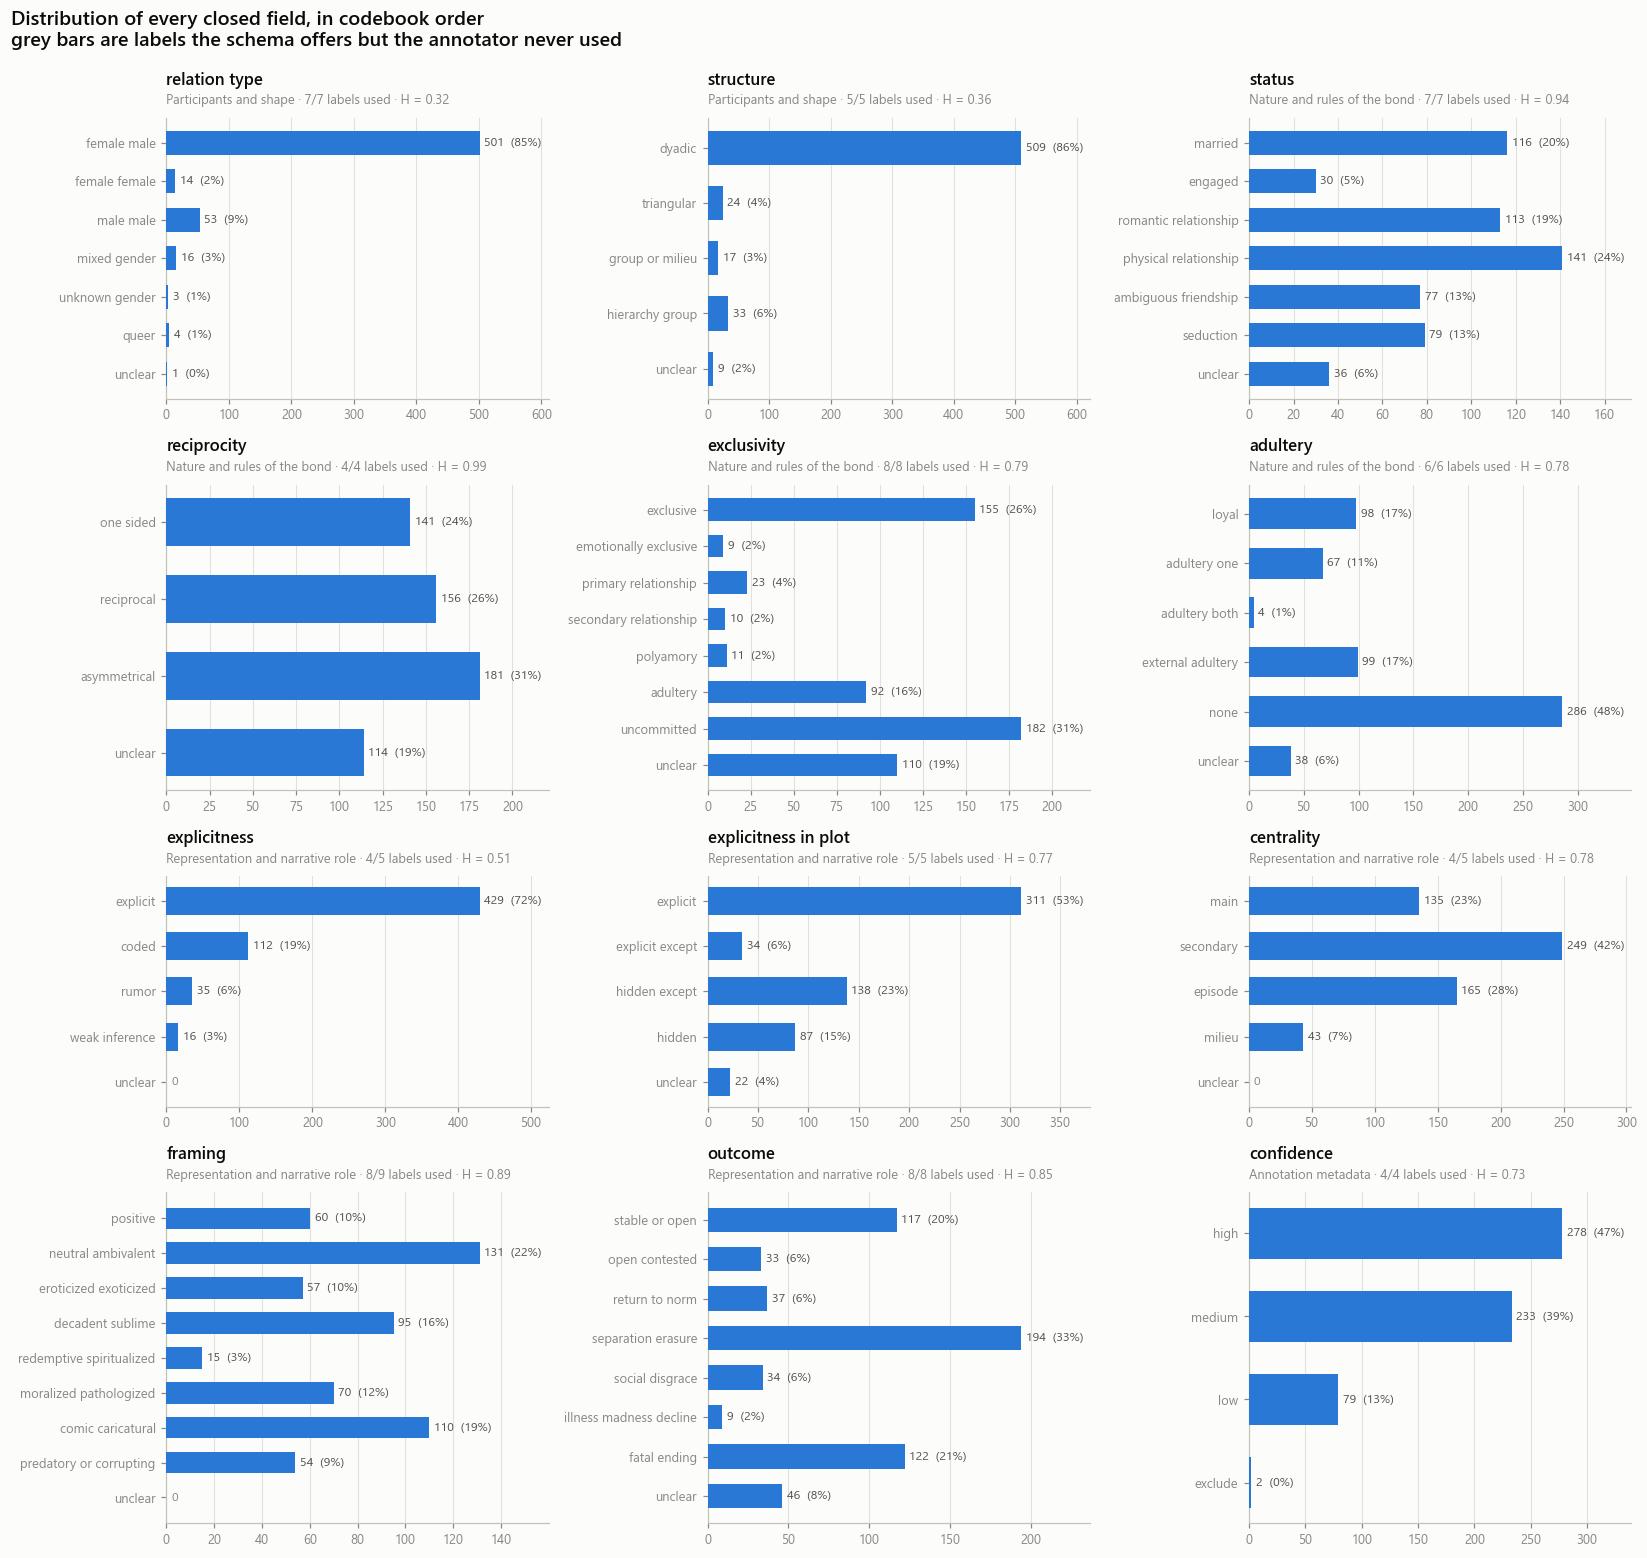

In [59]:
ncol = 3
fields_grid = CLOSED_FIELDS
nrow = math.ceil(len(fields_grid) / ncol)
heights = [max([len(LEVELS[f]) for f in fields_grid[r*ncol:(r+1)*ncol]] or [1])
           for r in range(nrow)]
fig, axes = plt.subplots(nrow, ncol, figsize=(15, sum(0.30 * h + 1.25 for h in heights)),
                         gridspec_kw={"height_ratios": [0.30 * h + 1.25 for h in heights]})
axes = np.atleast_2d(axes)

for i, f in enumerate(fields_grid):
    ax = axes[i // ncol][i % ncol]
    colour = SERIES[0] if f in ANALYSABLE else ZERO_GREY
    bar_counts(f, ax=ax, color=colour)
    tag = "" if f in ANALYSABLE else "  ·  degenerate, excluded from tests"
    finish(ax, f"{pretty_field(f)}{tag}",
           f"{FAMILY_OF[f]} · {len(observed_levels(f))}/{len(LEVELS[f])} labels used "
           f"· H = {norm_entropy(relations[f], f):.2f}")
for j in range(len(fields_grid), nrow * ncol):
    axes[j // ncol][j % ncol].set_visible(False)

plt.tight_layout()
fig.suptitle("Distribution of every closed field, in codebook order\n"
             "grey bars are labels the schema offers but the annotator never used",
             x=0.005, ha="left", va="bottom", fontsize=13, fontweight="semibold",
             color=INK, y=1.004)
plt.show()

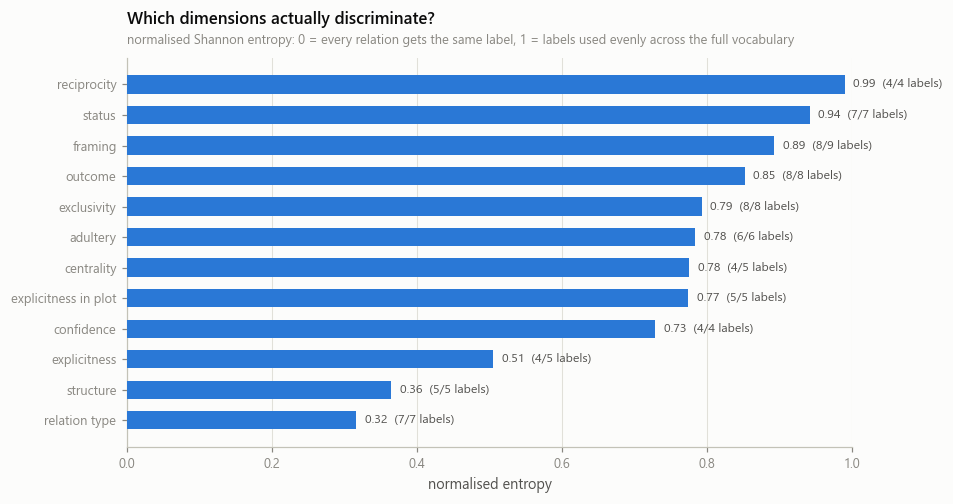


### D.2 Discriminating power

Entropy is normalised by the number of labels the **schema offers**, not by the number used, so a
field is penalised both for concentrating on one label and for leaving most of its vocabulary
idle.

- **reciprocity** (H = 0.99) spreads most evenly and carries the
  most information per relation.
- **relation type** and **structure**
  (H = 0.32, 0.36) are near-constant in this sample. For
  `relation_type` and `structure` that is a property of *this* slice of the corpus — every novel
  here is by a heterosexual woman author, and almost every relation is a `female_male` `dyadic`
  pair. These fields should become informative as soon as the lesbian, gay and heterosexual-men
  subcorpora are annotated, which is precisely the comparison §K is built for.


In [61]:
ent = (pd.Series({f: norm_entropy(relations[f], f) for f in CLOSED_FIELDS})
       .sort_values())
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(ent))
ax.barh(y, ent.values, height=0.6,
        color=[SERIES[0] if f in ANALYSABLE else ZERO_GREY for f in ent.index], zorder=3)
ax.set_yticks(y, [pretty_field(i) for i in ent.index])
for yi, (f, v) in enumerate(ent.items()):
    ax.text(v + .012, yi, f"{v:.2f}  ({len(observed_levels(f))}/{len(LEVELS[f])} labels)",
            va="center", fontsize=8, color=INK_2)
ax.set_xlim(0, 1.0)
ax.grid(axis="y", visible=False)
finish(ax, "Which dimensions actually discriminate?",
       "normalised Shannon entropy: 0 = every relation gets the same label, "
       "1 = labels used evenly across the full vocabulary",
       xlabel="normalised entropy")
plt.show()

note(f"""
### D.2 Discriminating power

Entropy is normalised by the number of labels the **schema offers**, not by the number used, so a
field is penalised both for concentrating on one label and for leaving most of its vocabulary
idle.

- **{pretty_field(ent.index[-1])}** (H = {ent.iloc[-1]:.2f}) spreads most evenly and carries the
  most information per relation.
- **{pretty_field(ent.index[0])}** and **{pretty_field(ent.index[1])}**
  (H = {ent.iloc[0]:.2f}, {ent.iloc[1]:.2f}) are near-constant in this sample. For
  `relation_type` and `structure` that is a property of *this* slice of the corpus — every novel
  here is by a heterosexual woman author, and almost every relation is a `female_male` `dyadic`
  pair. These fields should become informative as soon as the lesbian, gay and heterosexual-men
  subcorpora are annotated, which is precisely the comparison §K is built for.
""")

In [62]:
unused = [{"field": f, "family": FAMILY_OF[f], "unused label": lab,
           "codebook definition": (GLOSS[f].get(lab) or "")[:150]}
          for f in CLOSED_FIELDS for lab in LEVELS[f]
          if (relations[f] == lab).sum() == 0]
unused = pd.DataFrame(unused)

note(f"""
### D.3 Labels the annotator never used

**{len(unused)} of {sum(len(v) for v in LEVELS.values())} labels** in the schema vocabulary
received zero relations. Each is one of three things, and telling them apart is a codebook
decision rather than a statistical one:

1. genuinely absent from this material (`female_female` in a corpus of heterosexual-women
   authors — expected, and will fill in as the corpus grows);
2. present in the novels but not being recognised by the annotator (a prompt or codebook problem);
3. a distinction too fine to apply in practice (a candidate for merging in the next codebook
   revision).
""")
display(unused.style.hide(axis="index")) if len(unused) else note("Every schema label was used.")


### D.3 Labels the annotator never used

**3 of 73 labels** in the schema vocabulary
received zero relations. Each is one of three things, and telling them apart is a codebook
decision rather than a statistical one:

1. genuinely absent from this material (`female_female` in a corpus of heterosexual-women
   authors — expected, and will fill in as the corpus grows);
2. present in the novels but not being recognised by the annotator (a prompt or codebook problem);
3. a distinction too fine to apply in practice (a candidate for merging in the next codebook
   revision).


field,family,unused label,codebook definition
explicitness,Representation and narrative role,unclear,the degree of explicitness cannot be determined
centrality,Representation and narrative role,unclear,centrality cannot be determined
framing,Representation and narrative role,unclear,the dominant framing cannot be determined


## E. The association matrix

Which annotation dimensions move together? This is the question the codebook itself raises: it
claims, for instance, that `explicitness` and `explicitness_in_plot` are *independent* axes, and
that `relation_type` and `structure` measure different things. Those claims are testable.

Every analysable field is crossed with every other one. Three quantities are computed for each
pair:

- **Cramér's *V*** with the Bergsma bias correction. At n = 85 the uncorrected *V* is badly
  inflated for large tables; the correction subtracts the expected value under independence, so a
  9 × 8 table of noise scores near 0 rather than near 0.4.
- **a naive *p*** from `assoc_test`, which selects Fisher, permutation χ², or asymptotic χ²
  according to the expected counts, and reports which it used.
- **a within-novel permutation *p***, which asks whether the association survives once each
  novel's own label mix is held fixed.

Because dozens of tests are run at once, both Holm (family-wise) and Benjamini–Hochberg (false
discovery rate) corrections are applied. Uncorrected *p*-values from a matrix this size should
not be read on their own.

In [63]:
pairs = [(a, b) for i, a in enumerate(ANALYSABLE) for b in ANALYSABLE[i + 1:]]
print(f"testing {len(pairs)} field pairs "
      f"({len(ANALYSABLE)} analysable fields; {len(DEGENERATE)} degenerate fields excluded)")

rows = []
for a, b in pairs:
    t = assoc_test(relations[a], relations[b])
    p_cl, n_used, n_inf = cluster_permutation_p(relations, a, b)
    rows.append({
        "field A": a, "field B": b,
        "V": t["v"], "effect": v_magnitude(t["v"]),
        "test": t["test"], "p": t["p"], "p (within-novel)": p_cl,
        "min expected": t["min_expected"], "n": t["n"],
        "informative novels": n_inf,
        "underpowered": t["underpowered"],
    })
assoc = pd.DataFrame(rows)
assoc["p Holm"] = holm(assoc["p"])
assoc["q BH"]   = bh_fdr(assoc["p"])
assoc["p (within-novel) BH"] = bh_fdr(assoc["p (within-novel)"])
assoc["sig"] = [stars(p) for p in assoc["q BH"]]
assoc = assoc.sort_values("V", ascending=False).reset_index(drop=True)
print(f"done — {(assoc['q BH'] < ALPHA).sum()} pairs significant at BH q < {ALPHA}, "
      f"{(assoc['p Holm'] < ALPHA).sum()} at Holm")

testing 66 field pairs (12 analysable fields; 0 degenerate fields excluded)
done — 63 pairs significant at BH q < 0.05, 57 at Holm


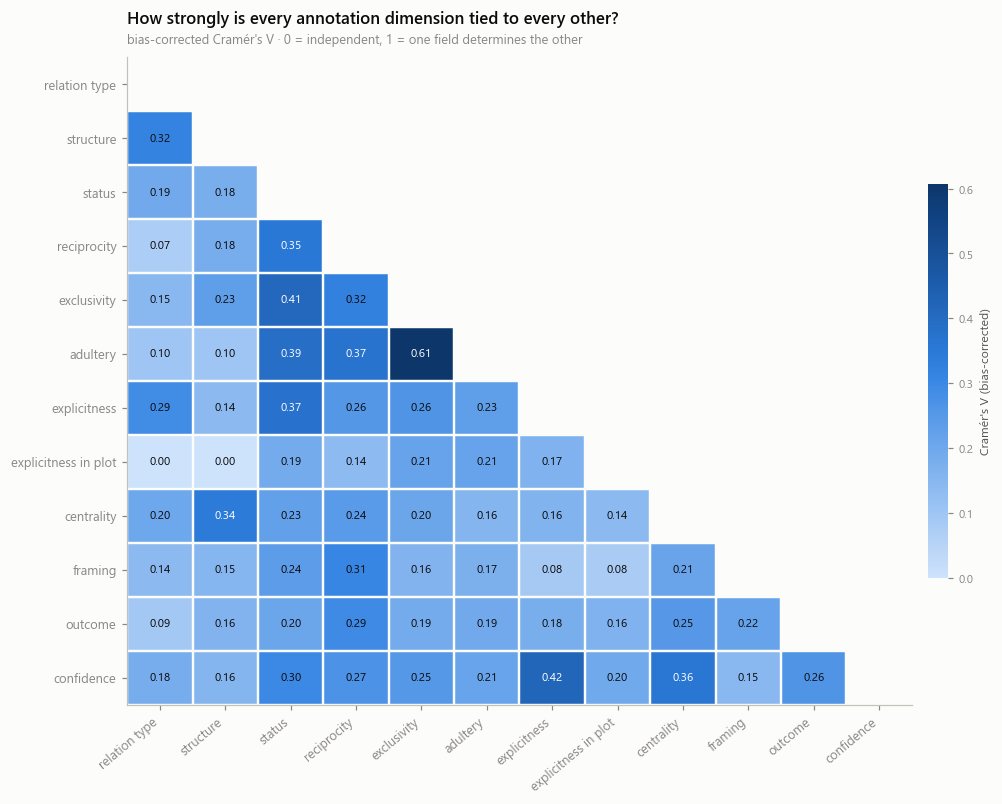


The strongest tie in the corpus is **exclusivity ↔ adultery**
(V = 0.61, very large). The matrix is dominated by the
bond-family fields, which is what one would expect if the codebook's three families are real
groupings rather than an arbitrary arrangement — related fields should cluster.


In [64]:
# Square matrices for the heatmaps
def _sym(col):
    m = pd.DataFrame(np.nan, index=ANALYSABLE, columns=ANALYSABLE, dtype=float)
    for _, r in assoc.iterrows():
        m.loc[r["field A"], r["field B"]] = r[col]
        m.loc[r["field B"], r["field A"]] = r[col]
    return m

V_MAT = _sym("V")
np.fill_diagonal(V_MAT.values, np.nan)

fig, ax = plt.subplots(figsize=(9.2, 7.4))
heatmap(V_MAT, ax=ax, cmap=SEQ, vmin=0, vmax=max(0.5, np.nanmax(V_MAT.values)),
        fmt="{:.2f}", cbar_label="Cramér's V (bias-corrected)", mask_upper=True)
finish(ax, "How strongly is every annotation dimension tied to every other?",
       "bias-corrected Cramér's V · 0 = independent, 1 = one field determines the other")
plt.tight_layout(); plt.show()

top = assoc.head(8)
note(f"""
The strongest tie in the corpus is **{pretty_field(top.iloc[0]['field A'])} ↔ {pretty_field(top.iloc[0]['field B'])}**
(V = {top.iloc[0]['V']:.2f}, {top.iloc[0]['effect']}). The matrix is dominated by the
bond-family fields, which is what one would expect if the codebook's three families are real
groupings rather than an arbitrary arrangement — related fields should cluster.
""")

In [65]:
note("""
### E.1 Ranked associations, with multiplicity control

`p (within-novel)` is the honest figure for this design. Where it is much larger than the naive
`p`, the association is mostly **one novel repeating itself**: the two labels co-occur because a
single book contributed many relations sharing both, not because the dimensions are linked in the
corpus. Where the two agree, the association holds within books as well as across them.

`informative novels` counts the books with more than one relation — only those can be permuted,
so it is the effective sample size of the clustered test.
""")
view = assoc[["field A", "field B", "n", "V", "effect", "test", "p", "p Holm", "q BH",
              "p (within-novel)", "sig", "underpowered", "informative novels"]]
display(view.style
        .format({"V": "{:.3f}", "p": "{:.4f}", "p Holm": "{:.3f}", "q BH": "{:.3f}",
                 "p (within-novel)": "{:.4f}"}, na_rep="—")
        .background_gradient(subset=["V"], cmap=SEQ, vmin=0, vmax=0.6)
        .hide(axis="index"))


### E.1 Ranked associations, with multiplicity control

`p (within-novel)` is the honest figure for this design. Where it is much larger than the naive
`p`, the association is mostly **one novel repeating itself**: the two labels co-occur because a
single book contributed many relations sharing both, not because the dimensions are linked in the
corpus. Where the two agree, the association holds within books as well as across them.

`informative novels` counts the books with more than one relation — only those can be permuted,
so it is the effective sample size of the clustered test.


field A,field B,n,V,effect,test,p,p Holm,q BH,p (within-novel),sig,underpowered,informative novels
exclusivity,adultery,592,0.607,very large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
explicitness,confidence,592,0.416,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
status,exclusivity,592,0.411,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
status,adultery,592,0.387,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
status,explicitness,592,0.373,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
reciprocity,adultery,592,0.371,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
centrality,confidence,592,0.359,large,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
status,reciprocity,592,0.352,large,χ² asymptotic,0.0000,0.000,0.000,0.0002,***,False,63
structure,centrality,592,0.342,moderate,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63
reciprocity,exclusivity,592,0.321,moderate,"permutation χ² (4,000)",0.0002,0.016,0.000,0.0002,***,True,63


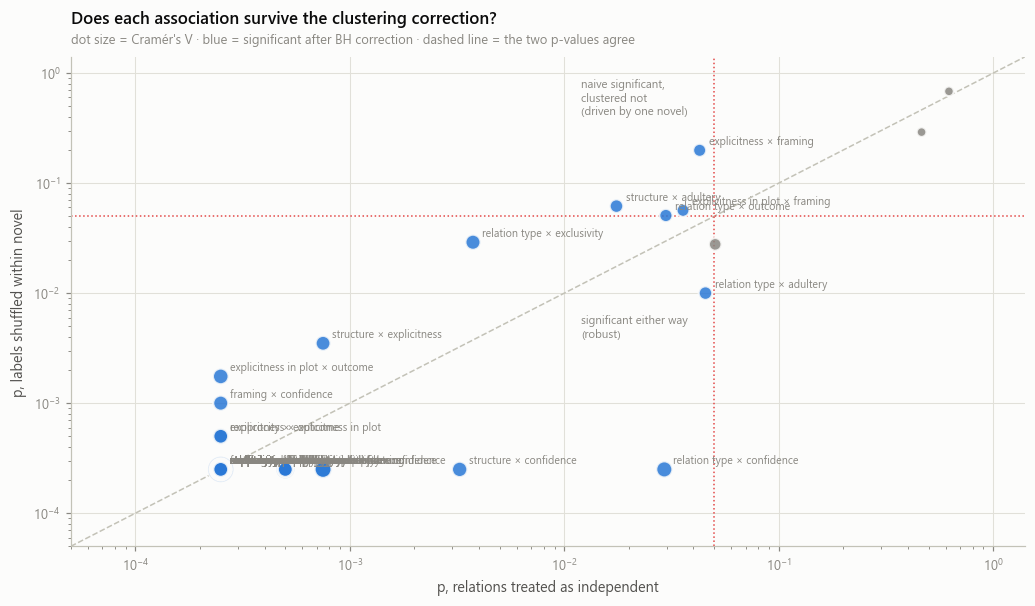


**63 of 66 pairs are significant at BH q < 0.05.**
Of those, **59 also survive** the within-novel permutation and
**4 do not** — `structure × adultery`, `relation_type × outcome`, `explicitness × framing`, `explicitness_in_plot × framing`.

Points sitting well above the diagonal are the warning cases: they look strong when the 85
relations are treated as independent, and dissolve once each novel's own label mix is held fixed.
With 10 of 18 novels by a single author, that distinction is not a technicality.


In [66]:
sig = assoc[(assoc["q BH"] < ALPHA)].copy()
robust = sig[sig["p (within-novel)"] < ALPHA]
fragile = sig[~(sig["p (within-novel)"] < ALPHA)]

fig, ax = plt.subplots(figsize=(9.5, 5.6))
d = assoc.dropna(subset=["p", "p (within-novel)"]).copy()
size = 40 + 240 * (d["V"] / max(d["V"].max(), 1e-9))
col = [SERIES[0] if q < ALPHA else MUTED for q in d["q BH"]]
ax.scatter(d["p"], d["p (within-novel)"], s=size, c=col, alpha=.85,
           edgecolor=SURFACE, linewidth=1.4, zorder=3)
lim = [5e-5, 1.4]
ax.plot(lim, lim, color=AXIS, linewidth=1, linestyle="--", zorder=2)
ax.axhline(ALPHA, color=SERIES[7], linewidth=1, linestyle=":", zorder=2)
ax.axvline(ALPHA, color=SERIES[7], linewidth=1, linestyle=":", zorder=2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(*lim); ax.set_ylim(*lim)
for _, r in d.iterrows():
    if r["p"] < ALPHA or r["V"] > 0.42:
        ax.annotate(f"{pretty_field(r['field A'])} × {pretty_field(r['field B'])}",
                    (r["p"], r["p (within-novel)"]), fontsize=7, color=MUTED,
                    xytext=(6, 4), textcoords="offset points")
ax.text(0.012, 0.9, "naive significant,\nclustered not\n(driven by one novel)",
        fontsize=7.5, color=MUTED, va="top")
ax.text(0.012, 0.004, "significant either way\n(robust)", fontsize=7.5, color=MUTED)
finish(ax, "Does each association survive the clustering correction?",
       "dot size = Cramér's V · blue = significant after BH correction · "
       "dashed line = the two p-values agree",
       xlabel="p, relations treated as independent",
       ylabel="p, labels shuffled within novel")
plt.tight_layout(); plt.show()

note(f"""
**{len(sig)} of {len(assoc)} pairs are significant at BH q < {ALPHA}.**
Of those, **{len(robust)} also survive** the within-novel permutation and
**{len(fragile)} do not**{'' if not len(fragile) else ' — ' + ', '.join(f"`{r['field A']} × {r['field B']}`" for _, r in fragile.iterrows())}.

Points sitting well above the diagonal are the warning cases: they look strong when the 85
relations are treated as independent, and dissolve once each novel's own label mix is held fixed.
With 10 of 18 novels by a single author, that distinction is not a technicality.
""")

## F. The literary questions

The matrix says *which* dimensions are linked. This section asks *how*, for the eight pairings
that carry an interpretive claim. Each one gets the same treatment: a contingency table with row
percentages, a figure, a naive test, a within-novel test, and an effect size.

In [67]:
FINDINGS = []      # collected here, summarised in §L

def relate(a, b, title, question, collapse=8, figsize=(11.5, None), swap=False,
           note_extra=""):
    """
    Full report for one pair of fields: counts, row %, 100 % stacked bars,
    naive test, within-novel permutation test, effect size.
    """
    d = relations[[a, b, "novel_id"]].dropna().reset_index(drop=True)
    ct = pd.crosstab(d[a], d[b])
    ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
    row_pct = ct.div(ct.sum(1), axis=0)

    t = assoc_test(d[a], d[b])
    p_cl, n_used, n_inf = cluster_permutation_p(relations, a, b)

    note(f"### {title}\n\n{question}")

    # counts with row percentages folded in
    disp = ct.copy().astype(object)
    for i in ct.index:
        for j in ct.columns:
            disp.loc[i, j] = f"{ct.loc[i, j]}  ({row_pct.loc[i, j]:.0%})" if ct.loc[i, j] else "·"
    disp.index = [f"{pretty(i)} (n={int(ct.loc[i].sum())})" for i in ct.index]
    disp.columns = [pretty(c) for c in ct.columns]
    disp.index.name = pretty_field(a)
    display(disp)

    # figure
    plot_b = collapse_rare(d[b], b, max_levels=collapse)
    ct_plot = pd.crosstab(d[a], plot_b)
    ct_plot = ct_plot.loc[ct_plot.sum(1) > 0, ct_plot.sum(0) > 0]
    h = figsize[1] or (0.52 * len(ct_plot) + 2.2)
    fig, ax = plt.subplots(figsize=(figsize[0], h))
    stacked_pct(ct_plot, ax=ax, order_rows=[l for l in LEVELS[a] if l in ct_plot.index])
    finish(ax, f"{pretty_field(b)} by {pretty_field(a)}",
           f"{t['test']} · p = {t['p']:.4f} · within-novel p = "
           f"{'n/a' if not np.isfinite(p_cl) else format(p_cl, '.4f')} · "
           f"V = {t['v']:.2f} ({v_magnitude(t['v'])}) · n = {t['n']}"
           + ("  ·  (!) underpowered, min expected cell "
              f"{t['min_expected']:.2f}" if t["underpowered"] else ""))
    plt.tight_layout(); plt.show()

    naive_sig = np.isfinite(t["p"]) and t["p"] < ALPHA
    clust_sig = np.isfinite(p_cl) and p_cl < ALPHA
    if naive_sig and clust_sig:
        verdict = "holds within novels as well as across them"
    elif naive_sig:
        verdict = ("significant overall but not once each novel's label mix is held fixed — "
                   "likely driven by individual books")
    elif clust_sig:
        verdict = ("significant under the within-novel test only. The conditional test is the "
                   "more appropriate one for this design and is often the more sensitive, so "
                   "read this as suggestive rather than absent")
    else:
        verdict = "no association detectable at this sample size"
    note(f"**Result.** V = {t['v']:.2f} ({v_magnitude(t['v'])}), p = {t['p']:.4f}, "
         f"within-novel p = {'n/a' if not np.isfinite(p_cl) else format(p_cl, '.4f')} — "
         f"{verdict}." + (f"\n\n{note_extra}" if note_extra else ""))

    FINDINGS.append({"question": title, "A": a, "B": b, "n": t["n"], "V": t["v"],
                     "p": t["p"], "p within-novel": p_cl, "test": t["test"],
                     "underpowered": t["underpowered"]})
    return ct

### F.1 — Narration against diegesis

The codebook insists these are two independent axes: `explicitness` is how openly the
**narration** shows the relation to the reader, `explicitness_in_plot` is how openly it is known
**among the characters**. Its own worked example is a relation that is `explicit` *and* `hidden`
at once. If the annotator has understood the distinction, the two should be close to independent;
a strong association would mean it is collapsing them into a single "how open is this" judgement.

,explicit,explicit except,hidden except,hidden,unclear
explicitness,,,,,
explicit (n=429),228 (53%),28 (7%),106 (25%),61 (14%),6 (1%)
coded (n=112),48 (43%),1 (1%),30 (27%),24 (21%),9 (8%)
rumor (n=35),24 (69%),5 (14%),2 (6%),·,4 (11%)
weak inference (n=16),11 (69%),·,·,2 (12%),3 (19%)


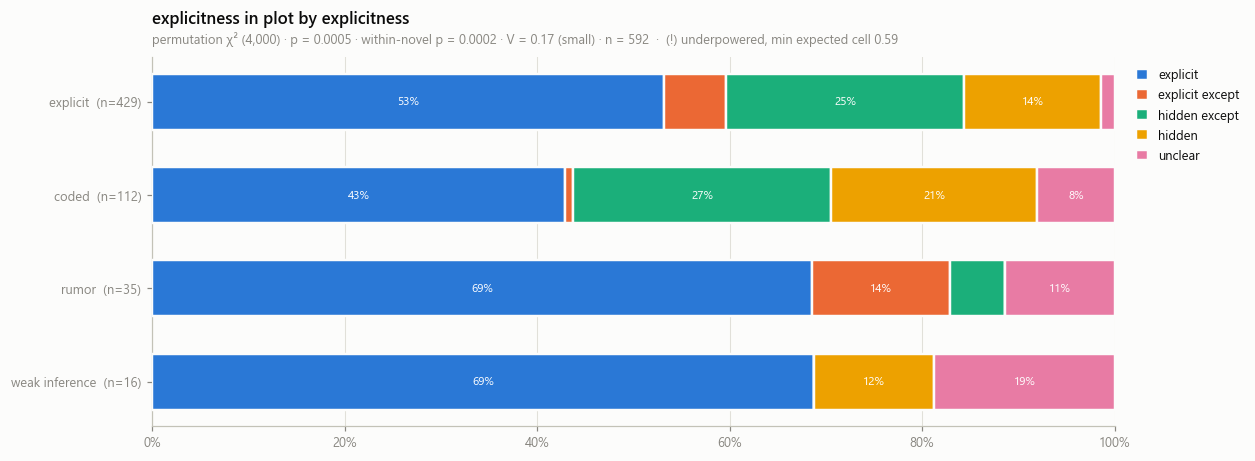

**Result.** V = 0.17 (small), p = 0.0005, within-novel p = 0.0002 — holds within novels as well as across them.

_Reading the table:_ the cell that matters is `explicit` narration combined with
`hidden` or `hidden_except` plot status. A healthy count there is direct evidence the annotator
is holding the two axes apart.

In [68]:
_ = relate(
    "explicitness", "explicitness_in_plot",
    "F.1 — Narration against diegesis",
    """The codebook insists these are two independent axes: `explicitness` is how openly the
**narration** shows the relation to the reader, `explicitness_in_plot` is how openly it is known
**among the characters**. Its own worked example is a relation that is `explicit` *and* `hidden`
at once. If the annotator has understood the distinction, the two should be close to independent;
a strong association would mean it is collapsing them into a single "how open is this" judgement.""",
    note_extra="""_Reading the table:_ the cell that matters is `explicit` narration combined with
`hidden` or `hidden_except` plot status. A healthy count there is direct evidence the annotator
is holding the two axes apart.""")

### F.2 — Rules against transgression

`exclusivity` records the rules a relation operates under; `adultery` records whether those
rules are broken. They are related by construction, so a strong association is expected — the
interesting part is not the *p*-value but whether the pairings the codebook **requires** are
actually respected. The audit below checks that.

,loyal,adultery one,adultery both,external adultery,none,unclear
exclusivity,,,,,,
exclusive (n=155),92 (59%),52 (34%),4 (3%),1 (1%),3 (2%),3 (2%)
emotionally exclusive (n=9),1 (11%),4 (44%),·,·,2 (22%),2 (22%)
primary relationship (n=23),5 (22%),6 (26%),·,·,11 (48%),1 (4%)
secondary relationship (n=10),·,1 (10%),·,2 (20%),6 (60%),1 (10%)
polyamory (n=11),·,·,·,·,10 (91%),1 (9%)
adultery (n=92),·,·,·,92 (100%),·,·
uncommitted (n=182),·,1 (1%),·,3 (2%),175 (96%),3 (2%)
unclear (n=110),·,3 (3%),·,1 (1%),79 (72%),27 (25%)


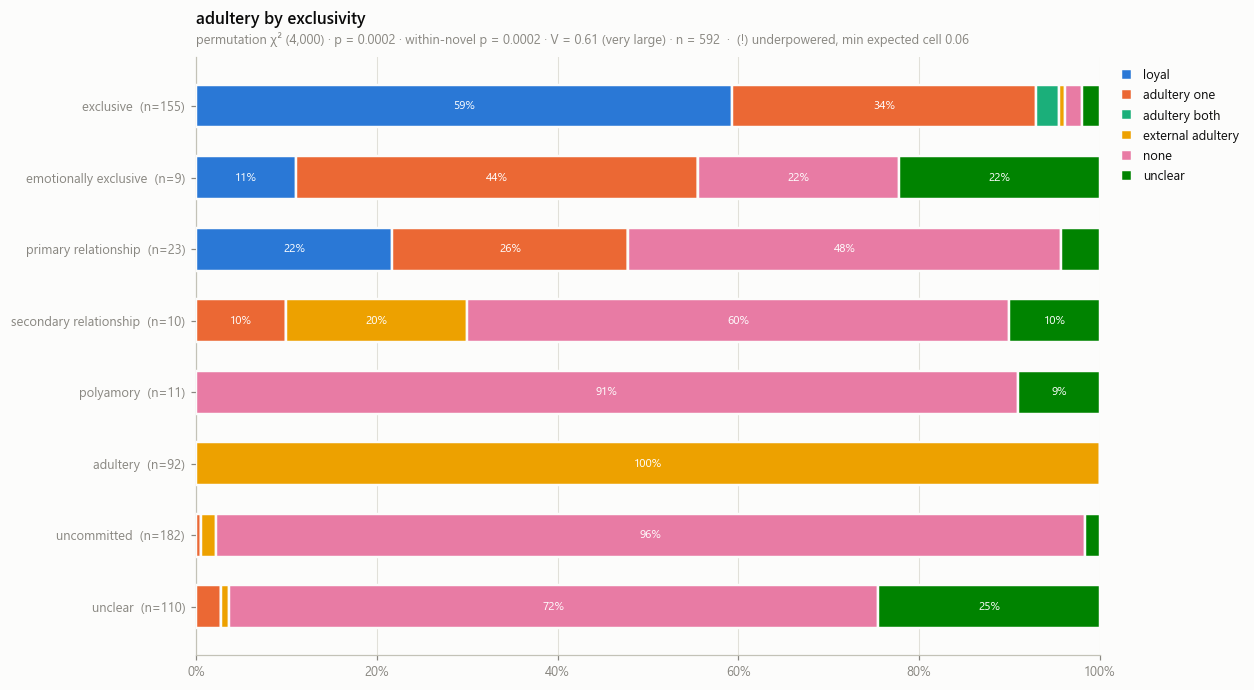

**Result.** V = 0.61 (very large), p = 0.0002, within-novel p = 0.0002 — holds within novels as well as across them.

In [69]:
ct_ex = relate(
    "exclusivity", "adultery",
    "F.2 — Rules against transgression",
    """`exclusivity` records the rules a relation operates under; `adultery` records whether those
rules are broken. They are related by construction, so a strong association is expected — the
interesting part is not the *p*-value but whether the pairings the codebook **requires** are
actually respected. The audit below checks that.""")

In [71]:
# --- codebook rule-compliance audit
rules = []
r = relations
rules.append({
    "rule": "a relation that is itself adulterous must be exclusivity=adultery AND adultery=external_adultery",
    "scope": "exclusivity == adultery",
    "violations": r[(r["exclusivity"] == "adultery") & (r["adultery"] != "external_adultery")],
})
rules.append({
    "rule": "adultery=external_adultery requires exclusivity=adultery",
    "scope": "adultery == external_adultery",
    "violations": r[(r["adultery"] == "external_adultery") & (r["exclusivity"] != "adultery")],
})
rules.append({
    "rule": "a married relation should not be coded exclusivity=uncommitted",
    "scope": "status == married",
    "violations": r[(r["status"] == "married") & (r["exclusivity"] == "uncommitted")],
})
rules.append({
    "rule": "a one-sided relation should normally take adultery=none (the question does not arise)",
    "scope": "reciprocity == one_sided",
    "violations": r[(r["reciprocity"] == "one_sided") &
                    (~r["adultery"].isin(["none", "unclear", "external_adultery"]))],
})

in_scope = [
    int((r["exclusivity"] == "adultery").sum()),
    int((r["adultery"] == "external_adultery").sum()),
    int((r["status"] == "married").sum()),
    int((r["reciprocity"] == "one_sided").sum()),
]
audit = pd.DataFrame([{"codebook rule": x["rule"],
                       "relations in scope": n,
                       "violations": len(x["violations"])}
                      for x, n in zip(rules, in_scope)])
audit["violation rate"] = audit["violations"] / audit["relations in scope"].replace(0, np.nan)

note("""
#### F.2b — Does the annotation obey the codebook's own pairing rules?

The codebook states four hard constraints between fields. Unlike everything else in this
notebook, these are not hypotheses to test — they are rules the output should satisfy, and any
breach is a correctable annotation error rather than a finding about literature.
""")
display(audit.style.format({"violation rate": "{:.0%}"}, na_rep="—").hide(axis="index"))

viol = pd.concat([x["violations"].assign(broken_rule=x["rule"][:60]) for x in rules
                  if len(x["violations"])], ignore_index=True) if any(
    len(x["violations"]) for x in rules) else pd.DataFrame()
if len(viol):
    note(f"**{len(viol)} relations breach at least one rule** — listed here for re-annotation:")
    display(viol[["novel_id", "relation_id", "status", "exclusivity", "adultery",
                  "reciprocity", "broken_rule"]].style.hide(axis="index"))
else:
    note("**No violations** — the annotation is internally consistent with the codebook's "
         "pairing rules.")


#### F.2b — Does the annotation obey the codebook's own pairing rules?

The codebook states four hard constraints between fields. Unlike everything else in this
notebook, these are not hypotheses to test — they are rules the output should satisfy, and any
breach is a correctable annotation error rather than a finding about literature.


codebook rule,relations in scope,violations,violation rate
a relation that is itself adulterous must be exclusivity=adultery AND adultery=external_adultery,92,0,0%
adultery=external_adultery requires exclusivity=adultery,99,7,7%
a married relation should not be coded exclusivity=uncommitted,116,1,1%
a one-sided relation should normally take adultery=none (the question does not arise),141,6,4%


**14 relations breach at least one rule** — listed here for re-annotation:

novel_id,relation_id,status,exclusivity,adultery,reciprocity,broken_rule
navery_voyages,R1,romantic_relationship,exclusive,external_adultery,asymmetrical,adultery=external_adultery requires exclusivity=adultery
tinayre_amourpleure,R4,seduction,uncommitted,external_adultery,asymmetrical,adultery=external_adultery requires exclusivity=adultery
tinayre_avant,R2,romantic_relationship,secondary_relationship,external_adultery,asymmetrical,adultery=external_adultery requires exclusivity=adultery
tinayre_figuresnuit,R4,physical_relationship,uncommitted,external_adultery,asymmetrical,adultery=external_adultery requires exclusivity=adultery
mendes_roivierge,R6,physical_relationship,uncommitted,external_adultery,reciprocal,adultery=external_adultery requires exclusivity=adultery
zola_potbouille,R14,physical_relationship,secondary_relationship,external_adultery,one_sided,adultery=external_adultery requires exclusivity=adultery
louys_contes,R6,physical_relationship,unclear,external_adultery,unclear,adultery=external_adultery requires exclusivity=adultery
tinayre_maisonpeche,R6,married,uncommitted,none,asymmetrical,a married relation should not be coded exclusivity=uncommitt
gautier_usurpateur,R3,engaged,secondary_relationship,adultery_one,one_sided,a one-sided relation should normally take adultery=none (the
lesueur_droit,R2,engaged,unclear,adultery_one,one_sided,a one-sided relation should normally take adultery=none (the


### F.3 — Poetic justice: does moral framing predict narrative punishment?

This is the central interpretive question the grid was built to ask. `framing` records how
the narration judges a relation; `outcome` records what the plot does to it. If nineteenth-century
narrative morality operates the way the critical tradition assumes, relations framed as
`moralized_pathologized` or `predatory_or_corrupting` should end badly far more often than those
framed as `positive`.

,stable or open,open contested,return to norm,separation erasure,social disgrace,illness madness decline,fatal ending,unclear
framing,,,,,,,,
positive (n=60),26 (43%),4 (7%),8 (13%),11 (18%),·,·,10 (17%),1 (2%)
neutral ambivalent (n=131),24 (18%),11 (8%),9 (7%),51 (39%),4 (3%),1 (1%),14 (11%),17 (13%)
eroticized exoticized (n=57),18 (32%),4 (7%),1 (2%),24 (42%),2 (4%),·,1 (2%),7 (12%)
decadent sublime (n=95),5 (5%),4 (4%),2 (2%),19 (20%),1 (1%),3 (3%),59 (62%),2 (2%)
redemptive spiritualized (n=15),2 (13%),·,1 (7%),7 (47%),·,·,5 (33%),·
moralized pathologized (n=70),9 (13%),2 (3%),6 (9%),21 (30%),11 (16%),3 (4%),15 (21%),3 (4%)
comic caricatural (n=110),30 (27%),7 (6%),8 (7%),41 (37%),10 (9%),·,4 (4%),10 (9%)
predatory or corrupting (n=54),3 (6%),1 (2%),2 (4%),20 (37%),6 (11%),2 (4%),14 (26%),6 (11%)


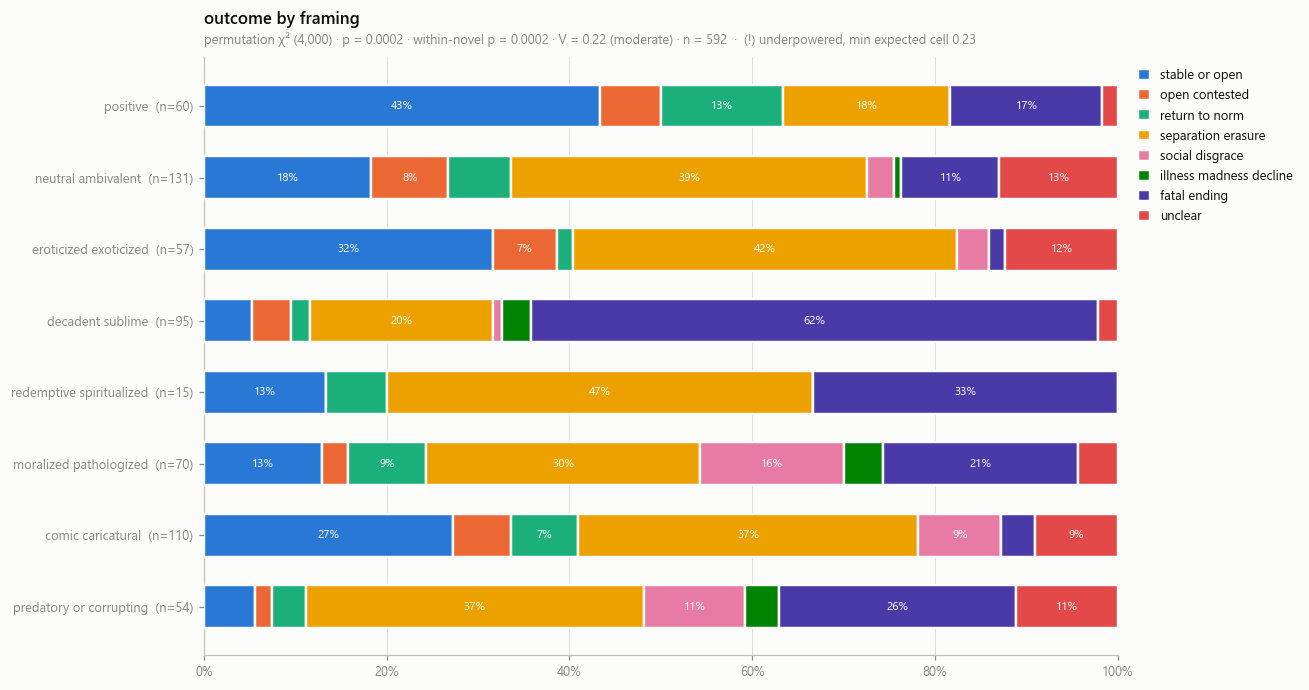

**Result.** V = 0.22 (moderate), p = 0.0002, within-novel p = 0.0002 — holds within novels as well as across them.

In [72]:
_ = relate(
    "framing", "outcome",
    "F.3 — Poetic justice: does moral framing predict narrative punishment?",
    """This is the central interpretive question the grid was built to ask. `framing` records how
the narration judges a relation; `outcome` records what the plot does to it. If nineteenth-century
narrative morality operates the way the critical tradition assumes, relations framed as
`moralized_pathologized` or `predatory_or_corrupting` should end badly far more often than those
framed as `positive`.""",
    collapse=8, figsize=(12, None))

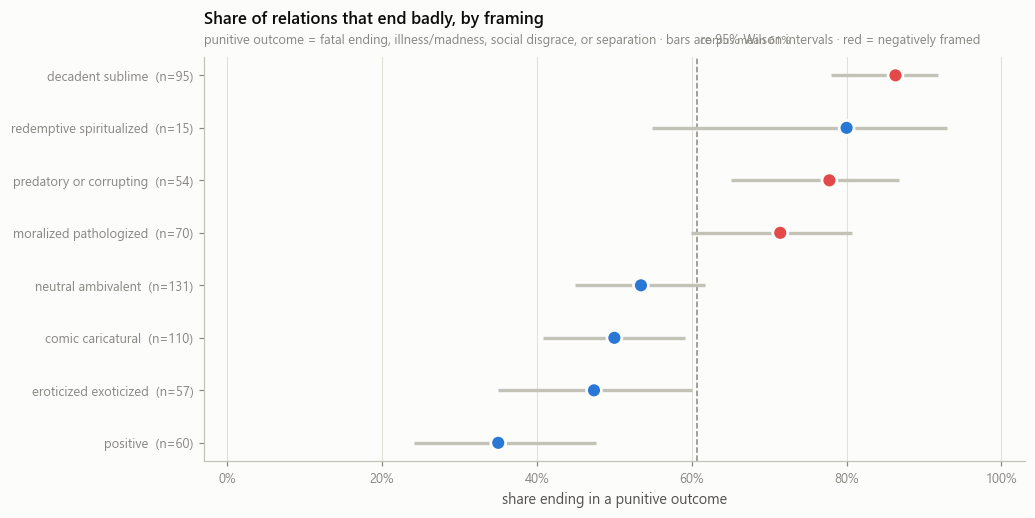


**Negatively framed relations end badly 79% of the time
(174/219); all others 50% (185/373).**

Odds ratio **3.90** (95% CI 2.65–5.72), Fisher p = 0.0000,
within-novel p = 0.0002.

The confidence interval excludes 1, so the association is real at this sample size: a relation the narration condemns is measurably more likely to be destroyed by the plot.


In [73]:
# --- poetic justice as a single binary contrast, with odds ratios
PUNITIVE = ["fatal_ending", "illness_madness_decline", "social_disgrace", "separation_erasure"]
NEGATIVE_FRAMING = ["moralized_pathologized", "predatory_or_corrupting", "decadent_sublime"]

d = relations.dropna(subset=["framing", "outcome"]).copy()
d["punished"] = d["outcome"].isin(PUNITIVE)
d["framed_negatively"] = d["framing"].isin(NEGATIVE_FRAMING)

tab = pd.crosstab(d["framed_negatively"], d["punished"]).reindex(
    index=[False, True], columns=[False, True]).fillna(0).astype(int)
a_, b_ = tab.loc[True, True], tab.loc[True, False]
c_, dd_ = tab.loc[False, True], tab.loc[False, False]
orv, or_lo, or_hi = odds_ratio_ci(a_, b_, c_, dd_)
p_fis = stats.fisher_exact(tab.values)[1]
p_cl_pj, _, _ = cluster_permutation_p(d.assign(fn=d["framed_negatively"].map(str),
                                               pu=d["punished"].map(str)), "fn", "pu")

# per-framing punishment rate with Wilson intervals
per_fr = (d.groupby("framing", observed=True)
          .agg(n=("punished", "size"), punished=("punished", "sum")))
per_fr = per_fr[per_fr["n"] > 0]
per_fr["rate"] = per_fr["punished"] / per_fr["n"]
per_fr[["lo", "hi"]] = [wilson_ci(k, n) for k, n in zip(per_fr["punished"], per_fr["n"])]
per_fr = per_fr.sort_values("rate")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(per_fr))
ax.hlines(y, per_fr["lo"], per_fr["hi"], color=AXIS, linewidth=2.2, zorder=2)
ax.scatter(per_fr["rate"], y, s=95,
           c=[SERIES[7] if f in NEGATIVE_FRAMING else SERIES[0] for f in per_fr.index],
           edgecolor=SURFACE, linewidth=1.8, zorder=3)
ax.axvline(d["punished"].mean(), color=MUTED, linestyle="--", linewidth=1, zorder=1)
ax.text(d["punished"].mean(), len(per_fr) - .4, f" corpus mean {d['punished'].mean():.0%}",
        fontsize=7.5, color=MUTED)
ax.set_yticks(y, [f"{pretty(i)}  (n={int(n)})" for i, n in zip(per_fr.index, per_fr["n"])])
ax.set_xlim(-0.03, 1.03)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
finish(ax, "Share of relations that end badly, by framing",
       "punitive outcome = fatal ending, illness/madness, social disgrace, or separation · "
       "bars are 95% Wilson intervals · red = negatively framed",
       xlabel="share ending in a punitive outcome")
plt.tight_layout(); plt.show()

note(f"""
**Negatively framed relations end badly {a_/(a_+b_):.0%} of the time
({a_}/{a_+b_}); all others {c_/(c_+dd_):.0%} ({c_}/{c_+dd_}).**

Odds ratio **{orv:.2f}** (95% CI {or_lo:.2f}–{or_hi:.2f}), Fisher p = {p_fis:.4f},
within-novel p = {'n/a' if not np.isfinite(p_cl_pj) else format(p_cl_pj, '.4f')}.

{'The confidence interval excludes 1, so the association is real at this sample size: a relation the narration condemns is measurably more likely to be destroyed by the plot.' if or_lo > 1 else 'The confidence interval includes 1. The point estimate points in the expected direction, but **85 relations are not enough to establish it** — this is the single clearest case in the notebook of a question that needs the full corpus.' if orv > 1 else 'The point estimate runs *against* the expected direction, which is worth inspecting by eye before drawing any conclusion.'}
""")
FINDINGS.append({"question": "F.3b poetic justice (binary OR)", "A": "framed_negatively",
                 "B": "punished", "n": len(d), "V": np.nan, "p": p_fis,
                 "p within-novel": p_cl_pj, "test": f"Fisher, OR={orv:.2f}",
                 "underpowered": bool(tab.values.min() < 5)})

### F.4 — Is transgression punished?

A narrower version of the same question, moving from how the narration *judges* a relation
to whether the relation actually *breaks a rule*. `adultery` is a fact about the relation;
`outcome` is what the plot does with it.

,stable or open,open contested,return to norm,separation erasure,social disgrace,illness madness decline,fatal ending,unclear
adultery,,,,,,,,
loyal (n=98),33 (34%),7 (7%),16 (16%),9 (9%),1 (1%),2 (2%),30 (31%),·
adultery one (n=67),18 (27%),4 (6%),10 (15%),15 (22%),3 (4%),1 (1%),15 (22%),1 (1%)
adultery both (n=4),·,1 (25%),·,1 (25%),1 (25%),·,1 (25%),·
external adultery (n=99),18 (18%),5 (5%),6 (6%),39 (39%),10 (10%),1 (1%),15 (15%),5 (5%)
none (n=286),40 (14%),14 (5%),5 (2%),123 (43%),15 (5%),5 (2%),55 (19%),29 (10%)
unclear (n=38),8 (21%),2 (5%),·,7 (18%),4 (11%),·,6 (16%),11 (29%)


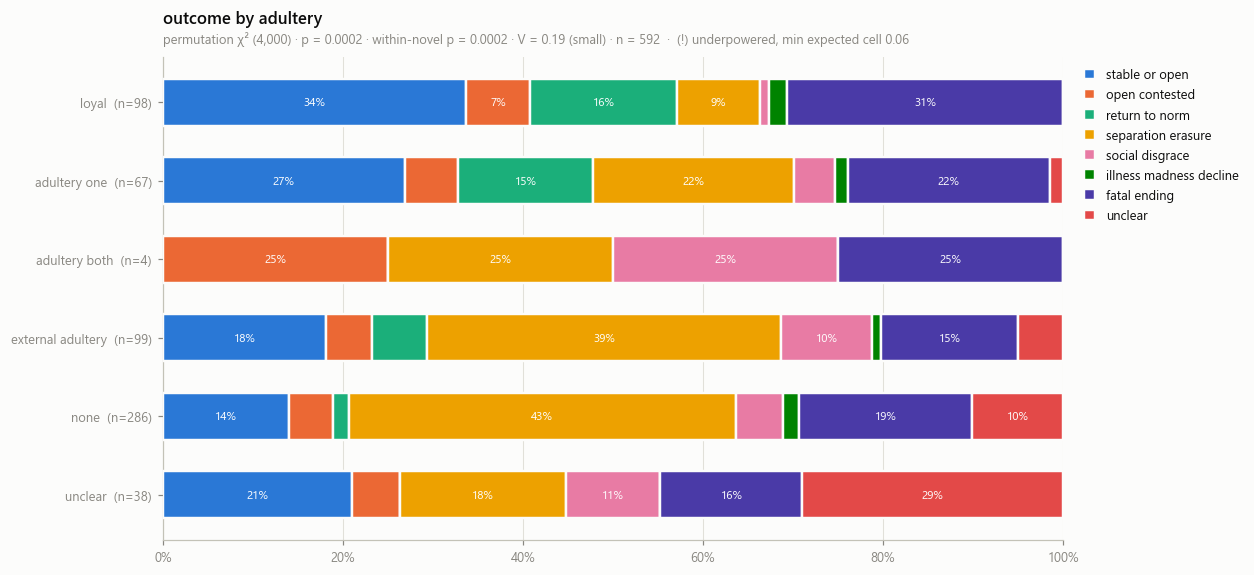

**Result.** V = 0.19 (small), p = 0.0002, within-novel p = 0.0002 — holds within novels as well as across them.

In [74]:
_ = relate(
    "adultery", "outcome",
    "F.4 — Is transgression punished?",
    """A narrower version of the same question, moving from how the narration *judges* a relation
to whether the relation actually *breaks a rule*. `adultery` is a fact about the relation;
`outcome` is what the plot does with it.""",
    collapse=8)

### F.5 — Which bonds are mutual?

`status` names the kind of bond, `reciprocity` its balance of commitment. The expectation
is structural rather than moral: `married` and `romantic_relationship` should be predominantly
`reciprocal`, while `seduction` and `ambiguous_friendship` — bonds defined by one party pursuing
another — should be predominantly `one_sided`. If that pattern fails to appear, either the corpus
is unusual or the two fields are not being applied as defined.

,one sided,reciprocal,asymmetrical,unclear
status,,,,
married (n=116),1 (1%),39 (34%),61 (53%),15 (13%)
engaged (n=30),4 (13%),16 (53%),7 (23%),3 (10%)
romantic relationship (n=113),24 (21%),46 (41%),30 (27%),13 (12%)
physical relationship (n=141),17 (12%),24 (17%),45 (32%),55 (39%)
ambiguous friendship (n=77),22 (29%),22 (29%),21 (27%),12 (16%)
seduction (n=79),55 (70%),7 (9%),14 (18%),3 (4%)
unclear (n=36),18 (50%),2 (6%),3 (8%),13 (36%)


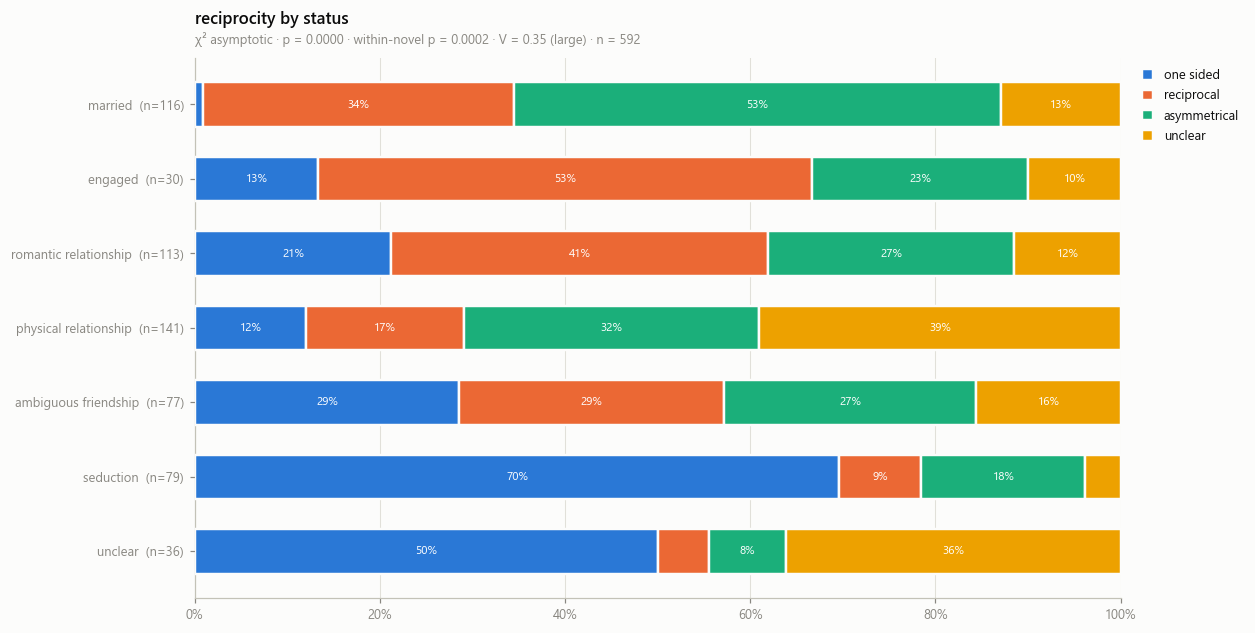

**Result.** V = 0.35 (large), p = 0.0000, within-novel p = 0.0002 — holds within novels as well as across them.

In [75]:
_ = relate(
    "status", "reciprocity",
    "F.5 — Which bonds are mutual?",
    """`status` names the kind of bond, `reciprocity` its balance of commitment. The expectation
is structural rather than moral: `married` and `romantic_relationship` should be predominantly
`reciprocal`, while `seduction` and `ambiguous_friendship` — bonds defined by one party pursuing
another — should be predominantly `one_sided`. If that pattern fails to appear, either the corpus
is unusual or the two fields are not being applied as defined.""")

### F.6 — Do central relations get treated differently?

`centrality` is a narrative-economy variable: is this the main relation, a subplot, a brief
episode, or background milieu? The question is whether the corpus reserves sympathetic framing
for its central couples and pushes transgressive or predatory bonds into the margins — a
structural way of having it both ways that nineteenth-century fiction is often accused of.

,positive,neutral ambivalent,eroticized exoticized,decadent sublime,redemptive spiritualized,moralized pathologized,comic caricatural,predatory or corrupting
centrality,,,,,,,,
main (n=135),18 (13%),21 (16%),6 (4%),41 (30%),5 (4%),14 (10%),16 (12%),14 (10%)
secondary (n=249),34 (14%),57 (23%),15 (6%),35 (14%),9 (4%),33 (13%),39 (16%),27 (11%)
episode (n=165),6 (4%),47 (28%),22 (13%),17 (10%),1 (1%),17 (10%),46 (28%),9 (5%)
milieu (n=43),2 (5%),6 (14%),14 (33%),2 (5%),·,6 (14%),9 (21%),4 (9%)


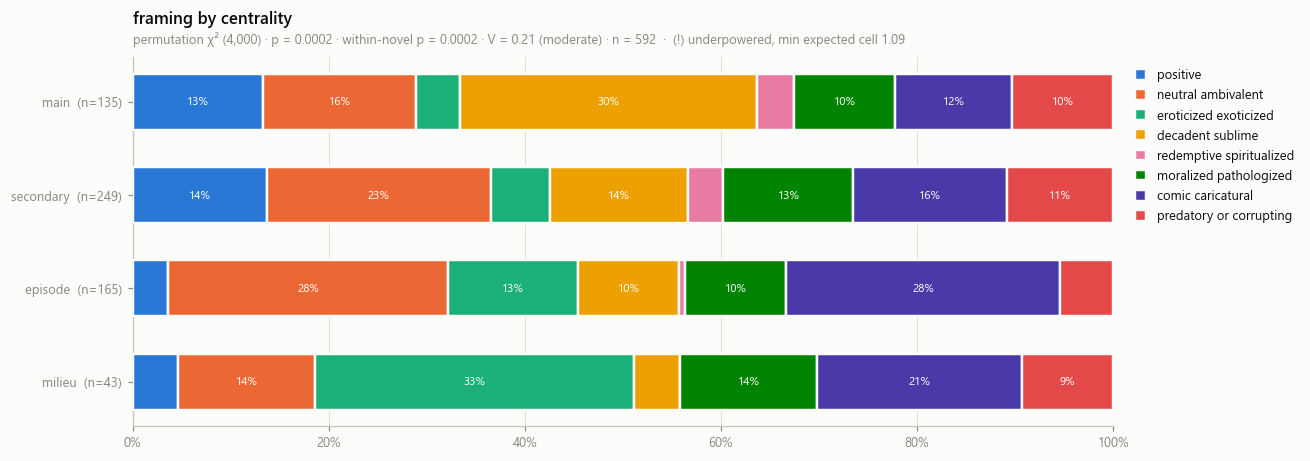

**Result.** V = 0.21 (moderate), p = 0.0002, within-novel p = 0.0002 — holds within novels as well as across them.

In [76]:
_ = relate(
    "centrality", "framing",
    "F.6 — Do central relations get treated differently?",
    """`centrality` is a narrative-economy variable: is this the main relation, a subplot, a brief
episode, or background milieu? The question is whether the corpus reserves sympathetic framing
for its central couples and pushes transgressive or predatory bonds into the margins — a
structural way of having it both ways that nineteenth-century fiction is often accused of.""",
    collapse=8, figsize=(12, None))

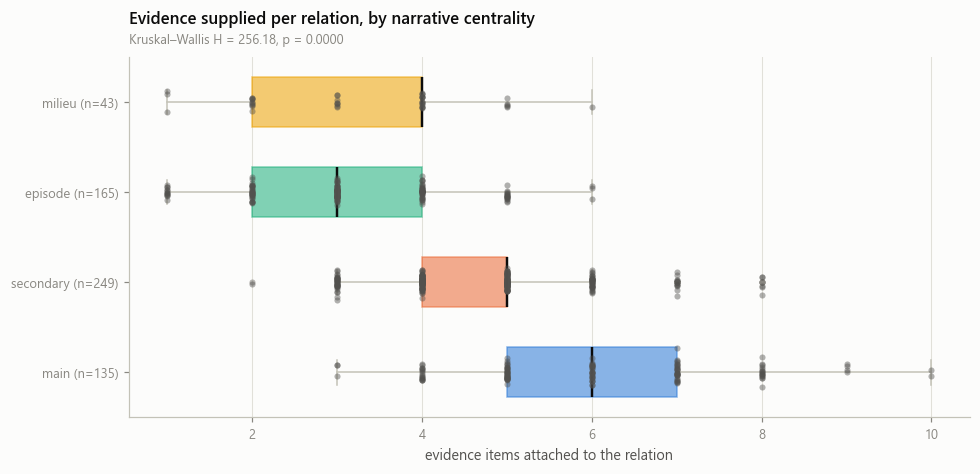


#### F.6b — Evidence effort against centrality

Kruskal–Wallis **H = 256.18, p = 0.0000**.
Central relations receive measurably more evidence than marginal ones.
This is a property of the *annotator*, not the novels: it says whether the model invests more
justification where the stakes are higher, which matters when the evidence is what makes the
corpus auditable.


pair,n1,n2,U,rank-biserial r,p,p Holm
main vs secondary,135,249,25470,+0.52,0.0000,0.000
main vs episode,135,165,20856,+0.87,0.0000,0.000
main vs milieu,135,43,5353,+0.84,0.0000,0.000
secondary vs episode,249,165,33448,+0.63,0.0000,0.000
secondary vs milieu,249,43,8314,+0.55,0.0000,0.000
episode vs milieu,165,43,3265,-0.08,0.4071,0.407


In [77]:
# --- does the annotator work harder on central relations?
groups = [g["n_evidence"].values for _, g in relations.groupby("centrality", observed=True)
          if len(g)]
labels = [k for k, g in relations.groupby("centrality", observed=True) if len(g)]
H, p_kw = stats.kruskal(*groups) if len(groups) > 1 else (np.nan, np.nan)

# pairwise Mann–Whitney with Holm
pw = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        u, p = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
        # rank-biserial correlation as the effect size
        n1, n2 = len(groups[i]), len(groups[j])
        pw.append({"pair": f"{pretty(labels[i])} vs {pretty(labels[j])}",
                   "n1": n1, "n2": n2, "U": u,
                   "rank-biserial r": 2 * u / (n1 * n2) - 1, "p": p})
pw = pd.DataFrame(pw)
if len(pw):
    pw["p Holm"] = holm(pw["p"])

fig, ax = plt.subplots(figsize=(9, 4.4))
order = [l for l in LEVELS["centrality"] if l in labels]
data = [relations.loc[relations["centrality"] == l, "n_evidence"].values for l in order]
parts = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,
                   medianprops=dict(color=INK, linewidth=1.6),
                   whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS),
                   flierprops=dict(marker="o", markersize=4, markerfacecolor=MUTED,
                                   markeredgecolor="none", alpha=.6))
for patch, colour in zip(parts["boxes"], SERIES):
    patch.set_facecolor(colour); patch.set_alpha(.55); patch.set_edgecolor(colour)
for i, l in enumerate(order, start=1):
    v = relations.loc[relations["centrality"] == l, "n_evidence"]
    ax.scatter(v, np.full(len(v), i) + RNG.normal(0, .07, len(v)), s=16, color=INK_2,
               alpha=.45, zorder=4, linewidth=0)
ax.set_yticks(range(1, len(order) + 1), [f"{pretty(l)} (n={len(d_)})"
                                         for l, d_ in zip(order, data)])
ax.grid(axis="y", visible=False)
finish(ax, "Evidence supplied per relation, by narrative centrality",
       f"Kruskal–Wallis H = {H:.2f}, p = {p_kw:.4f}",
       xlabel="evidence items attached to the relation")
plt.tight_layout(); plt.show()

note(f"""
#### F.6b — Evidence effort against centrality

Kruskal–Wallis **H = {H:.2f}, p = {p_kw:.4f}**.
{'Central relations receive measurably more evidence than marginal ones.' if p_kw < .05 else 'Evidence volume does not differ significantly across centrality levels at this sample size.'}
This is a property of the *annotator*, not the novels: it says whether the model invests more
justification where the stakes are higher, which matters when the evidence is what makes the
corpus auditable.
""")
if len(pw):
    display(pw.style.format({"U": "{:.0f}", "rank-biserial r": "{:+.2f}", "p": "{:.4f}",
                             "p Holm": "{:.3f}"}).hide(axis="index"))

### F.7 — Does mutuality protect a relationship?

If reciprocity buys narrative survival, `reciprocal` bonds should end `stable_or_open` far
more often than `one_sided` ones. If it does not — if mutual love is destroyed just as reliably —
that is itself a finding about the genre's economy of endings.

,stable or open,open contested,return to norm,separation erasure,social disgrace,illness madness decline,fatal ending,unclear
reciprocity,,,,,,,,
one sided (n=141),4 (3%),7 (5%),5 (4%),72 (51%),6 (4%),4 (3%),32 (23%),11 (8%)
reciprocal (n=156),49 (31%),13 (8%),12 (8%),38 (24%),4 (3%),1 (1%),37 (24%),2 (1%)
asymmetrical (n=181),43 (24%),8 (4%),15 (8%),61 (34%),10 (6%),3 (2%),41 (23%),·
unclear (n=114),21 (18%),5 (4%),5 (4%),23 (20%),14 (12%),1 (1%),12 (11%),33 (29%)


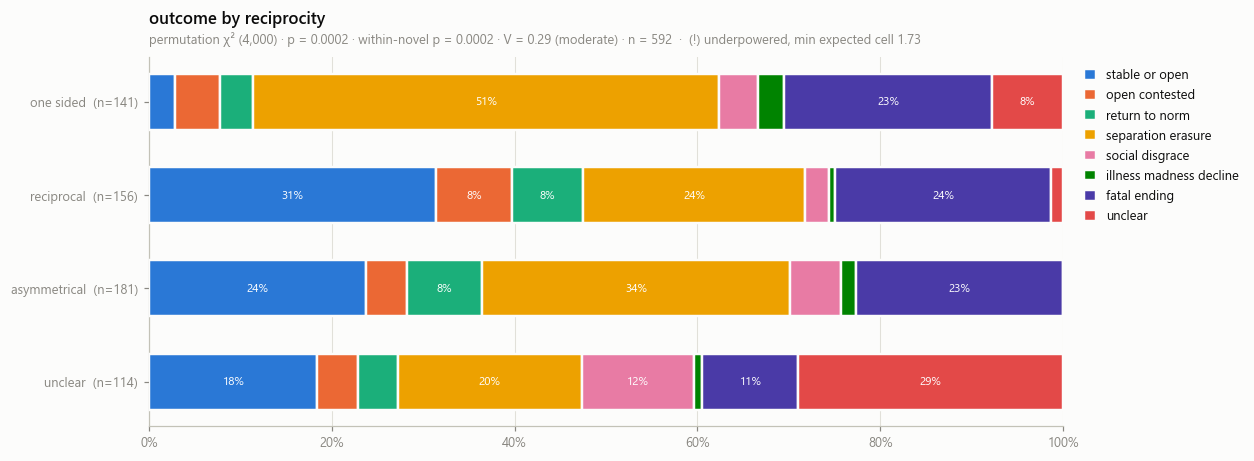

**Result.** V = 0.29 (moderate), p = 0.0002, within-novel p = 0.0002 — holds within novels as well as across them.

In [78]:
_ = relate(
    "reciprocity", "outcome",
    "F.7 — Does mutuality protect a relationship?",
    """If reciprocity buys narrative survival, `reciprocal` bonds should end `stable_or_open` far
more often than `one_sided` ones. If it does not — if mutual love is destroyed just as reliably —
that is itself a finding about the genre's economy of endings.""",
    collapse=8)

### F.8 — Where does the annotator hesitate?

The last cross-tab turns the instrument on itself. `confidence` is the model's own estimate
of how solid a coding is. If uncertainty concentrated in particular framings — the coded, the
ambiguous, the sublime — that would tell us which parts of the codebook are hardest to apply, and
where human review should be spent.

,positive,neutral ambivalent,eroticized exoticized,decadent sublime,redemptive spiritualized,moralized pathologized,comic caricatural,predatory or corrupting
confidence,,,,,,,,
high (n=278),35 (13%),46 (17%),18 (6%),59 (21%),10 (4%),35 (13%),45 (16%),30 (11%)
medium (n=233),16 (7%),59 (25%),30 (13%),23 (10%),5 (2%),31 (13%),52 (22%),17 (7%)
low (n=79),7 (9%),26 (33%),9 (11%),13 (16%),·,4 (5%),13 (16%),7 (9%)
exclude (n=2),2 (100%),·,·,·,·,·,·,·


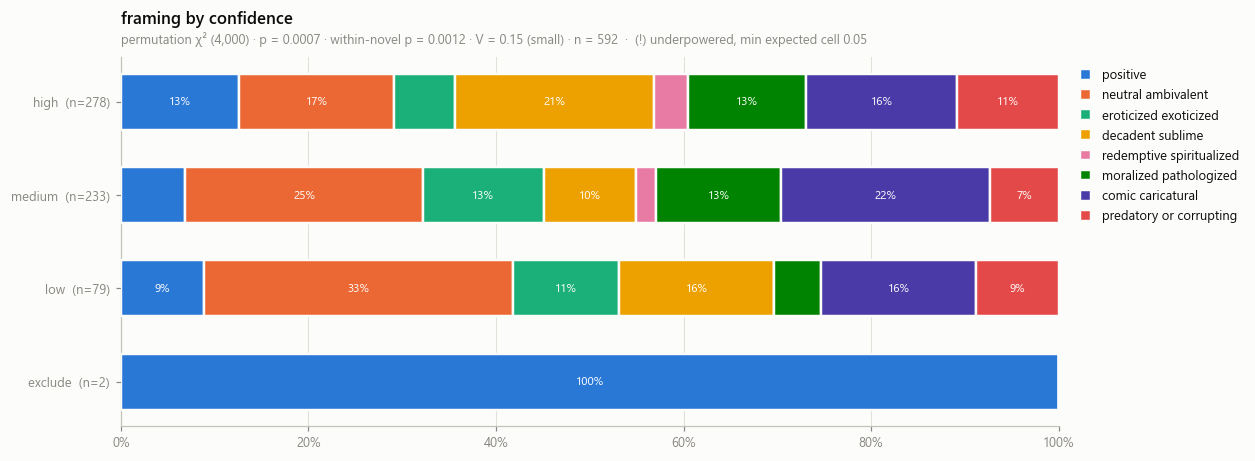

**Result.** V = 0.15 (small), p = 0.0007, within-novel p = 0.0012 — holds within novels as well as across them.

In [79]:
_ = relate(
    "confidence", "framing",
    "F.8 — Where does the annotator hesitate?",
    """The last cross-tab turns the instrument on itself. `confidence` is the model's own estimate
of how solid a coding is. If uncertainty concentrated in particular framings — the coded, the
ambiguous, the sublime — that would tell us which parts of the codebook are hardest to apply, and
where human review should be spent.""",
    collapse=8)

## G. Multivariate structure

Sections E and F look at two fields at a time. But a relation is a *profile* across eleven
dimensions at once, and the interesting objects in a corpus like this are recurring
configurations — the reciprocal marriage that survives, the one-sided seduction that ends in
death. Two complementary methods find them.

**Multiple Correspondence Analysis** places every label and every relation in the same low
-dimensional space, so labels that tend to co-occur end up near one another. It is the standard
tool for exactly this data type (an *n* × *p* table of purely nominal variables) and is what
French quantitative literary studies would reach for.

**Hierarchical clustering** on Hamming distance then cuts the same space into discrete
archetypes, so each relation can be assigned to a type and the types compared across novels.

MCA is implemented here directly from the SVD rather than pulled from a library, so the
eigenvalue correction is explicit and auditable.

In [80]:
def mca(df_cat, n_comp=4):
    """
    Multiple Correspondence Analysis via the SVD of the standardised indicator matrix.
    Returns row coordinates, column (label) coordinates, raw eigenvalues, and the
    Benzécri-corrected share of inertia — the raw percentages of an indicator MCA are
    famously pessimistic, so both are reported.
    """
    Z = pd.get_dummies(df_cat.astype(str), prefix_sep=" = ").astype(float)
    Z = Z.loc[:, Z.sum(0) > 0]
    n, Q, J = len(Z), df_cat.shape[1], Z.shape[1]
    P = Z.values / Z.values.sum()
    r, c = P.sum(1), P.sum(0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, s, Vt = np.linalg.svd(S, full_matrices=False)
    k = min(n_comp, len(s))
    F = (U[:, :k] * s[:k]) / np.sqrt(r)[:, None]          # relation coordinates
    G = (Vt[:k].T * s[:k]) / np.sqrt(c)[:, None]          # label coordinates
    eig = s ** 2
    keep = eig > 1 / Q
    adj = np.where(keep, (Q / (Q - 1)) ** 2 * (eig - 1 / Q) ** 2, 0.0)
    expl = adj / adj.sum() if adj.sum() else np.zeros_like(adj)
    freq = pd.Series(Z.sum(0).values, index=Z.columns)     # how often each label occurs
    return (pd.DataFrame(F, index=df_cat.index, columns=[f"dim{i+1}" for i in range(k)]),
            pd.DataFrame(G, index=Z.columns, columns=[f"dim{i+1}" for i in range(k)]),
            eig, expl, freq)

MCA_FIELDS = [f for f in ANALYSABLE if f != "confidence"]
mca_input = relations[MCA_FIELDS].astype(str)
F_rel, G_lab, eig, expl, lab_freq = mca(mca_input, n_comp=4)

print(f"MCA on {len(mca_input)} relations × {len(MCA_FIELDS)} fields "
      f"({G_lab.shape[0]} label categories)")
print("Benzécri-corrected inertia:  " +
      "   ".join(f"dim{i+1} {expl[i]:.1%}" for i in range(4)))
print("raw eigenvalues:             " +
      "   ".join(f"dim{i+1} {eig[i]:.3f}" for i in range(4)))

MCA on 592 relations × 11 fields (66 label categories)
Benzécri-corrected inertia:  dim1 45.8%   dim2 18.6%   dim3 13.9%   dim4 7.2%
raw eigenvalues:             dim1 0.374   dim2 0.271   dim3 0.247   dim4 0.204


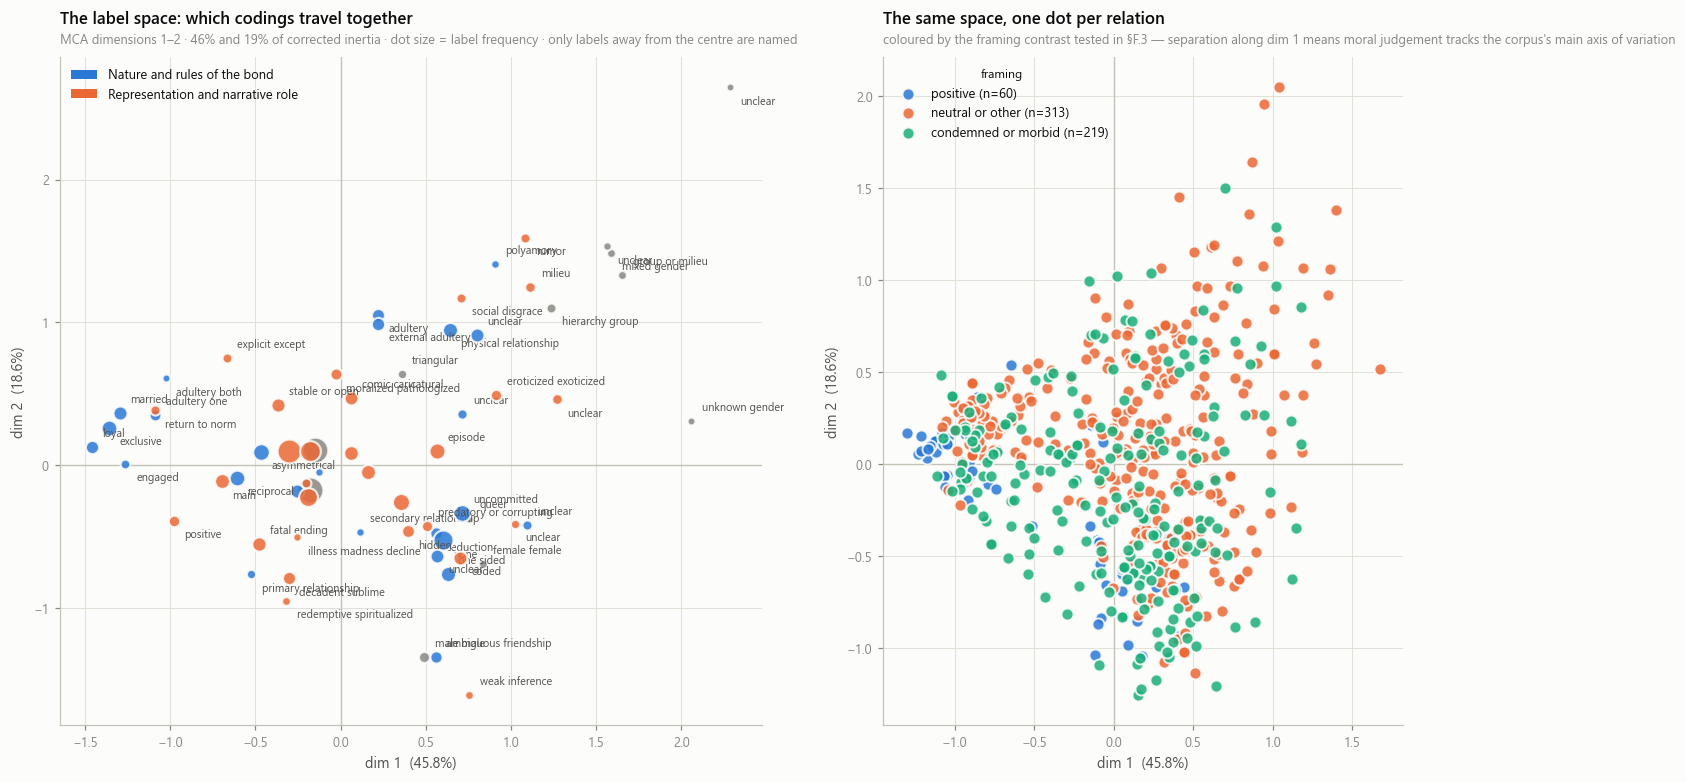

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 7.2), gridspec_kw={"width_ratios": [1.35, 1]})

# ---- label map
ax = axes[0]
fam_colour = {"Nature and rules of the bond": SERIES[0],
              "Representation and narrative role": SERIES[1]}
sizes = 25 + 260 * (lab_freq / lab_freq.max())
radius = np.hypot(G_lab["dim1"], G_lab["dim2"])
# Label the informative points only: frequent labels that sit away from the origin, plus the
# ten most extreme. Labels bunched at the centre are the near-average ones and their names
# would collide without adding anything.
to_label = set(radius.nlargest(10).index) | set(
    radius[(radius > 0.45) & (lab_freq >= 3)].index)
for j, lab in enumerate(G_lab.index):
    fld = lab.split(" = ")[0]
    x, y = G_lab.loc[lab, "dim1"], G_lab.loc[lab, "dim2"]
    ax.scatter(x, y, s=sizes[lab], color=fam_colour.get(FAMILY_OF.get(fld, ""), MUTED),
               alpha=.85, edgecolor=SURFACE, linewidth=1.4, zorder=3)
    if lab in to_label:
        dy = 7 if j % 2 == 0 else -11        # alternate above/below to reduce collisions
        ax.annotate(pretty(lab.split(" = ")[1]), (x, y), fontsize=7.2, color=INK_2,
                    xytext=(7, dy), textcoords="offset points")
ax.axhline(0, color=AXIS, linewidth=.9, zorder=1)
ax.axvline(0, color=AXIS, linewidth=.9, zorder=1)
ax.legend(handles=[Patch(facecolor=v, label=k) for k, v in fam_colour.items()],
          loc="upper left", bbox_to_anchor=(0, 1.0))
finish(ax, "The label space: which codings travel together",
       f"MCA dimensions 1–2 · {expl[0]:.0%} and {expl[1]:.0%} of corrected inertia · "
       "dot size = label frequency · only labels away from the centre are named",
       xlabel=f"dim 1  ({expl[0]:.1%})", ylabel=f"dim 2  ({expl[1]:.1%})")

# ---- relations, coloured by the framing contrast tested in §F.3
# Three groups, not nine: a scatter puts every colour pair on screen at once, and only a
# small palette stays separable under colour-vision deficiency.
NEG_FRAMING = ["moralized_pathologized", "predatory_or_corrupting", "decadent_sublime"]
fr3 = pd.Series(np.where(relations["framing"].isin(NEG_FRAMING), "condemned or morbid",
                np.where(relations["framing"] == "positive", "positive",
                         "neutral or other")))
ax = axes[1]
for i, lev in enumerate(["positive", "neutral or other", "condemned or morbid"]):
    m = (fr3 == lev).values
    ax.scatter(F_rel.loc[m, "dim1"], F_rel.loc[m, "dim2"], s=62, color=SERIES[i],
               label=f"{lev} (n={int(m.sum())})", alpha=.85, edgecolor=SURFACE,
               linewidth=1.3, zorder=3)
ax.axhline(0, color=AXIS, linewidth=.9, zorder=1)
ax.axvline(0, color=AXIS, linewidth=.9, zorder=1)
ax.legend(loc="best", title="framing", title_fontsize=8)
finish(ax, "The same space, one dot per relation",
       "coloured by the framing contrast tested in §F.3 — separation along dim 1 means "
       "moral judgement tracks the corpus's main axis of variation",
       xlabel=f"dim 1  ({expl[0]:.1%})", ylabel=f"dim 2  ({expl[1]:.1%})")
plt.tight_layout(); plt.show()

In [82]:
# Which labels define each of the first two dimensions?
contrib = pd.DataFrame({
    "dim1": G_lab["dim1"], "dim2": G_lab["dim2"],
    "frequency": lab_freq.values,
}, index=G_lab.index)
poles = pd.concat([
    contrib.nsmallest(6, "dim1").assign(pole="dim 1 — negative"),
    contrib.nlargest(6, "dim1").assign(pole="dim 1 — positive"),
    contrib.nsmallest(6, "dim2").assign(pole="dim 2 — negative"),
    contrib.nlargest(6, "dim2").assign(pole="dim 2 — positive"),
])[["pole", "dim1", "dim2", "frequency"]]

note("""
### G.1 What the two axes mean

An MCA dimension has no intrinsic meaning; it is read off the labels at its extremes. The table
below lists the six labels furthest along each pole. Reading them as opposed pairs is how the
axes get their interpretation — typically dimension 1 separates settled, mutual, socially
sanctioned bonds from asymmetric or transgressive ones, and dimension 2 separates central,
explicitly narrated relations from marginal or coded ones.
""")
display(poles.style.format({"dim1": "{:+.2f}", "dim2": "{:+.2f}", "frequency": "{:.0f}"}))


### G.1 What the two axes mean

An MCA dimension has no intrinsic meaning; it is read off the labels at its extremes. The table
below lists the six labels furthest along each pole. Reading them as opposed pairs is how the
axes get their interpretation — typically dimension 1 separates settled, mutual, socially
sanctioned bonds from asymmetric or transgressive ones, and dimension 2 separates central,
explicitly narrated relations from marginal or coded ones.


,pole,dim1,dim2,frequency
adultery = loyal,dim 1 — negative,-1.46,+0.13,98
exclusivity = exclusive,dim 1 — negative,-1.36,+0.26,155
status = married,dim 1 — negative,-1.29,+0.37,116
status = engaged,dim 1 — negative,-1.26,+0.01,30
outcome = return_to_norm,dim 1 — negative,-1.09,+0.38,37
adultery = adultery_one,dim 1 — negative,-1.09,+0.35,67
relation_type = unclear,dim 1 — positive,+2.28,+2.65,1
relation_type = unknown_gender,dim 1 — positive,+2.05,+0.31,3
structure = group_or_milieu,dim 1 — positive,+1.65,+1.34,17
relation_type = mixed_gender,dim 1 — positive,+1.59,+1.49,16


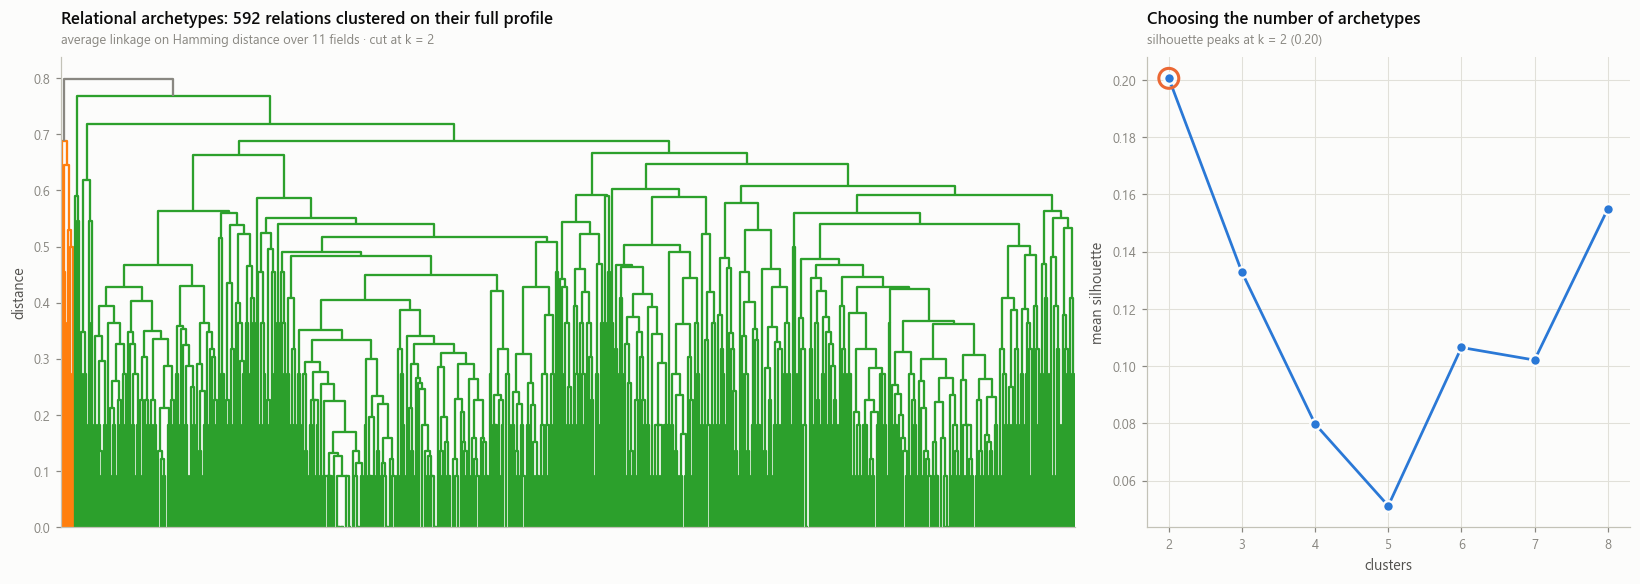

In [83]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import silhouette_score

CLUSTER_FIELDS = MCA_FIELDS
codes = np.column_stack([pd.factorize(relations[f].astype(str))[0] for f in CLUSTER_FIELDS])
D = pdist(codes, metric="hamming")        # share of the 10 fields on which two relations differ
Zl = linkage(D, method="average")

K_OVERRIDE = None      # set an integer to cut the tree yourself instead of by silhouette

sil = {}
for k in range(2, 9):
    lab = fcluster(Zl, k, criterion="maxclust")
    if len(set(lab)) > 1:
        sil[k] = silhouette_score(squareform(D), lab, metric="precomputed")
K = K_OVERRIDE or max(sil, key=sil.get)
relations["cluster"] = fcluster(Zl, K, criterion="maxclust")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [2.1, 1]})
ax = axes[0]
dendrogram(Zl, ax=ax, color_threshold=Zl[-(K - 1), 2],
           above_threshold_color=MUTED, no_labels=True)
ax.grid(False)
for spine in ("left",):
    ax.spines[spine].set_visible(True)
finish(ax, f"Relational archetypes: {len(relations)} relations clustered on their full profile",
       f"average linkage on Hamming distance over {len(CLUSTER_FIELDS)} fields · "
       f"cut at k = {K}", ylabel="distance")

ax = axes[1]
ax.plot(list(sil), list(sil.values()), marker="o", color=SERIES[0], linewidth=1.8,
        markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
ax.scatter([K], [sil[K]], s=170, facecolor="none", edgecolor=SERIES[1], linewidth=2, zorder=4)
ax.set_xticks(list(sil))
finish(ax, "Choosing the number of archetypes",
       f"silhouette peaks at k = {K} ({sil[K]:.2f})",
       xlabel="clusters", ylabel="mean silhouette")
plt.tight_layout(); plt.show()


### G.2 The 2 archetypes

Each cell gives the **modal label** for that field within the archetype, and the share of the
archetype's relations carrying it. A cluster whose modal shares are all near 100% is a tight,
recurrent configuration; one with shares near 40% is a loose residual group.

A caution on *k*: the silhouette criterion tends to reward isolating a handful of outliers, so a
very small cluster beside two large ones may be an artefact rather than a type. The silhouette
curve above shows what the alternatives score; set `K_OVERRIDE` in the previous cell to cut the
tree at a different number and see whether the archetypes become more interpretable.


,n,novels,relation_type,structure,status,reciprocity,exclusivity,adultery,explicitness,explicitness_in_plot,centrality,framing,outcome
archetype,,,,,,,,,,,,,
1,8,7,mixed gender (38%),hierarchy group (50%),unclear (50%),one sided (25%),unclear (38%),none (62%),coded (88%),explicit (50%),milieu (88%),eroticized exoticized (88%),stable or open (50%)
2,584,65,female male (85%),dyadic (87%),physical relationship (24%),asymmetrical (31%),uncommitted (31%),none (48%),explicit (73%),explicit (53%),secondary (42%),neutral ambivalent (22%),separation erasure (33%)


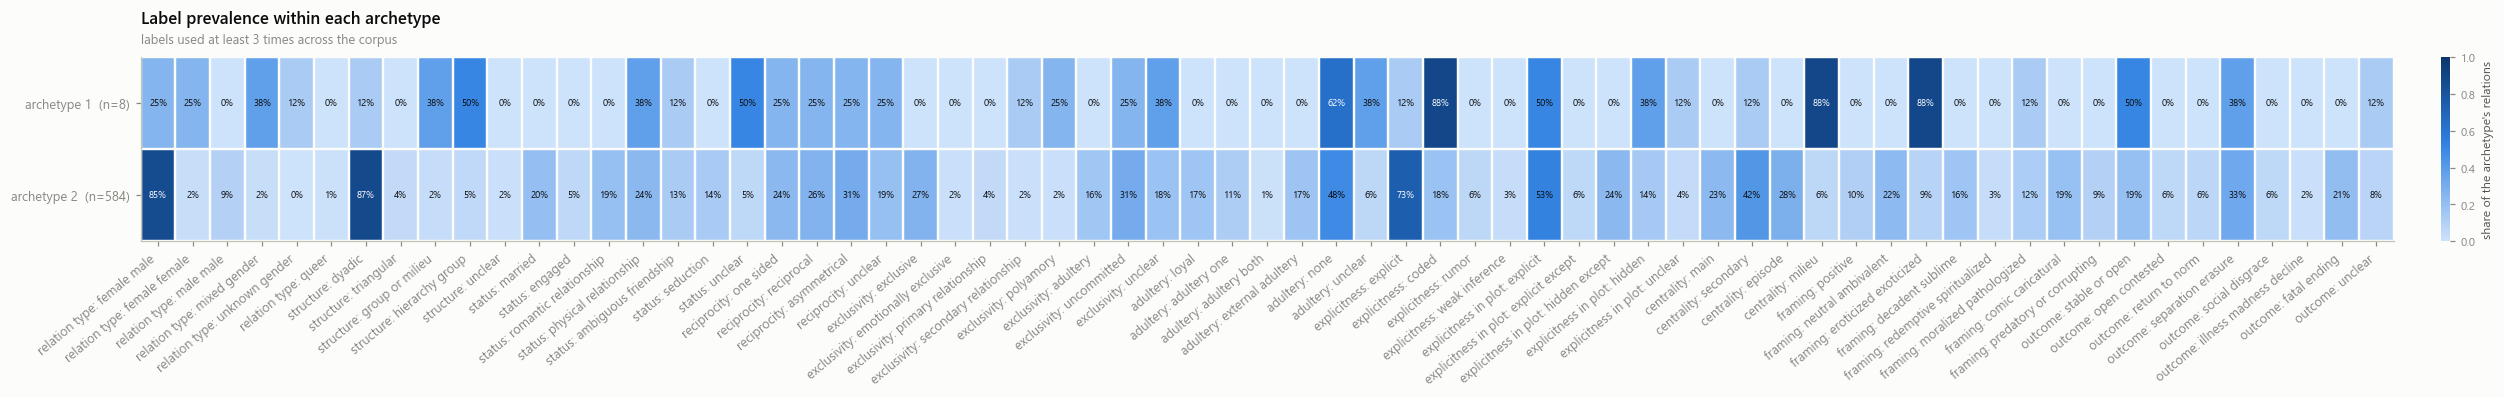

In [84]:
# Modal profile of each archetype
prof = []
for cl, g in relations.groupby("cluster", observed=True):
    row = {"archetype": cl, "n": len(g), "novels": g["novel_id"].nunique()}
    for f in CLUSTER_FIELDS:
        vc = g[f].value_counts()
        vc = vc[vc > 0]
        row[f] = f"{pretty(vc.index[0])} ({vc.iloc[0]/len(g):.0%})" if len(vc) else "—"
    prof.append(row)
profile = pd.DataFrame(prof).set_index("archetype")

note(f"""
### G.2 The {K} archetypes

Each cell gives the **modal label** for that field within the archetype, and the share of the
archetype's relations carrying it. A cluster whose modal shares are all near 100% is a tight,
recurrent configuration; one with shares near 40% is a loose residual group.

A caution on *k*: the silhouette criterion tends to reward isolating a handful of outliers, so a
very small cluster beside two large ones may be an artefact rather than a type. The silhouette
curve above shows what the alternatives score; set `K_OVERRIDE` in the previous cell to cut the
tree at a different number and see whether the archetypes become more interpretable.
""")
display(profile)

# Heatmap of label prevalence by archetype, for labels used at least 3 times
common = [(f, l) for f in CLUSTER_FIELDS for l in observed_levels(f)
          if (relations[f] == l).sum() >= 3]
prev = pd.DataFrame(
    {f"{pretty_field(f)}: {pretty(l)}":
        relations.groupby("cluster", observed=True)[f].apply(lambda s, l=l: (s == l).mean())
     for f, l in common})
fig, ax = plt.subplots(figsize=(0.30 * prev.shape[1] + 3.5, 0.55 * prev.shape[0] + 2.6))
heatmap(prev, ax=ax, cmap=SEQ, vmin=0, vmax=1, fmt="{:.0%}",
        cbar_label="share of the archetype's relations", textsize=6.2)
ax.set_yticks(range(len(prev)), [f"archetype {i}  (n={int((relations['cluster']==i).sum())})"
                                 for i in prev.index])
finish(ax, "Label prevalence within each archetype",
       "labels used at least 3 times across the corpus")
plt.tight_layout(); plt.show()

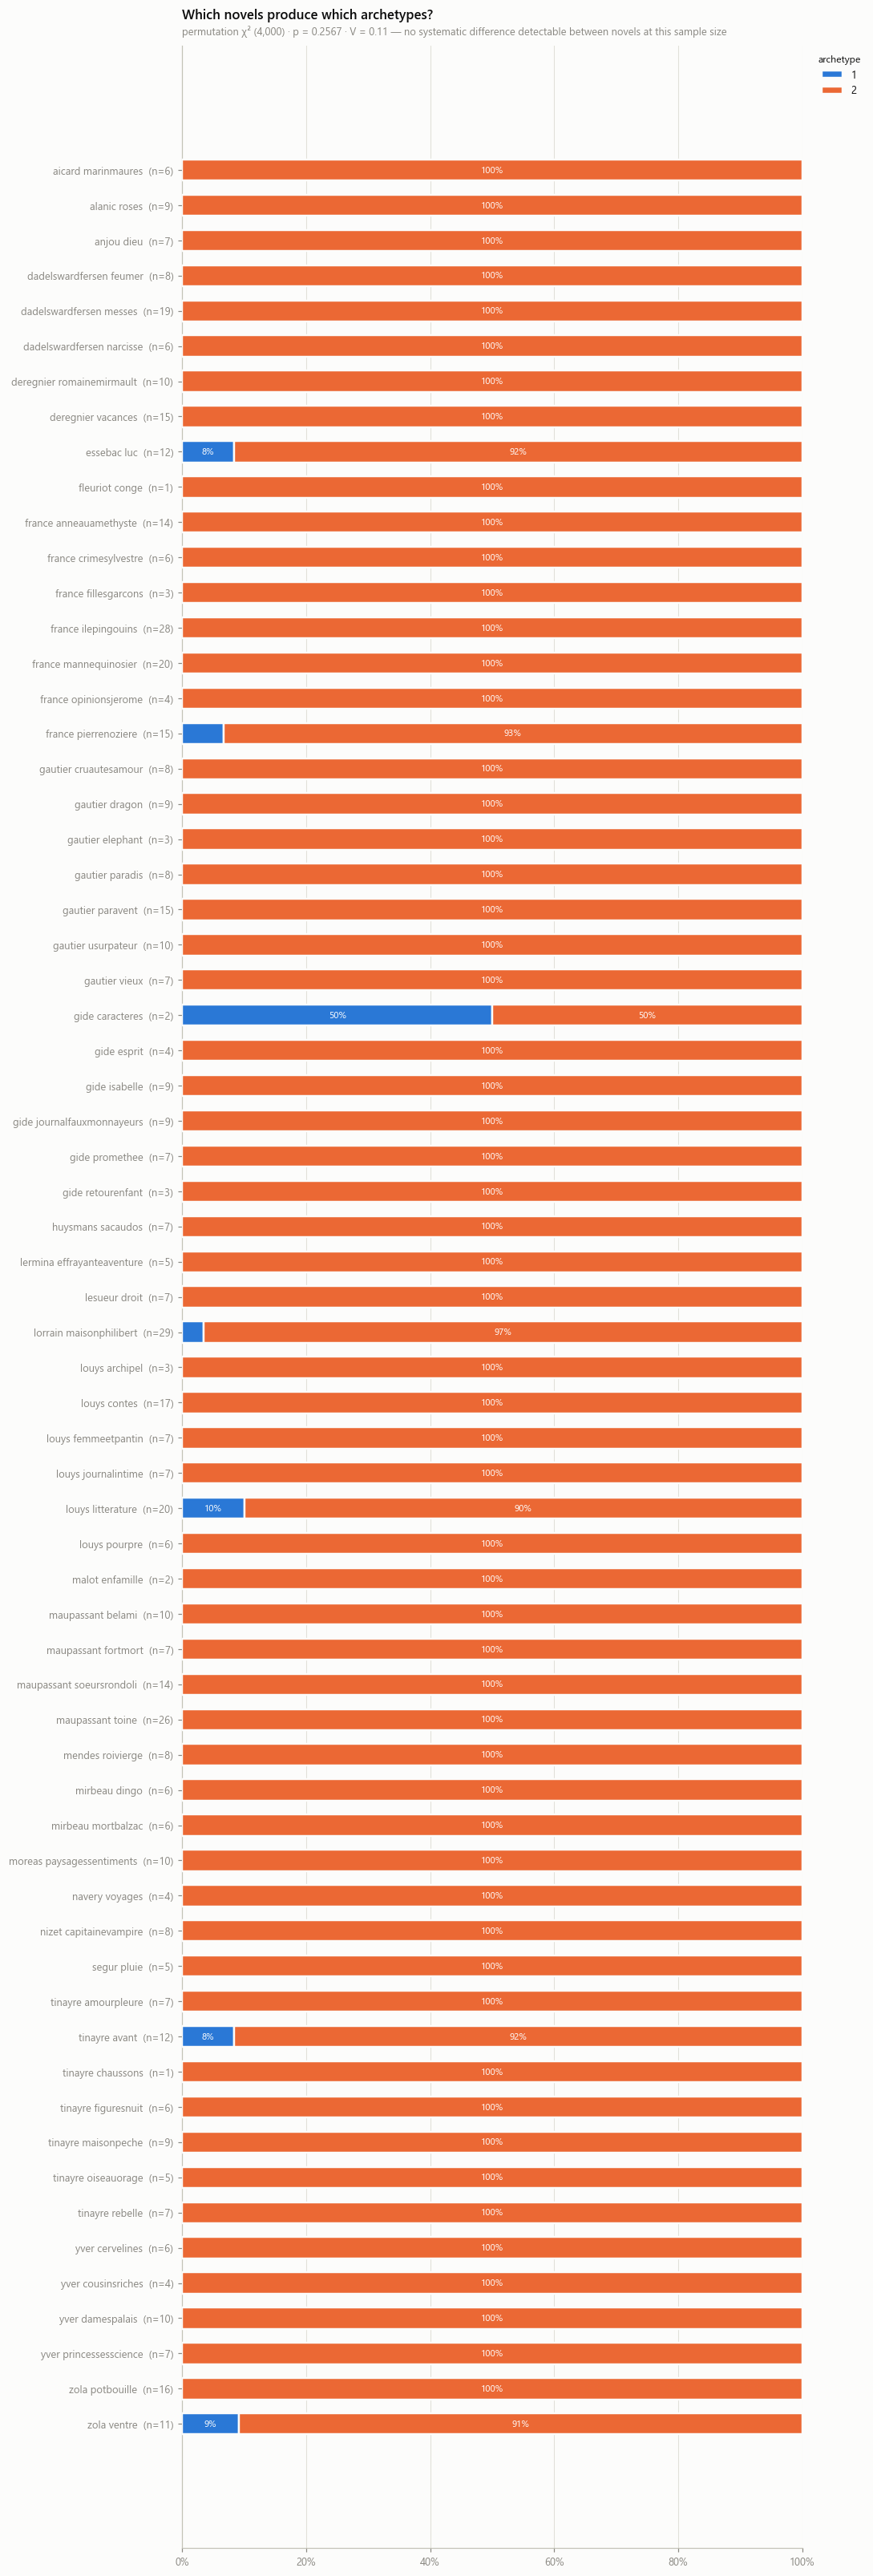


An archetype confined to one or two novels is an idiosyncrasy; one spread across many is a
convention of the material. Here archetype coverage ranges from
**11%** to **100%** of novels
(archetype 2 is the most widely distributed).


In [85]:
# Where do the archetypes come from?
ct_cn = pd.crosstab(relations["novel_id"], relations["cluster"])
fig, ax = plt.subplots(figsize=(10, 0.42 * len(ct_cn) + 2))
stacked_pct(ct_cn, ax=ax, colors=SERIES[:ct_cn.shape[1]])
ax.legend(title="archetype", bbox_to_anchor=(1.01, 1), loc="upper left", title_fontsize=8)
t_cn = assoc_test(relations["novel_id"], relations["cluster"])
finish(ax, "Which novels produce which archetypes?",
       f"{t_cn['test']} · p = {t_cn['p']:.4f} · V = {t_cn['v']:.2f} — "
       f"{'novels differ systematically in the kinds of relation they contain' if t_cn['p'] < .05 else 'no systematic difference detectable between novels at this sample size'}")
plt.tight_layout(); plt.show()

spread = (relations.groupby("cluster", observed=True)["novel_id"].nunique() /
          relations["novel_id"].nunique())
note(f"""
An archetype confined to one or two novels is an idiosyncrasy; one spread across many is a
convention of the material. Here archetype coverage ranges from
**{spread.min():.0%}** to **{spread.max():.0%}** of novels
(archetype {spread.idxmax()} is the most widely distributed).
""")

## H. Novel and author profiles

The corpus is not a bag of 85 independent relations: it is 18 books, 10 of them by one author.
This section makes that structure visible, and then runs the group-comparison engine that §K will
reuse for orientation — on the only grouping the current sample supports.

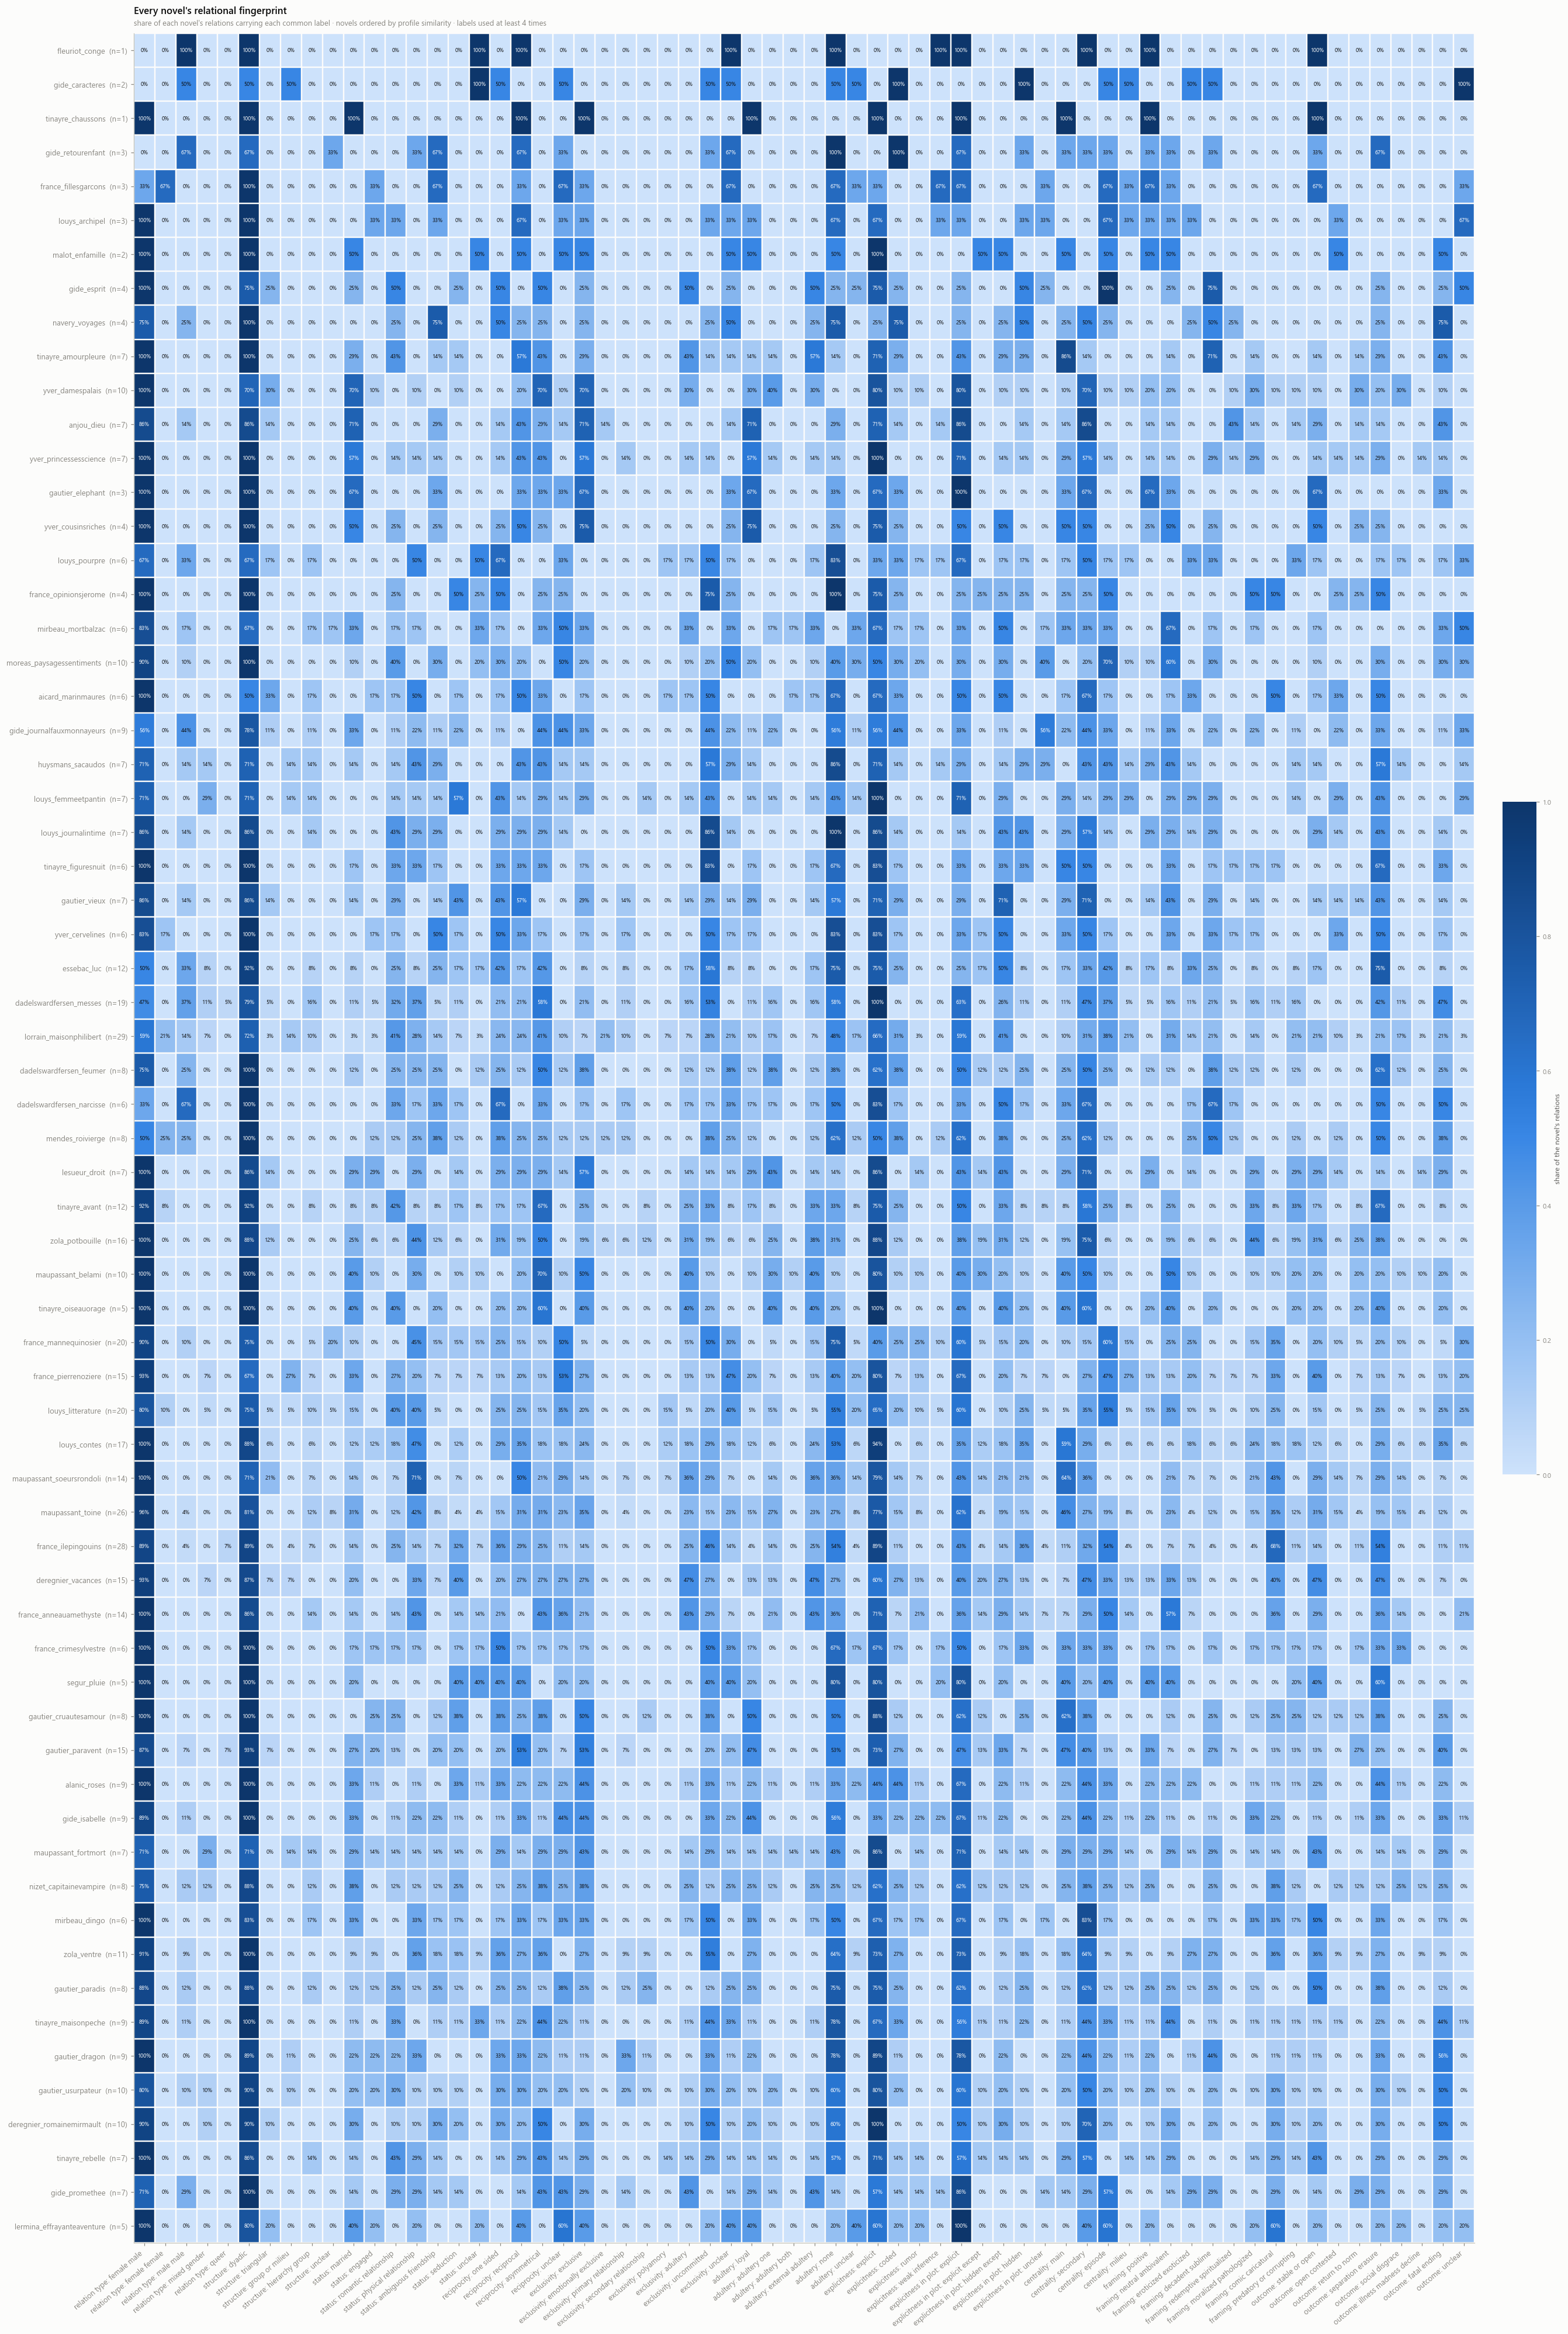

In [86]:
PROFILE_FIELDS = [f for f in ANALYSABLE if f != "confidence"]
common_labels = [(f, l) for f in PROFILE_FIELDS for l in observed_levels(f)
                 if (relations[f] == l).sum() >= 4]
mat = pd.DataFrame(
    {f"{pretty_field(f)}: {pretty(l)}":
        relations.groupby("novel_id", observed=True)[f].apply(lambda s, l=l: (s == l).mean())
     for f, l in common_labels})

if len(mat) >= 3 and mat.shape[1] >= 2:
    # order novels by profile similarity so related books sit together
    order = mat.index[dendrogram(linkage(pdist(mat.fillna(0).values, metric="euclidean"),
                                         method="average"), no_plot=True)["leaves"]]
    mat = mat.loc[order]
    ordered_note = "novels ordered by profile similarity · "
else:
    ordered_note = ""

if len(mat) >= 2 and mat.shape[1] >= 2:
    fig, ax = plt.subplots(figsize=(0.32 * mat.shape[1] + 4, 0.52 * mat.shape[0] + 2.6))
    heatmap(mat, ax=ax, cmap=SEQ, vmin=0, vmax=1, fmt="{:.0%}", textsize=6.2,
            cbar_label="share of the novel's relations")
    ax.set_yticks(range(len(mat)),
                  [f"{i}  (n={int((relations['novel_id'] == i).sum())})" for i in mat.index])
    finish(ax, "Every novel's relational fingerprint",
           "share of each novel's relations carrying each common label · "
           f"{ordered_note}labels used at least 4 times")
    plt.tight_layout(); plt.show()
else:
    note(f"_Novel fingerprint heatmap needs at least two novels with common labels; "
         f"this run has {len(mat)}._")

In [87]:
def log_odds_distinctive(df, group_col, level, fields, prior_weight=1.0):
    """
    Monroe et al. log-odds ratio with an informative Dirichlet prior: which labels are
    over-represented in one group relative to the rest of the corpus, with a z-score that
    is stable when counts are small (which is the whole difficulty here).
    """
    out = []
    ing = df[group_col] == level
    for f in fields:
        for l in observed_levels(f, df):
            y_g = int(((df[f] == l) & ing).sum())
            y_a = int((df[f] == l).sum())
            n_g = int((ing & df[f].notna()).sum())
            n_a = int(df[f].notna().sum())
            a_i = prior_weight * max(y_a, 0.5)
            a_0 = prior_weight * n_a
            if min(n_g, n_a) == 0:
                continue
            num_g = y_g + a_i
            num_a = y_a + a_i
            den_g = n_g + a_0 - num_g
            den_a = n_a + a_0 - num_a
            if min(num_g, num_a, den_g, den_a) <= 0:
                continue
            delta = math.log(num_g / den_g) - math.log(num_a / den_a)
            z = delta / math.sqrt(1 / num_g + 1 / num_a)
            out.append({"field": f, "label": l, "in group": y_g, "group n": n_g,
                        "corpus": y_a, "corpus n": n_a,
                        "group share": y_g / n_g, "corpus share": y_a / n_a,
                        "log-odds δ": delta, "z": z})
    return pd.DataFrame(out).sort_values("z", ascending=False)


def compare_by_group(df, group_col, fields=None, label_map=None, min_group=5,
                     heading="", intro="", cluster="novel_id"):
    """
    The group-comparison engine. Used live on author groups in §H and standing ready for
    `orientation` in §K — same code, so the orientation analysis is tested rather than
    speculative.

    For every field: a contingency table, an effect size, a naive test and a within-novel
    permutation test, all corrected for multiplicity across fields. Then a table of the
    labels that most distinguish each group.
    """
    fields = fields or [f for f in ANALYSABLE if f != "confidence"]
    d = df[df[group_col].notna()].copy()
    counts = d[group_col].value_counts()
    usable = counts[counts >= min_group]

    if heading:
        note(heading + ("\n\n" + intro if intro else ""))

    if len(usable) < 2:
        present = ", ".join(f"`{k}` ({v} relations)" for k, v in counts.items()) or "none"
        note(f"""
> **Not computable yet — only one group is present.**
>
> `{group_col}` currently takes a single usable value in this run: {present}.
> A contrast needs at least two groups of {min_group}+ relations.
>
> Nothing else needs to change when the data arrives. As soon as a run contains novels from a
> second group, this same call produces: a per-field contingency table with Cramér's *V*, a naive
> and a within-novel *p*, Holm and BH corrections across the {len(fields)} fields, a small-multiple
> of stacked composition bars, and a distinctive-label table ranked by log-odds *z*.
""")
        return pd.DataFrame(), pd.DataFrame()

    d = d[d[group_col].isin(usable.index)]
    lm = label_map or {k: k for k in usable.index}

    rows = []
    for f in fields:
        t = assoc_test(d[group_col], d[f])
        p_cl, n_used, n_inf = cluster_permutation_p(d, group_col, f, cluster=cluster)
        rows.append({"field": f, "family": FAMILY_OF[f], "n": t["n"], "V": t["v"],
                     "effect": v_magnitude(t["v"]), "test": t["test"], "p": t["p"],
                     "p (within-novel)": p_cl, "underpowered": t["underpowered"]})
    res = pd.DataFrame(rows)
    res["p Holm"] = holm(res["p"])
    res["q BH"] = bh_fdr(res["p"])
    res = res.sort_values("V", ascending=False)

    display(res.style.format({"V": "{:.3f}", "p": "{:.4f}", "p Holm": "{:.3f}",
                              "q BH": "{:.3f}", "p (within-novel)": "{:.4f}"}, na_rep="—")
            .background_gradient(subset=["V"], cmap=SEQ, vmin=0, vmax=0.6).hide(axis="index"))

    # small multiples: composition per field, by group
    show = res["field"].tolist()
    ncol = 2
    nrow = math.ceil(len(show) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 1.15 * len(usable) * nrow + 1.6 * nrow))
    axes = np.atleast_2d(axes)
    for i, f in enumerate(show):
        ax = axes[i // ncol][i % ncol]
        plot_lab = collapse_rare(d[f], f, max_levels=7)
        ct = pd.crosstab(d[group_col].map(lm), plot_lab)
        ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
        stacked_pct(ct, ax=ax)
        rr = res[res["field"] == f].iloc[0]
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7.5,
                  handlelength=0.8, handleheight=0.8, labelspacing=.45)
        finish(ax, pretty_field(f),
               f"V = {rr['V']:.2f} · p = {rr['p']:.3f} · BH q = {rr['q BH']:.3f}"
               + ("  ·  (!) underpowered" if rr["underpowered"] else ""))
    for j in range(len(show), nrow * ncol):
        axes[j // ncol][j % ncol].set_visible(False)
    plt.tight_layout(); plt.show()

    # distinctive labels for each group
    dist = pd.concat([log_odds_distinctive(d, group_col, lev, fields).assign(group=lm[lev])
                      for lev in usable.index], ignore_index=True)
    top = (dist.sort_values("z", ascending=False)
           .groupby("group", observed=True).head(6)
           .sort_values(["group", "z"], ascending=[True, False]))
    note("**Labels most distinctive of each group** (log-odds with an informative prior; "
         "|z| > 1.96 is the conventional threshold, but read it as a ranking at this *n*):")
    display(top[["group", "field", "label", "in group", "group n", "group share",
                 "corpus share", "log-odds δ", "z"]]
            .style.format({"group share": "{:.0%}", "corpus share": "{:.0%}",
                           "log-odds δ": "{:+.2f}", "z": "{:+.2f}"}).hide(axis="index"))
    return res, dist

print("compare_by_group() ready")

compare_by_group() ready


### H.1 — Pierre Louÿs against the rest of the corpus

Pierre Louÿs contributes 7 of
70 novels and 60 of 592 relations. Before any corpus-level pattern is
attributed to the period, the genre, or the authors' orientation, it has to survive this
contrast: if a "corpus tendency" is really just one prolific author's habit, it will show up
here as a large *V*.

This is the same `compare_by_group` call that §K will make for `orientation` — running it now on
a grouping that exists means the orientation analysis is already tested.

field,family,n,V,effect,test,p,p (within-novel),underpowered,p Holm,q BH
exclusivity,Nature and rules of the bond,592,0.205,moderate,"permutation χ² (4,000)",0.0005,1.0000,True,0.005,0.005
outcome,Representation and narrative role,592,0.148,small,"permutation χ² (4,000)",0.0062,1.0000,True,0.062,0.034
status,Nature and rules of the bond,592,0.107,small,"permutation χ² (4,000)",0.0452,1.0000,True,0.407,0.166
relation_type,Participants and shape,592,0.104,small,"permutation χ² (4,000)",0.1037,1.0000,True,0.622,0.190
explicitness_in_plot,Representation and narrative role,592,0.084,negligible,"permutation χ² (4,000)",0.0867,1.0000,True,0.607,0.190
reciprocity,Nature and rules of the bond,592,0.083,negligible,χ² asymptotic,0.0689,1.0000,False,0.551,0.189
adultery,Nature and rules of the bond,592,0.077,negligible,"permutation χ² (4,000)",0.1327,1.0000,True,0.664,0.209
explicitness,Representation and narrative role,592,0.025,negligible,"permutation χ² (4,000)",0.3177,1.0000,True,1.000,0.437
framing,Representation and narrative role,592,0.016,negligible,"permutation χ² (4,000)",0.4241,1.0000,True,1.000,0.518
structure,Participants and shape,592,0.000,negligible,"permutation χ² (4,000)",0.5824,1.0000,True,1.000,0.582


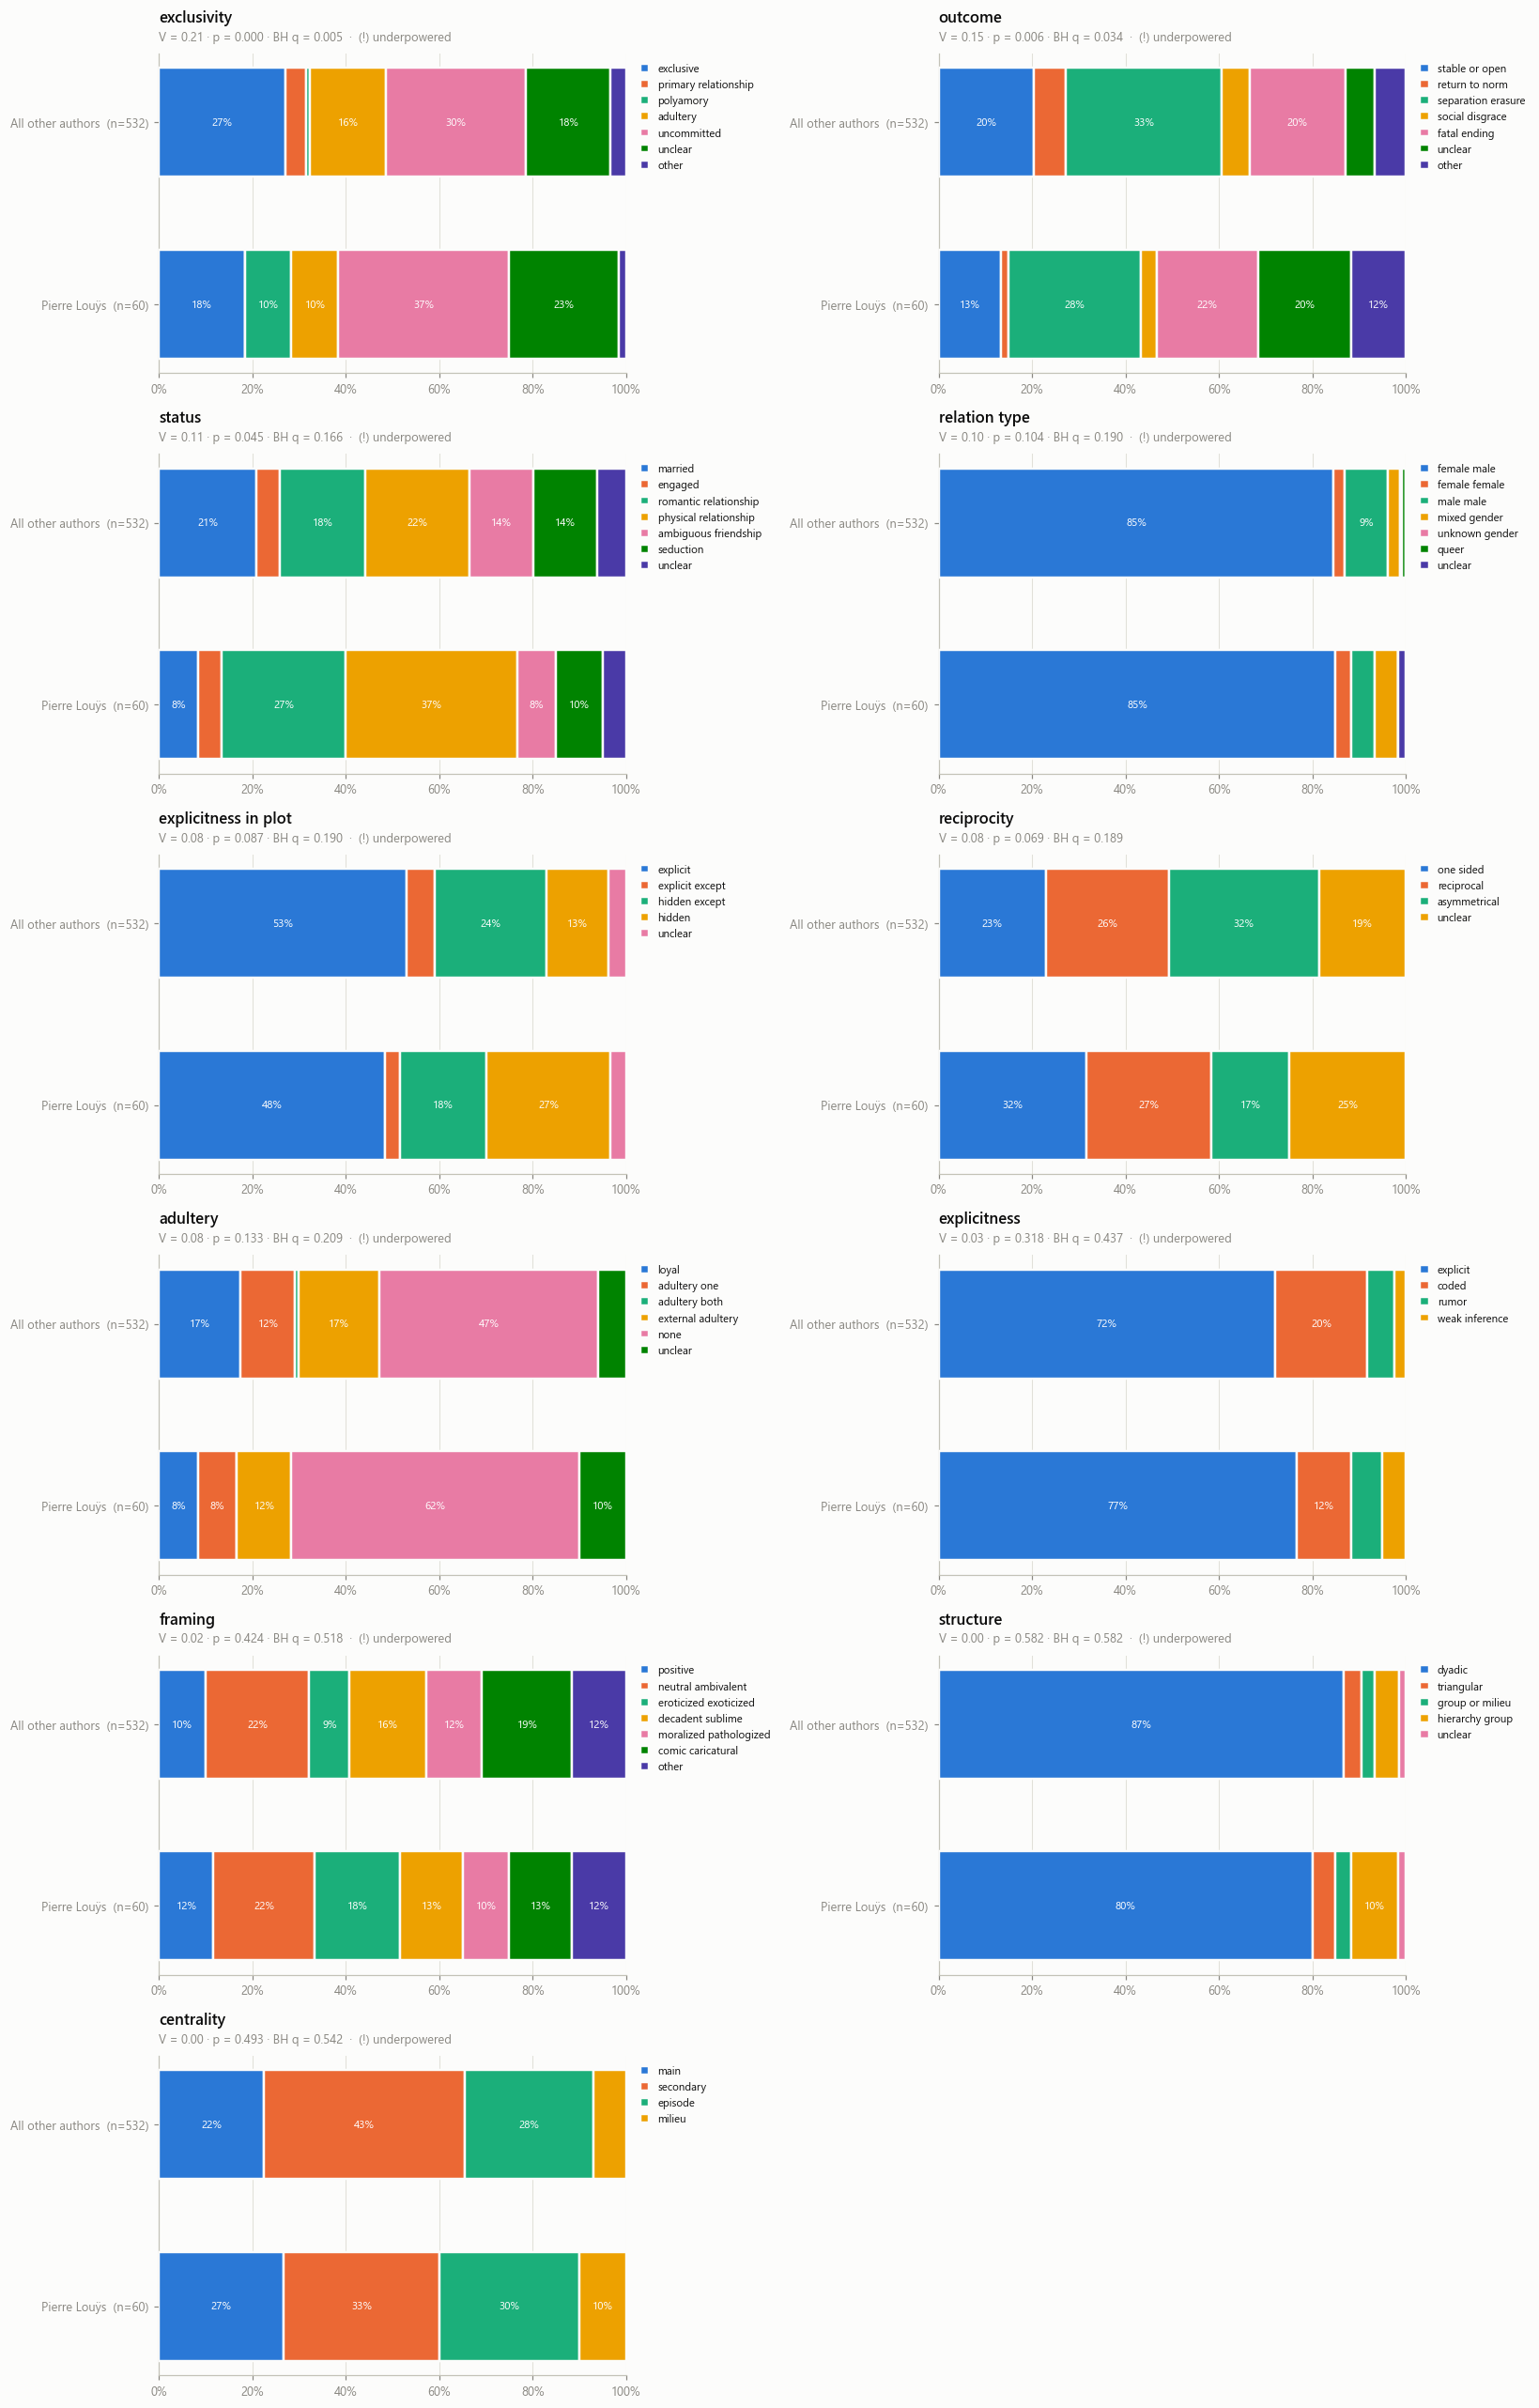

**Labels most distinctive of each group** (log-odds with an informative prior; |z| > 1.96 is the conventional threshold, but read it as a ranking at this *n*):

group,field,label,in group,group n,group share,corpus share,log-odds δ,z
All other authors,structure,dyadic,461,532,87%,86%,+0.03,+0.60
All other authors,reciprocity,asymmetrical,171,532,32%,31%,+0.03,+0.46
All other authors,status,married,111,532,21%,20%,+0.04,+0.40
All other authors,adultery,loyal,93,532,17%,17%,+0.03,+0.31
All other authors,centrality,secondary,229,532,43%,42%,+0.02,+0.30
All other authors,exclusivity,exclusive,144,532,27%,26%,+0.02,+0.27
Pierre Louÿs,exclusivity,polyamory,6,60,10%,2%,+0.35,+1.07
Pierre Louÿs,outcome,unclear,12,60,20%,8%,+0.15,+0.88
Pierre Louÿs,adultery,none,37,60,62%,48%,+0.05,+0.71
Pierre Louÿs,explicitness_in_plot,hidden,16,60,27%,15%,+0.09,+0.69


In [88]:
# The only group contrast the current sample supports: the dominant author against the rest.
top_author = novels["author"].value_counts().idxmax()
relations["author_group"] = np.where(relations["author"] == top_author,
                                     top_author, "All other authors")
n_top = int((relations["author_group"] == top_author).sum())

res_auth, dist_auth = compare_by_group(
    relations, "author_group",
    heading=f"### H.1 — {top_author} against the rest of the corpus",
    intro=f"""{top_author} contributes {int((novels['author'] == top_author).sum())} of
{len(novels)} novels and {n_top} of {N_REL} relations. Before any corpus-level pattern is
attributed to the period, the genre, or the authors' orientation, it has to survive this
contrast: if a "corpus tendency" is really just one prolific author's habit, it will show up
here as a large *V*.

This is the same `compare_by_group` call that §K will make for `orientation` — running it now on
a grouping that exists means the orientation analysis is already tested.""")

In [89]:
sig_auth = res_auth[res_auth["q BH"] < ALPHA] if len(res_auth) else pd.DataFrame()
if not len(res_auth):
    note(f"""
> **No author contrast available in this run.** Every novel is by the same author
> (`{top_author}`), so there is no second group to compare against. The cell above states what
> the comparison will produce once the corpus contains more than one author.
""")
else:
    note(f"""
**Interpretation.** {'On ' + str(len(sig_auth)) + ' of ' + str(len(res_auth)) + ' fields the two author groups differ significantly after BH correction (' + ', '.join(f"`{f}`" for f in sig_auth['field']) + '). Those fields are **confounded with authorship** in the current sample: a corpus-level statement about them is really a statement about ' + top_author + '.' if len(sig_auth) else 'No field separates the two author groups after BH correction. That is reassuring for the corpus-level statistics above — at this sample size the dominant author is not visibly pulling the distributions — but it is a weak conclusion, since with ' + str(len(res_auth)) + ' tests at n = ' + str(N_REL) + ' only a large difference would be detected.'}

The strongest difference, significant or not, is
**{res_auth.iloc[0]['field']}** (V = {res_auth.iloc[0]['V']:.2f},
{res_auth.iloc[0]['effect']}, p = {res_auth.iloc[0]['p']:.3f}).
""")


**Interpretation.** On 2 of 11 fields the two author groups differ significantly after BH correction (`exclusivity`, `outcome`). Those fields are **confounded with authorship** in the current sample: a corpus-level statement about them is really a statement about Pierre Louÿs.

The strongest difference, significant or not, is
**exclusivity** (V = 0.21,
moderate, p = 0.000).


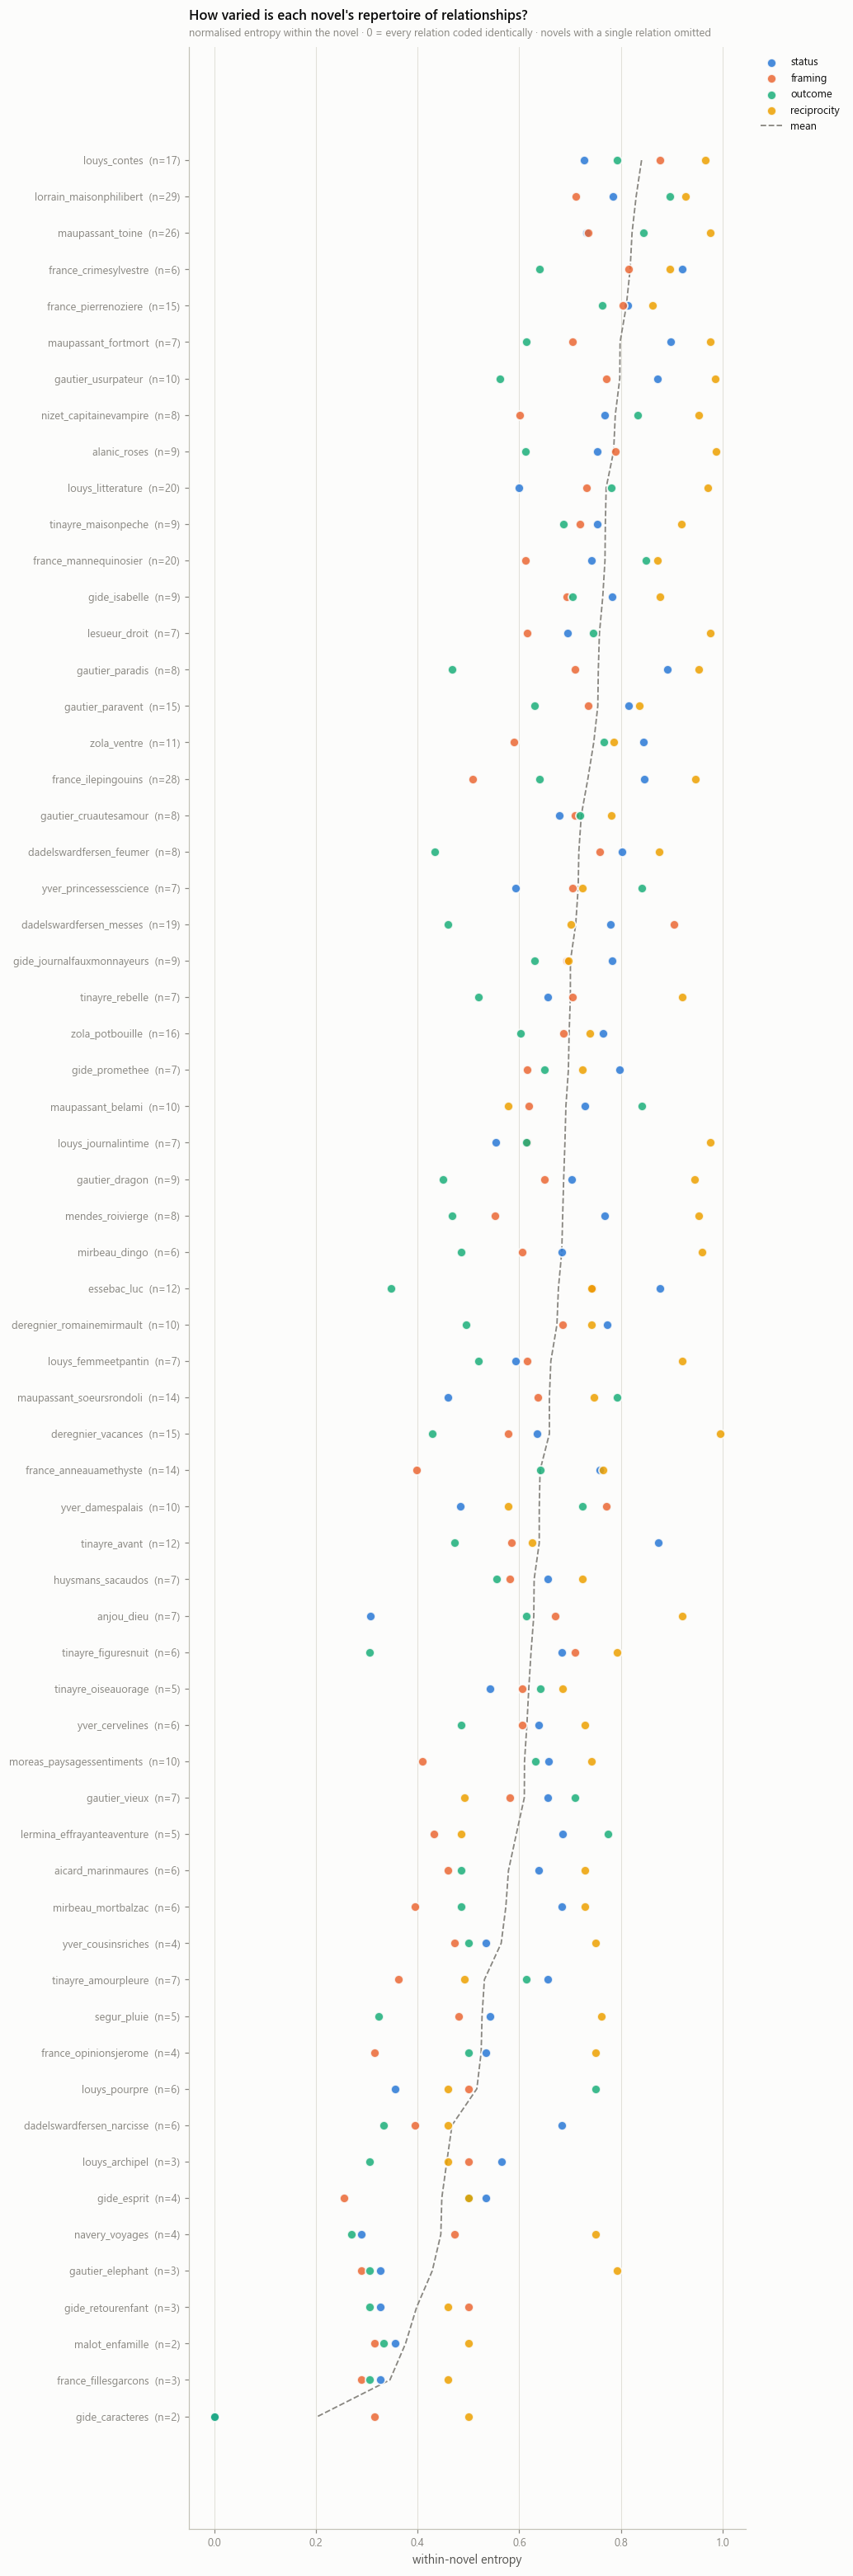


### H.2 — Monotonous and varied books

**louys_contes** has the most internally varied set of relations
(mean entropy 0.84), **gide_caracteres** the most uniform
(0.20). A low value means the book repeats one kind of relationship;
a high one means it stages several different kinds. This is also a diagnostic for the annotator —
a novel where every relation received identical codings deserves a look, since real novels rarely
work that way.


In [90]:
# How internally varied is each novel's repertoire of relations?
rep = pd.DataFrame({
    f: relations.groupby("novel_id", observed=True)[f].apply(lambda s, f=f: norm_entropy(s, f))
    for f in ["status", "framing", "outcome", "reciprocity"]})
rep["relations"] = relations.groupby("novel_id", observed=True).size()
rep["mean entropy"] = rep[["status", "framing", "outcome", "reciprocity"]].mean(axis=1)
rep = rep[rep["relations"] >= 2].sort_values("mean entropy")

if len(rep) < 2:
    note(f"_Within-novel repertoire entropy needs at least two novels carrying two or more "
         f"relations; this run has {len(rep)}._")
else:
    fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(rep) + 2))
    y = np.arange(len(rep))
    for i, f in enumerate(["status", "framing", "outcome", "reciprocity"]):
        ax.scatter(rep[f], y, s=52, color=SERIES[i], label=pretty_field(f), alpha=.85,
                   edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.plot(rep["mean entropy"], y, color=MUTED, linewidth=1.2, linestyle="--", zorder=2,
            label="mean")
    ax.set_yticks(y, [f"{i}  (n={int(n)})" for i, n in zip(rep.index, rep["relations"])])
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.grid(axis="y", visible=False)
    finish(ax, "How varied is each novel's repertoire of relationships?",
           "normalised entropy within the novel · 0 = every relation coded identically · "
           "novels with a single relation omitted",
           xlabel="within-novel entropy")
    plt.tight_layout(); plt.show()

    note(f"""
### H.2 — Monotonous and varied books

**{rep.index[-1]}** has the most internally varied set of relations
(mean entropy {rep['mean entropy'].iloc[-1]:.2f}), **{rep.index[0]}** the most uniform
({rep['mean entropy'].iloc[0]:.2f}). A low value means the book repeats one kind of relationship;
a high one means it stages several different kinds. This is also a diagnostic for the annotator —
a novel where every relation received identical codings deserves a look, since real novels rarely
work that way.
""")

## I. Evidence, characters and commentary

Three text-level views that the closed fields cannot give: who recurs across relations, how the
evidence is written, and what vocabulary the annotator reaches for when it justifies a framing.

In [ ]:
# --- characters recurring across several relations
char_rows = []
for r in relations.itertuples():
    for c in (r.characters or "").split(" | "):
        c = c.strip()
        if c:
            char_rows.append({"novel_id": r.novel_id, "character": c, "uid": r.uid,
                              "status": r.status, "framing": r.framing,
                              "reciprocity": r.reciprocity})
chars = pd.DataFrame(char_rows)

hubs = (chars.groupby(["novel_id", "character"], observed=True)
        .agg(relations=("uid", "nunique"),
             statuses=("status", lambda s: ", ".join(sorted({str(x) for x in s}))),
             framings=("framing", lambda s: ", ".join(sorted({str(x) for x in s}))))
        .reset_index())
hubs = hubs[hubs["relations"] >= 2].sort_values("relations", ascending=False)

note(f"""
### I.1 Characters at the centre of several relationships

{len(chars)} character mentions resolve to {chars.groupby(['novel_id','character']).ngroups}
distinct characters across {chars['novel_id'].nunique()} novels
(the {len(empty)} relations with an empty `characters` array contribute nothing here — see §C.2).

**{len(hubs)} characters appear in two or more relations.** These are the structural centres of
their novels: the seducer with several conquests, the wife with a husband and a lover, the
character every plot line passes through.
""")
display(hubs.head(25).style.hide(axis="index"))

In [ ]:
# --- character networks for the richest novels
try:
    import networkx as nx
    HAVE_NX = True
except ImportError:
    HAVE_NX = False

pairs_df = relations[relations["n_characters"] == 2].copy()
pairs_df[["char_a", "char_b"]] = pairs_df["characters"].str.split(" | ", regex=False, expand=True)
top_novels = (pairs_df.groupby("novel_id", observed=True).size()
              .sort_values(ascending=False).head(4).index.tolist())

if HAVE_NX and top_novels:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    for ax, nid in zip(axes.ravel(), top_novels):
        sub = pairs_df[pairs_df["novel_id"] == nid]
        G = nx.Graph()
        for r in sub.itertuples():
            G.add_edge(r.char_a, r.char_b, status=str(r.status), framing=str(r.framing))
        pos = nx.spring_layout(G, seed=7, k=1.1)
        deg = dict(G.degree())
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color=AXIS, width=1.6)
        nx.draw_networkx_nodes(G, pos, ax=ax,
                               node_size=[260 + 220 * deg[n] for n in G.nodes],
                               node_color=[SERIES[0] if deg[n] == 1 else SERIES[1]
                                           for n in G.nodes],
                               edgecolors=SURFACE, linewidths=2)
        nx.draw_networkx_labels(G, pos, ax=ax,
                                labels={n: textwrap.fill(n, 16) for n in G.nodes},
                                font_size=7, font_color=INK)
        nx.draw_networkx_edge_labels(
            G, pos, ax=ax, font_size=6, font_color=INK_2, bbox=dict(alpha=0),
            edge_labels={(u, v): pretty(d["status"]) for u, v, d in G.edges(data=True)})
        ax.set_axis_off()
        finish(ax, f"{nid}",
               f"{G.number_of_nodes()} characters, {G.number_of_edges()} relations · "
               f"orange = involved in more than one")
    for ax in axes.ravel()[len(top_novels):]:
        ax.set_visible(False)
    fig.suptitle("Relationship networks of the four richest novels", x=0.005, ha="left",
                 fontsize=14, fontweight="semibold", color=INK)
    plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()
else:
    note("_networkx unavailable or no two-character relations — network figure skipped._")

In [ ]:
# --- distinctive vocabulary of the annotator's comments, by framing
from sklearn.feature_extraction.text import TfidfVectorizer

# The comments are written in a mix of French and English, so both stopword lists are needed,
# plus the domain words every comment contains by construction ("relation", "novel", …) which
# would otherwise dominate every column.
STOPWORDS = """
au aux avec ce ces dans de des du elle en et eux il ils je la le les leur lui ma mais me même mes
moi mon ne nos notre nous on ou par pas pour qu que qui sa se ses son sur ta te tes toi ton tu un
une vos votre vous à été étée étées étés étant suis es est sommes êtes sont sera serai seras
serez serons seront serait seraient était étaient fut furent soit soient ai as avons avez ont
aura auront avait avaient eu eue eues eus plus très bien tout toute tous toutes cette cet leurs
autre autres aussi comme dont où quand lors ainsi entre sans sous vers chez alors donc car ni or
si non oui deux afin sorte etc peu fois encore déjà cela celle celui ceux dès puis quoi tant
the and for that with this from are was were has have had not but its his her she they them their
their you your our all any been being both each into more most other some such than then there
these those through under over while who whom which what when where how why can could would
should will shall may might must does did done being also only own same too very just
relation relations roman romans novel novels personnage personnages character characters texte
text récit narration histoire story chapitre chapter partie part fin début end beginning
presented présentée présenté est-elle rapport""".split()

com = relations.dropna(subset=["comment"]).copy()
com = com[com["comment"].str.len() > 20]
groups_ok = com["framing"].value_counts()
groups_ok = groups_ok[groups_ok >= 3].index.tolist()
com = com[com["framing"].isin(groups_ok)]

if len(com) >= 10 and len(groups_ok) >= 2:
    docs = (com.groupby("framing", observed=True)["comment"]
            .apply(lambda s: " ".join(s)).reindex(groups_ok))
    vec = TfidfVectorizer(stop_words=STOPWORDS, sublinear_tf=True,
                          min_df=1, max_df=0.7, token_pattern=r"(?u)\b[^\W\d_]{4,}\b")
    X = vec.fit_transform(docs.values)
    terms = np.array(vec.get_feature_names_out())
    top_terms = pd.DataFrame({
        pretty(g): [f"{terms[i]} ({X[r, i]:.2f})"
                    for i in np.argsort(X[r].toarray().ravel())[::-1][:10]]
        for r, g in enumerate(docs.index)})
    note(f"""
### I.2 What vocabulary does each framing attract?

The `comment` field is free prose written by the annotator to justify its coding. Pooling the
comments per framing and scoring terms by TF-IDF shows which vocabulary each framing pulls in — a
way of checking that the framing labels are being applied along the lines the codebook intends
rather than blurred together. Based on {len(com)} comments across {len(groups_ok)} framings with
at least three comments each.

Note that the annotator writes in **both French and English**, sometimes within the same run, so
the stopword list covers both. That inconsistency is itself worth knowing about: it means any
downstream text analysis of the comments has to be bilingual, and it would be cheaper to fix in
the prompt.
""")
    display(top_terms)
else:
    note("_Too few comments per framing for a meaningful term analysis in this run._")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

ax = axes[0]
for i, l in enumerate([l for l in LEVELS["confidence"] if (relations["confidence"] == l).any()]):
    v = relations.loc[relations["confidence"] == l, "comment_len"]
    ax.scatter(v, np.full(len(v), i) + RNG.normal(0, .08, len(v)), s=34, color=SERIES[i],
               alpha=.75, edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.scatter([v.median()], [i], marker="|", s=600, color=INK, zorder=4, linewidth=2)
lv = [l for l in LEVELS["confidence"] if (relations["confidence"] == l).any()]
ax.set_yticks(range(len(lv)), [f"{pretty(l)} (n={int((relations['confidence']==l).sum())})"
                               for l in lv])
ax.grid(axis="y", visible=False)
rho_c, p_c = stats.spearmanr(relations["confidence"].cat.codes, relations["comment_len"])
finish(ax, "Comment length by stated confidence",
       f"Spearman ρ = {rho_c:.2f}, p = {p_c:.3f} · vertical bar = median",
       xlabel="characters in the comment")

ax = axes[1]
ax.scatter(relations["n_evidence"] + RNG.normal(0, .07, len(relations)),
           relations["comment_len"], s=44, color=SERIES[0], alpha=.8,
           edgecolor=SURFACE, linewidth=1.1, zorder=3)
rho_e, p_e = stats.spearmanr(relations["n_evidence"], relations["comment_len"])
finish(ax, "Evidence count against comment length",
       f"Spearman ρ = {rho_e:.2f}, p = {p_e:.3f} — "
       f"{'the annotator elaborates and evidences together' if p_e < .05 and rho_e > 0 else 'evidence volume and prose length are independent'}",
       xlabel="evidence items", ylabel="comment length (characters)")
plt.tight_layout(); plt.show()

## J. Cost and token analytics

Practical planning numbers, taken from the `usage` block each OpenRouter response carries. The
corpus is currently 18 of the 368 novels in `corpus_chr_metadata.csv`, so the marginal cost per
novel determines what finishing it will take.

In [ ]:
u = novels.dropna(subset=["cost_usd"]).copy()
u["cost_per_relation"] = u["cost_usd"] / u["n_relations"].replace(0, np.nan)
u["cache_hit"] = u["cached_tokens"].fillna(0) / u["prompt_tokens"].replace(0, np.nan)
u["reasoning_share"] = u["reasoning_tokens"].fillna(0) / u["completion_tokens"].replace(0, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
d = u.sort_values("cost_usd")
y = np.arange(len(d))
ax.barh(y, d["cost_usd"], height=0.62,
        color=[SERIES[7] if not ok else SERIES[0] for ok in d["ok"]], zorder=3)
ax.set_yticks(y, d["novel_id"])
for yi, v in zip(y, d["cost_usd"]):
    ax.text(v + d["cost_usd"].max() * .015, yi, f"${v:.3f}", va="center", fontsize=7.5,
            color=INK_2)
ax.set_xlim(0, d["cost_usd"].max() * 1.25)
ax.grid(axis="y", visible=False)
finish(ax, "Cost per novel", "red = the record failed validation", xlabel="USD")

ax = axes[1]
ax.scatter(u["k_chars"], u["cost_usd"], s=70,
           c=[SEQ(x) for x in np.clip(u["cache_hit"].fillna(0), 0, 1)],
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
finish(ax, "Input size against cost",
       "colour = prompt-cache hit rate (darker = better cached); the spread at equal length "
       "is almost entirely caching",
       xlabel="input (thousand characters)", ylabel="USD")

ax = axes[2]
ax.scatter(u["reasoning_share"].fillna(0), u["cost_usd"], s=70, color=SERIES[1],
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
finish(ax, "Reasoning tokens against cost",
       "share of completion tokens spent on hidden reasoning",
       xlabel="reasoning share of completion", ylabel="USD")
plt.tight_layout(); plt.show()

In [ ]:
total_cost = u["cost_usd"].sum()
per_novel = u["cost_usd"].mean()
per_rel = total_cost / N_REL

full = pd.read_csv(METADATA_PATH) if METADATA_PATH.exists() else None
n_full = len(full) if full is not None else np.nan
remaining = (n_full - len(novels)) if full is not None else np.nan

summary_cost = pd.DataFrame({
    "metric": ["novels annotated", "total cost", "mean cost / novel", "median cost / novel",
               "cost / relation", "total tokens", "mean prompt-cache hit rate",
               "mean reasoning share of completion"],
    "value": [len(u), f"${total_cost:.2f}", f"${per_novel:.3f}",
              f"${u['cost_usd'].median():.3f}", f"${per_rel:.3f}",
              f"{u['total_tokens'].sum():,.0f}",
              f"{u['cache_hit'].mean():.0%}", f"{u['reasoning_share'].mean():.0%}"],
})
display(summary_cost.style.hide(axis="index"))

if full is not None:
    by_or = full["orientation"].value_counts().reindex(ORIENTATION_ORDER).dropna()
    proj = pd.DataFrame({
        "novels in corpus": by_or,
        "already annotated": [int((novels["orientation"] == o).sum()) for o in by_or.index],
    })
    proj["remaining"] = proj["novels in corpus"] - proj["already annotated"]
    proj["projected cost"] = proj["remaining"] * per_novel
    proj.index = [ORIENTATION_LABELS.get(i, i) for i in proj.index]
    proj.loc["TOTAL"] = proj.sum()

    note(f"""
### J.1 What will the full corpus cost?

`corpus_chr_metadata.csv` lists **{n_full} novels**; **{len(novels)}** are annotated, leaving
**{int(remaining)}**. At the observed mean of **${per_novel:.3f} per novel** the remainder
projects to roughly **${remaining * per_novel:.0f}**.

Two caveats make that a floor rather than an estimate. The mean is computed over novels averaging
{u['k_chars'].mean():.0f}k characters, and cost scales with input length — a longer subcorpus
costs more. And the prompt-cache hit rate here averages {u['cache_hit'].mean():.0%}; runs
processing novels back to back with a warm cache come in materially cheaper, which is a
scheduling decision rather than a fixed cost.
""")
    display(proj.style.format({"projected cost": "${:,.0f}", "novels in corpus": "{:.0f}",
                               "already annotated": "{:.0f}", "remaining": "{:.0f}"}))

## K. The orientation contrast

This is the comparison the corpus exists to make: do novels by lesbian, gay, heterosexual-women
and heterosexual-men authors stage relationships differently — in kind, in reciprocity, in
framing, in how they end?

It cannot be run yet. Every novel in this run is `hetero`. Rather than leave a gap, the analysis
is written and wired up: the cell below is the real call, and it will produce the full comparison
the moment a run contains a second group. Section H.1 exercises the identical code path on author
groups, so this is tested machinery, not a placeholder.

In [ ]:
res_or, dist_or = compare_by_group(
    relations, "orientation",
    label_map=ORIENTATION_LABELS,
    heading="### K.1 — Relationship coding by author orientation",
    intro="""Author orientation as recorded by the corpus directory structure:
`lesbiennes` = lesbian authors, `hetero` = heterosexual women authors,
`homosexuels` = gay men authors, `homhet` = heterosexual men authors.""")

In [ ]:
# The orientation-coloured MCA, ready for the same moment.
if relations["orientation"].nunique() >= 2:
    fig, ax = plt.subplots(figsize=(9, 7))
    for i, o in enumerate([o for o in ORIENTATION_ORDER
                           if o in relations["orientation"].unique()]):
        m = (relations["orientation"] == o).values
        ax.scatter(F_rel.loc[m, "dim1"], F_rel.loc[m, "dim2"], s=62, color=SERIES[i],
                   label=ORIENTATION_LABELS.get(o, o), alpha=.85,
                   edgecolor=SURFACE, linewidth=1.3, zorder=3)
    ax.axhline(0, color=AXIS, linewidth=.9); ax.axvline(0, color=AXIS, linewidth=.9)
    ax.legend(title="author orientation", title_fontsize=8)
    finish(ax, "Relational space by author orientation",
           f"MCA dimensions 1–2 · {expl[0]:.0%} and {expl[1]:.0%} of corrected inertia",
           xlabel=f"dim 1  ({expl[0]:.1%})", ylabel=f"dim 2  ({expl[1]:.1%})")
    plt.tight_layout(); plt.show()
else:
    o = relations["orientation"].iloc[0]
    note(f"""
> **MCA by orientation — dormant.** All {N_REL} relations belong to a single group
> (`{o}` — {ORIENTATION_LABELS.get(o, o)}), so there is nothing to separate in the label space.
> With two or more groups this cell draws the §G.1 map again, coloured by orientation: overlapping
> clouds would mean the four author groups write relationships from the same repertoire, and
> separated clouds would mean they do not. That single figure is the corpus's headline result
> once it is complete.
""")

full_meta = pd.read_csv(METADATA_PATH) if METADATA_PATH.exists() else None
if full_meta is not None:
    prog = pd.DataFrame({
        "novels available": full_meta["orientation"].value_counts().reindex(ORIENTATION_ORDER),
        "annotated": [int((novels["orientation"] == o).sum()) for o in ORIENTATION_ORDER],
        "relations": [int((relations["orientation"] == o).sum()) for o in ORIENTATION_ORDER],
    })
    prog["coverage"] = prog["annotated"] / prog["novels available"]
    prog.index = [ORIENTATION_LABELS[o] for o in ORIENTATION_ORDER]

    fig, ax = plt.subplots(figsize=(9, 3.4))
    y = np.arange(len(prog))[::-1]
    ax.barh(y, prog["novels available"], height=0.55, color=ZERO_GREY,
            label="in the corpus", zorder=3)
    ax.barh(y, prog["annotated"], height=0.55, color=SERIES[0], label="annotated", zorder=4)
    ax.set_yticks(y, prog.index)
    for yi, (a, t) in zip(y, zip(prog["annotated"], prog["novels available"])):
        ax.text(t + 3, yi, f"{a}/{t}  ({a/t:.0%})", va="center", fontsize=8, color=INK_2)
    ax.set_xlim(0, prog["novels available"].max() * 1.25)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    finish(ax, "How far off is the orientation comparison?",
           "annotation coverage of each author group in corpus_chr_metadata.csv")
    plt.tight_layout(); plt.show()
    display(prog.style.format({"coverage": "{:.0%}"}, na_rep="—"))

## L. Summary and reproducibility

In [ ]:
findings = pd.DataFrame(FINDINGS)
if len(findings):
    findings["BH q"] = bh_fdr(findings["p"])
    q_sig = findings["BH q"] < ALPHA
    c_sig = findings["p within-novel"] < ALPHA
    findings["verdict"] = np.select(
        [q_sig & c_sig, q_sig & ~c_sig, ~q_sig & c_sig],
        ["supported — survives the clustering correction",
         "supported overall, but novel-driven",
         "suggestive — within-novel test only"],
        default="not established at this sample size")
    note("""
### L.1 — Every question asked in §F, and what the corpus answered

`BH q` corrects across the questions in this table; `p within-novel` is the clustered test.
A question counts as **supported** only when both agree — with 18 novels and one dominant author,
a result that appears in one column and not the other is not yet a finding.
""")
    display(findings[["question", "n", "V", "test", "p", "p within-novel", "BH q", "verdict",
                      "underpowered"]]
            .style.format({"V": "{:.2f}", "p": "{:.4f}", "p within-novel": "{:.4f}",
                           "BH q": "{:.3f}"}, na_rep="—").hide(axis="index"))

In [ ]:
import platform, sys, sklearn, scipy, seaborn as _sns  # noqa: E401

run_sha = hashlib.sha256(RUN_PATH.read_bytes()).hexdigest()[:16] if RUN_PATH.exists() else "—"
env = pd.DataFrame({
    "item": ["run file", "run sha256 (16)", "model(s)", "corpus file", "schema",
             "records", "relations", "evidence items", "orientation groups",
             "analysable fields", "degenerate fields",
             "seed", "permutations", "bootstrap replicates", "alpha",
             "python", "pandas", "numpy", "scipy", "matplotlib", "scikit-learn", "platform"],
    "value": [RUN_PATH.name, run_sha, ", ".join(sorted(novels["model"].dropna().unique())),
              CORPUS_PATH.name, SCHEMA_PATH.name,
              len(novels), N_REL, N_EV,
              ", ".join(sorted(relations["orientation"].dropna().unique())),
              len(ANALYSABLE), ", ".join(DEGENERATE) or "none",
              "20260813", f"{N_PERM:,}", f"{N_BOOT:,}", f"{ALPHA:g}",
              sys.version.split()[0], pd.__version__, np.__version__, scipy.__version__,
              mpl.__version__, sklearn.__version__,
              f"{platform.system()} {platform.release()}"],
})
display(env.style.hide(axis="index"))

note(f"""
### L.2 — To re-run this on a larger corpus

Change `RUN_PATH` in the first cell and run the notebook top to bottom. Nothing else is
hard-coded: the label vocabulary comes from the schema, degenerate fields are detected rather
than listed, and the orientation module activates itself when a second group appears.

Two things will change automatically as the corpus grows, and they are worth watching:

1. **§D's degenerate-field list should shrink.** `relation_type` and `structure` are near-constant
   only because every novel here is by a heterosexual woman author. When the lesbian and gay
   subcorpora arrive, `female_female` and `male_male` enter the data and those fields become the
   most interesting in the grid.
2. **§E's within-novel column should converge on the naive one.** The gap between them is a
   function of how few books there are; with 100+ novels the clustering correction will bite far
   less, and associations that currently look novel-driven can be re-examined.

The two things that will *not* fix themselves are in §C: the {len(bad)} records that failed
validation and the {int((~evidence.loc[ev_q, 'verified']).sum())} unverifiable quotations. Both
are annotation-pipeline problems, and both are listed by `novel_id` and `relation_id` above.
""")